In [1]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
from datasets import load_dataset
skit_dataset = load_dataset("skit-ai/skit-s2i")

/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
skit_dataset

DatasetDict({
    train: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 10445
    })
    test: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 1400
    })
})

In [4]:
%pip install torch torchcodec

Note: you may need to restart the kernel to use updated packages.


In [5]:
from datasets import load_dataset
skit_dataset = load_dataset("skit-ai/skit-s2i")

In [6]:
skit_dataset

DatasetDict({
    train: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 10445
    })
    test: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 1400
    })
})

In [7]:
!conda install -c conda-forge ffmpeg --freeze-installed -y

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
- 

In [8]:
import sys
sys.executable

'/opt/anaconda3/envs/veripay-voice/bin/python'

In [9]:
import datasets
import torch
import torchcodec
datasets.__version__, torch.__version__, torchcodec.__version__

('5.0.1', '2.10.0', '0.10.0a0')

In [10]:
from datasets import load_dataset
skit_dataset = load_dataset("skit-ai/skit-s2i")

In [11]:
skit_dataset["train"][0]

{'audio': <datasets.features._torchcodec.AudioDecoder at 0x70b8b238c0>,
 'intent_class': 6,
 'template': 'Please tell me the IFSC Code ',
 'speaker_id': 3}

In [12]:
sample_audio = skit_dataset["train"][0]["audio"]

In [13]:
sample_audio.get_all_samples()

AudioSamples:
  data (shape): torch.Size([1, 36768])
  pts_seconds: 0.0
  duration_seconds: 4.596
  sample_rate: 8000

In [14]:
#intent distribution

import pandas as pd
pd.Series(
    skit_dataset["train"]["intent_class"]
).value_counts().sort_index()

0     773
1     799
2     732
3     697
4     740
5     668
6     780
7     739
8     956
9     687
10    746
11    654
12    684
13    790
Name: count, dtype: int64

In [15]:
pd.Series(
    skit_dataset["train"]["speaker_id"]
).value_counts().sort_index()

1     1068
2     1264
3      830
4      937
5     1093
6      979
7     1092
8      752
9      306
10     985
11    1139
Name: count, dtype: int64

In [16]:
skit_dataset["train"].features["intent_class"]

Value('int64')

In [17]:
intent_info = pd.read_csv("https://huggingface.co/datasets/skit-ai/skit-s2i/resolve/main/intent_info.csv")

In [18]:
intent_info.head()

,intent_class,intent_name,description
0,0,branch_address,enquiry about bank branch location
1,1,activate_card,enquiry about activating card products
2,2,past_transactions,enquiry about past transactions in a specific ...
3,3,dispatch_status,enquiry about the dispatch status of card prod...
4,4,outstanding_balance,enquiry about outstanding balance on card prod...


In [19]:
intent_info.shape

(14, 3)

In [20]:
intent_info

,intent_class,intent_name,description
0,0,branch_address,enquiry about bank branch location
1,1,activate_card,enquiry about activating card products
2,2,past_transactions,enquiry about past transactions in a specific ...
3,3,dispatch_status,enquiry about the dispatch status of card prod...
4,4,outstanding_balance,enquiry about outstanding balance on card prod...
5,5,card_issue,report about an issue with using card products
6,6,ifsc_code,enquiry about IFSC code of bank branch
7,7,generate_pin,enquiry about changing or generating a new pin...
8,8,unauthorised_transaction,report about an unauthorised or fraudulent tra...
9,9,loan_query,enquiry about different kinds of loans


In [21]:
#speaker overlap

train_speakers = set(
    skit_dataset["train"]["speaker_id"]
)
test_speakers = set(
    skit_dataset["test"]["speaker_id"]
)
train_speakers

{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11}

In [22]:
test_speakers

{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11}

In [23]:
train_speakers.intersection(test_speakers)

{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11}

In [24]:
import sklearn

sklearn.__version__

'1.9.1'

In [25]:
from datasets import load_dataset

skit_dataset = load_dataset("skit-ai/skit-s2i")

In [26]:
skit_dataset

DatasetDict({
    train: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 10445
    })
    test: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 1400
    })
})

In [27]:
#creating a speaker-disjoint validation set

from sklearn.model_selection import GroupShuffleSplit

skit_train_speakers = skit_dataset["train"]["speaker_id"]

In [28]:
skit_train_groupsplit = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

In [29]:
skit_train_idx, skit_val_idx = next(
    skit_train_groupsplit.split(
        range(len(skit_dataset["train"])),
        groups=skit_train_speakers
    )
)

In [30]:
skit_train_split = skit_dataset["train"].select(
    skit_train_idx
)
skit_val_split = skit_dataset["train"].select(
    skit_val_idx
)

In [31]:
skit_train_split.num_rows, skit_val_split.num_rows

(7413, 3032)

In [32]:
set(skit_train_split["speaker_id"])

{2, 3, 4, 5, 7, 8, 9, 11}

In [33]:
set(skit_val_split["speaker_id"])

{1, 6, 10}

In [34]:
set(
    skit_train_split["speaker_id"]
).intersection(
    set(skit_val_split["speaker_id"])
)

set()

In [35]:
#checking intent distribution
import pandas as pd
pd.Series(
    skit_train_split["intent_class"]
).value_counts().sort_index()

0     605
1     571
2     512
3     495
4     527
5     476
6     607
7     466
8     675
9     494
10    474
11    460
12    484
13    567
Name: count, dtype: int64

In [36]:
pd.Series(
    skit_val_split["intent_class"]
).value_counts().sort_index()

0     168
1     228
2     220
3     202
4     213
5     192
6     173
7     273
8     281
9     193
10    272
11    194
12    200
13    223
Name: count, dtype: int64

In [37]:
#test distribution

pd.Series(
    skit_dataset["test"]["intent_class"]
).value_counts().sort_index()

0     100
1     100
2     100
3     100
4     100
5     100
6     100
7     100
8     100
9     100
10    100
11    100
12    100
13    100
Name: count, dtype: int64

In [38]:
skit_label_map = {
    0: "branch_address",
    1: "activate_card",
    2: "past_transactions",
    3: "dispatch_status",
    4: "outstanding_balance",
    5: "card_issue",
    6: "ifsc_code",
    7: "generate_pin",
    8: "unauthorised_transaction",
    9: "loan_query",
    10: "balance_enquiry",
    11: "change_limit",
    12: "block",
    13: "lost"
}

In [39]:
skit_label_map

{0: 'branch_address',
 1: 'activate_card',
 2: 'past_transactions',
 3: 'dispatch_status',
 4: 'outstanding_balance',
 5: 'card_issue',
 6: 'ifsc_code',
 7: 'generate_pin',
 8: 'unauthorised_transaction',
 9: 'loan_query',
 10: 'balance_enquiry',
 11: 'change_limit',
 12: 'block',
 13: 'lost'}

In [40]:
import torch
import torchaudio
torch.__version__, torchaudio.__version__

('2.10.0', '2.10.0')

In [41]:
#extract MFCCs from one audio sample

sample_audio = skit_dataset["train"][0]["audio"]
audio_samples = sample_audio.get_all_samples()

waveform = audio_samples.data
sample_rate = audio_samples.sample_rate

waveform.shape, sample_rate

(torch.Size([1, 36768]), 8000)

In [42]:
#MFCC extractor

mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=sample_rate,
    n_mfcc=13,
    melkwargs={
        "n_fft": 400,
        "hop_length": 160,
        "n_mels": 40
    }
)

In [43]:
mfcc_features = mfcc_transform(waveform)
mfcc_features.shape

torch.Size([1, 13, 230])

In [44]:
#converting MFCCs into a fixed-length feature vector

mfcc_mean = mfcc_features.mean(dim=2).squeeze(0)
mfcc_std = mfcc_features.std(dim=2).squeeze(0)
mfcc_vector = torch.cat(
    [mfcc_mean, mfcc_std]
)
mfcc_vector.shape

torch.Size([26])

In [45]:
mfcc_vector

tensor([-221.3851,    2.7608,   -3.4754,  -10.4589,  -10.0365,   -4.4076,
          -7.3934,   -0.5928,   -3.2157,   -1.0990,   -4.1119,   -0.2259,
           1.0152,  125.5072,   14.1832,   17.8711,   14.3663,   13.7083,
           7.2676,   10.5377,    4.5798,    6.5511,    4.2334,    6.9953,
           5.9344,    4.4919])

In [46]:
#reusable MFCC extraction function

def extract_mfcc_features(audio):
    audio_samples = audio.get_all_samples()
    waveform = audio_samples.data
    sample_rate = audio_samples.sample_rate

    mfcc_features = torchaudio.transforms.MFCC(
        sample_rate=sample_rate,
        n_mfcc=13,
        melkwargs={
            "n_fft": 400,
            "hop_length": 160,
            "n_mels": 40
        }
    )(waveform)
    mfcc_mean = mfcc_features.mean(dim=2).squeeze(0)
    mfcc_std = mfcc_features.std(dim=2).squeeze(0)
    mfcc_vector = torch.cat(
        [mfcc_mean, mfcc_std]
    )
    return mfcc_vector.numpy()

In [47]:
test_mfcc_vector = extract_mfcc_features(
    skit_dataset["train"][0]["audio"]
)

test_mfcc_vector.shape

(26,)

In [48]:
#Extract training features

from tqdm.auto import tqdm
skit_train_features = []
for sample in tqdm(
    skit_train_split,
    total=skit_train_split.num_rows
):
    skit_train_features.append(
        extract_mfcc_features(sample["audio"])
    )

100%|█████████████████████████████████████| 7413/7413 [00:15<00:00, 488.58it/s]


In [49]:
import numpy as np
skit_train_features = np.array(
    skit_train_features
)
skit_train_features.shape

(7413, 26)

In [50]:
#extract validation features

skit_val_features = []
for sample in tqdm(
    skit_val_split,
    total=skit_val_split.num_rows
):
    skit_val_features.append(
        extract_mfcc_features(sample["audio"])
    )

100%|█████████████████████████████████████| 3032/3032 [00:06<00:00, 472.44it/s]


In [51]:
skit_val_features = np.array(
    skit_val_features
)
skit_val_features.shape

(3032, 26)

In [52]:
#test features

skit_test_features = []
for sample in tqdm(
    skit_dataset["test"],
    total=skit_dataset["test"].num_rows
):
    skit_test_features.append(
        extract_mfcc_features(sample["audio"])
    )

100%|█████████████████████████████████████| 1400/1400 [00:02<00:00, 476.36it/s]


In [53]:
skit_test_features = np.array(
    skit_test_features
)
skit_test_features.shape

(1400, 26)

In [54]:
skit_train_labels = np.array(
    skit_train_split["intent_class"]
)
skit_val_labels = np.array(
    skit_val_split["intent_class"]
)
skit_test_labels = np.array(
    skit_dataset["test"]["intent_class"]
)

In [55]:
skit_train_labels.shape, skit_val_labels.shape, skit_test_labels.shape

((7413,), (3032,), (1400,))

In [56]:
np.unique(skit_train_labels)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13])

In [57]:
#scaling the MFCC features

from sklearn.preprocessing import StandardScaler

skit_scaler = StandardScaler()
skit_train_scaled = skit_scaler.fit_transform(
    skit_train_features
)
skit_val_scaled = skit_scaler.transform(
    skit_val_features
)

In [58]:
skit_train_scaled.shape, skit_val_scaled.shape

((7413, 26), (3032, 26))

In [59]:
from sklearn.linear_model import LogisticRegression

skit_lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
skit_lr_model.fit(
    skit_train_scaled,
    skit_train_labels
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [60]:
skit_val_pred_lr = skit_lr_model.predict(
    skit_val_scaled
)

In [61]:
#accuracy

from sklearn.metrics import accuracy_score

skit_lr_accuracy = accuracy_score(
    skit_val_labels,
    skit_val_pred_lr
)
skit_lr_accuracy

0.0979551451187335

In [62]:
#classification report

from sklearn.metrics import classification_report
print(
    classification_report(
        skit_val_labels,
        skit_val_pred_lr
    )
)

              precision    recall  f1-score   support

           0       0.04      0.11      0.06       168
           1       0.17      0.07      0.09       228
           2       0.53      0.04      0.08       220
           3       0.22      0.04      0.07       202
           4       0.00      0.00      0.00       213
           5       0.12      0.04      0.06       192
           6       0.08      0.23      0.12       173
           7       0.24      0.02      0.03       273
           8       0.13      0.10      0.12       281
           9       0.05      0.07      0.06       193
          10       0.12      0.14      0.13       272
          11       0.10      0.33      0.16       194
          12       0.08      0.04      0.05       200
          13       0.20      0.18      0.19       223

    accuracy                           0.10      3032
   macro avg       0.15      0.10      0.09      3032
weighted avg       0.15      0.10      0.09      3032



MFCC mean/std + Logistic Regression is a weak baseline on speaker-disjoint validation set.
Accuracy = 9.80%
With 14 classes, random guessing is about 7.14%, so this model is only slightly above chance. The per-class precision/recall are also generally low.

In [63]:
#Random Forest with exactly the same 26-feature representation

from sklearn.ensemble import RandomForestClassifier

skit_rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
skit_rf_model.fit(
    skit_train_features,
    skit_train_labels
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [64]:
skit_val_pred_rf = skit_rf_model.predict(
    skit_val_features
)

In [65]:
#Accuracy

skit_rf_accuracy = accuracy_score(
    skit_val_labels,
    skit_val_pred_rf
)
skit_rf_accuracy

0.09432717678100264

In [66]:
#classification report

print(
    classification_report(
        skit_val_labels,
        skit_val_pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.04      0.15      0.06       168
           1       0.09      0.05      0.06       228
           2       0.16      0.01      0.03       220
           3       0.08      0.03      0.04       202
           4       0.05      0.01      0.02       213
           5       0.12      0.04      0.06       192
           6       0.08      0.32      0.13       173
           7       0.05      0.00      0.01       273
           8       0.16      0.17      0.17       281
           9       0.09      0.18      0.12       193
          10       0.13      0.04      0.06       272
          11       0.20      0.10      0.13       194
          12       0.05      0.01      0.02       200
          13       0.15      0.26      0.19       223

    accuracy                           0.09      3032
   macro avg       0.10      0.10      0.08      3032
weighted avg       0.10      0.09      0.08      3032



With 14 intents, random guessing is about 7.14%, so both models are only slightly above chance. The RF classification report also has a macro F1 of 0.08.

In [67]:
#MFCC + Delta + Delta-Delta

delta_transform = torchaudio.transforms.ComputeDeltas()

delta_features = delta_transform(mfcc_features)

delta2_features = delta_transform(delta_features)

delta_features.shape, delta2_features.shape

(torch.Size([1, 13, 230]), torch.Size([1, 13, 230]))

In [68]:
mfcc_mean = mfcc_features.mean(dim=2).squeeze(0)
mfcc_std = mfcc_features.std(dim=2).squeeze(0)

delta_mean = delta_features.mean(dim=2).squeeze(0)
delta_std = delta_features.std(dim=2).squeeze(0)

delta2_mean = delta2_features.mean(dim=2).squeeze(0)
delta2_std = delta2_features.std(dim=2).squeeze(0)

mfcc_delta_vector = torch.cat([
    mfcc_mean,
    mfcc_std,
    delta_mean,
    delta_std,
    delta2_mean,
    delta2_std
])

mfcc_delta_vector.shape

torch.Size([78])

In [69]:
mfcc_delta_vector

tensor([-2.2139e+02,  2.7608e+00, -3.4754e+00, -1.0459e+01, -1.0036e+01,
        -4.4076e+00, -7.3934e+00, -5.9283e-01, -3.2157e+00, -1.0990e+00,
        -4.1119e+00, -2.2587e-01,  1.0152e+00,  1.2551e+02,  1.4183e+01,
         1.7871e+01,  1.4366e+01,  1.3708e+01,  7.2676e+00,  1.0538e+01,
         4.5798e+00,  6.5511e+00,  4.2334e+00,  6.9953e+00,  5.9344e+00,
         4.4919e+00, -5.2449e-03, -3.4199e-03,  2.9940e-03,  4.5880e-03,
         2.0655e-03, -1.5766e-04,  2.7211e-04,  8.2853e-04, -2.2477e-03,
        -5.4310e-03, -2.6528e-03,  3.4478e-03,  5.9888e-03,  1.5542e+01,
         4.3275e+00,  5.2214e+00,  3.0724e+00,  3.1351e+00,  1.8478e+00,
         2.2206e+00,  1.7023e+00,  1.8502e+00,  1.4126e+00,  1.5406e+00,
         1.6632e+00,  1.2946e+00, -5.6461e-03, -5.1865e-03, -7.0227e-04,
         1.8062e-03,  2.9184e-03,  1.8856e-03, -1.4823e-05,  3.4952e-04,
         1.0272e-03,  7.2604e-06, -6.7308e-04, -1.2915e-03, -2.4127e-03,
         6.4408e+00,  1.9680e+00,  2.2059e+00,  1.2

In [70]:
#Creating the 78-feature extractor

skit_mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=8000,
    n_mfcc=13,
    melkwargs={
        "n_fft": 400,
        "hop_length": 160,
        "n_mels": 40
    }
)
skit_delta_transform = torchaudio.transforms.ComputeDeltas()

In [71]:
def extract_mfcc_delta_features(audio):
    audio_samples = audio.get_all_samples()

    waveform = audio_samples.data

    mfcc_features = skit_mfcc_transform(waveform)

    delta_features = skit_delta_transform(
        mfcc_features
    )

    delta2_features = skit_delta_transform(
        delta_features
    )

    mfcc_mean = mfcc_features.mean(dim=2).squeeze(0)
    mfcc_std = mfcc_features.std(dim=2).squeeze(0)

    delta_mean = delta_features.mean(dim=2).squeeze(0)
    delta_std = delta_features.std(dim=2).squeeze(0)

    delta2_mean = delta2_features.mean(dim=2).squeeze(0)
    delta2_std = delta2_features.std(dim=2).squeeze(0)

    mfcc_delta_vector = torch.cat([
        mfcc_mean,
        mfcc_std,
        delta_mean,
        delta_std,
        delta2_mean,
        delta2_std
    ])

    return mfcc_delta_vector.numpy()

In [72]:
test_mfcc_delta_vector = extract_mfcc_delta_features(
    skit_dataset["train"][0]["audio"]
)

test_mfcc_delta_vector.shape

(78,)

In [73]:
#Extracting the training features

skit_train_features_v2 = []

for sample in tqdm(
    skit_train_split,
    total=skit_train_split.num_rows
):
    skit_train_features_v2.append(
        extract_mfcc_delta_features(sample["audio"])
    )

100%|█████████████████████████████████████| 7413/7413 [00:17<00:00, 423.69it/s]


In [74]:
skit_train_features_v2 = np.array(
    skit_train_features_v2
)
skit_train_features_v2.shape

(7413, 78)

In [75]:
skit_val_features_v2 = []

for sample in tqdm(
    skit_val_split,
    total=skit_val_split.num_rows
):
    skit_val_features_v2.append(
        extract_mfcc_delta_features(sample["audio"])
    )

100%|█████████████████████████████████████| 3032/3032 [00:06<00:00, 435.60it/s]


In [76]:
skit_val_features_v2 = np.array(
    skit_val_features_v2
)
skit_val_features_v2.shape

(3032, 78)

In [77]:
skit_test_features_v2 = []

for sample in tqdm(
    skit_dataset["test"],
    total=skit_dataset["test"].num_rows
):
    skit_test_features_v2.append(
        extract_mfcc_delta_features(sample["audio"])
    )

100%|█████████████████████████████████████| 1400/1400 [00:03<00:00, 437.71it/s]


In [78]:
skit_test_features_v2 = np.array(
    skit_test_features_v2
)

skit_test_features_v2.shape

(1400, 78)

In [79]:
#scaling the new 78-feature representation

skit_scaler_v2 = StandardScaler()

skit_train_scaled_v2 = skit_scaler_v2.fit_transform(
    skit_train_features_v2
)
skit_val_scaled_v2 = skit_scaler_v2.transform(
    skit_val_features_v2
)
skit_test_scaled_v2 = skit_scaler_v2.transform(
    skit_test_features_v2
)

In [80]:
skit_train_scaled_v2.shape, skit_val_scaled_v2.shape, skit_test_scaled_v2.shape

((7413, 78), (3032, 78), (1400, 78))

In [81]:
#Training Logistic Regression

skit_lr_model_v2 = LogisticRegression(
    max_iter=1000,
    random_state=42
)
skit_lr_model_v2.fit(
    skit_train_scaled_v2,
    skit_train_labels
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [82]:
skit_val_pred_lr_v2 = skit_lr_model_v2.predict(
    skit_val_scaled_v2
)

In [83]:
#accuracy

skit_lr_accuracy_v2 = accuracy_score(
    skit_val_labels,
    skit_val_pred_lr_v2
)
skit_lr_accuracy_v2

0.145778364116095

In [84]:
#classification report

print(
    classification_report(
        skit_val_labels,
        skit_val_pred_lr_v2
    )
)

              precision    recall  f1-score   support

           0       0.07      0.13      0.09       168
           1       0.24      0.20      0.21       228
           2       0.45      0.09      0.15       220
           3       0.13      0.09      0.11       202
           4       0.12      0.03      0.05       213
           5       0.12      0.06      0.08       192
           6       0.11      0.41      0.17       173
           7       0.32      0.10      0.15       273
           8       0.18      0.16      0.17       281
           9       0.12      0.22      0.15       193
          10       0.29      0.10      0.15       272
          11       0.13      0.33      0.19       194
          12       0.11      0.05      0.07       200
          13       0.22      0.15      0.18       223

    accuracy                           0.15      3032
   macro avg       0.19      0.15      0.14      3032
weighted avg       0.20      0.15      0.14      3032



In [85]:
#RBF SVM

from sklearn.svm import SVC

skit_svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    random_state=42
)
skit_svm_model.fit(
    skit_train_scaled_v2,
    skit_train_labels
)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [86]:
skit_val_pred_svm = skit_svm_model.predict(
    skit_val_scaled_v2
)

In [87]:
#Accuracy

skit_svm_accuracy = accuracy_score(
    skit_val_labels,
    skit_val_pred_svm
)
skit_svm_accuracy

0.13885224274406333

In [88]:
#Classification Report

print(
    classification_report(
        skit_val_labels,
        skit_val_pred_svm
    )
)

              precision    recall  f1-score   support

           0       0.09      0.11      0.10       168
           1       0.14      0.29      0.18       228
           2       0.19      0.02      0.04       220
           3       0.15      0.18      0.16       202
           4       0.33      0.08      0.12       213
           5       0.06      0.02      0.03       192
           6       0.12      0.28      0.16       173
           7       0.12      0.04      0.06       273
           8       0.27      0.22      0.24       281
           9       0.09      0.23      0.13       193
          10       0.19      0.06      0.09       272
          11       0.16      0.23      0.19       194
          12       0.12      0.01      0.03       200
          13       0.13      0.21      0.16       223

    accuracy                           0.14      3032
   macro avg       0.15      0.14      0.12      3032
weighted avg       0.16      0.14      0.12      3032



In [89]:
#testing a Log-Mel Spectrogram on one sample

skit_mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=8000,
    n_fft=400,
    hop_length=160,
    n_mels=64
)

In [90]:
mel_features = skit_mel_transform(
    waveform
)

mel_features.shape

torch.Size([1, 64, 230])

In [91]:
log_mel_features = torch.log(
    mel_features + 1e-6
)
log_mel_features.shape

torch.Size([1, 64, 230])

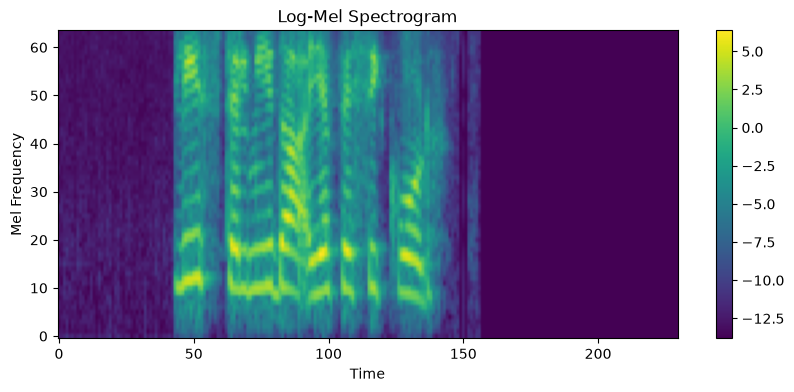

In [92]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.imshow(
    log_mel_features.squeeze(0).numpy(),
    aspect="auto",
    origin="lower"
)
plt.xlabel("Time")
plt.ylabel("Mel Frequency")
plt.title("Log-Mel Spectrogram")
plt.colorbar()
plt.show()

In [93]:
skit_durations = []
for sample in tqdm(
    skit_dataset["train"].select(range(100))
):
    skit_durations.append(
        sample["audio"].get_all_samples().duration_seconds
    )

100%|███████████████████████████████████████| 100/100 [00:00<00:00, 620.02it/s]


In [94]:
pd.Series(skit_durations).describe()

count    100.00000
mean       4.29960
std        1.07865
min        1.50000
25%        3.54800
50%        4.04800
75%        5.09600
max        7.64400
dtype: float64

This is helping in choosing fixed CNN input size from the actual dataset.

In [95]:
#creating the fixed-size Log-Mel extractor

skit_mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=8000,
    n_fft=400,
    hop_length=160,
    n_mels=64
)
skit_db_transform = torchaudio.transforms.AmplitudeToDB(
    stype="power",
    top_db=80
)

In [96]:
def extract_log_mel_features(audio, target_frames=256):
    audio_samples = audio.get_all_samples()

    waveform = audio_samples.data

    mel_features = skit_mel_transform(waveform)

    log_mel_features = skit_db_transform(
        mel_features
    ).squeeze(0)

    current_frames = log_mel_features.shape[1]

    if current_frames < target_frames:
        padding = target_frames - current_frames

        log_mel_features = torch.nn.functional.pad(
            log_mel_features,
            (0, padding),
            value=-80.0
        )

    else:
        log_mel_features = log_mel_features[
            :, :target_frames
        ]

    return log_mel_features.numpy()

In [97]:
test_log_mel = extract_log_mel_features(
    skit_dataset["train"][0]["audio"]
)

test_log_mel.shape

(64, 256)

In [98]:
test_log_mel.min(), test_log_mel.max()

(np.float32(-80.0), np.float32(27.636677))

In [99]:
#creating the CNN dataset loader

from torch.utils.data import Dataset, DataLoader

class SkitAudioDataset(Dataset):
    def __init__(self, hf_dataset):
        self.hf_dataset = hf_dataset

    def __len__(self):
        return len(self.hf_dataset)

    def __getitem__(self, idx):
        sample = self.hf_dataset[idx]

        log_mel = extract_log_mel_features(
            sample["audio"]
        )

        log_mel = torch.tensor(
            log_mel,
            dtype=torch.float32
        ).unsqueeze(0)

        label = torch.tensor(
            sample["intent_class"],
            dtype=torch.long
        )

        return log_mel, label

In [100]:
#creating the three datasets

skit_cnn_train = SkitAudioDataset(
    skit_train_split
)

skit_cnn_val = SkitAudioDataset(
    skit_val_split
)

skit_cnn_test = SkitAudioDataset(
    skit_dataset["test"]
)

In [101]:
cnn_sample, cnn_label = skit_cnn_train[0]
cnn_sample.shape, cnn_label

(torch.Size([1, 64, 256]), tensor(6))

In [102]:
#creating DataLoaders

from torch.utils.data import DataLoader

skit_train_loader = DataLoader(
    skit_cnn_train,
    batch_size=32,
    shuffle=True
)

skit_val_loader = DataLoader(
    skit_cnn_val,
    batch_size=32,
    shuffle=False
)

skit_test_loader = DataLoader(
    skit_cnn_test,
    batch_size=32,
    shuffle=False
)

In [103]:
cnn_batch_features, cnn_batch_labels = next(
    iter(skit_train_loader)
)
cnn_batch_features.shape, cnn_batch_labels.shape

(torch.Size([32, 1, 64, 256]), torch.Size([32]))

In [104]:
#CNN

import torch
import torch.nn as nn

In [105]:
class SkitCNN(nn.Module):
    def __init__(self, num_classes=14):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((4, 8))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [106]:
skit_device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)
skit_device

device(type='mps')

In [107]:
#Model

skit_cnn_model = SkitCNN(
    num_classes=14
).to(skit_device)

In [108]:
skit_cnn_model

SkitCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(4, 8))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(i

In [109]:
#testing

cnn_batch_features = cnn_batch_features.to(
    skit_device
)

cnn_batch_output = skit_cnn_model(
    cnn_batch_features
)

cnn_batch_output.shape

torch.Size([32, 14])

In [110]:
#Loss function and optimizer

import torch.optim as optim

skit_criterion = nn.CrossEntropyLoss()

skit_optimizer = optim.Adam(
    skit_cnn_model.parameters(),
    lr=0.001
)

In [111]:
#Training + validation loop

skit_epochs = 5

skit_train_history = []
skit_val_history = []

for epoch in range(skit_epochs):

    skit_cnn_model.train()

    skit_train_loss = 0.0
    skit_train_correct = 0
    skit_train_total = 0

    for cnn_features, cnn_labels in tqdm(
        skit_train_loader,
        desc=f"Epoch {epoch + 1}/{skit_epochs}"
    ):
        cnn_features = cnn_features.to(skit_device)
        cnn_labels = cnn_labels.to(skit_device)

        skit_optimizer.zero_grad()

        cnn_outputs = skit_cnn_model(
            cnn_features
        )

        cnn_loss = skit_criterion(
            cnn_outputs,
            cnn_labels
        )

        cnn_loss.backward()
        skit_optimizer.step()

        skit_train_loss += (
            cnn_loss.item() * cnn_labels.size(0)
        )

        cnn_predictions = cnn_outputs.argmax(dim=1)

        skit_train_correct += (
            cnn_predictions == cnn_labels
        ).sum().item()

        skit_train_total += cnn_labels.size(0)

    skit_train_loss = (
        skit_train_loss / skit_train_total
    )

    skit_train_accuracy = (
        skit_train_correct / skit_train_total
    )

    skit_cnn_model.eval()

    skit_val_loss = 0.0
    skit_val_correct = 0
    skit_val_total = 0

    with torch.no_grad():

        for cnn_features, cnn_labels in skit_val_loader:

            cnn_features = cnn_features.to(
                skit_device
            )

            cnn_labels = cnn_labels.to(
                skit_device
            )

            cnn_outputs = skit_cnn_model(
                cnn_features
            )

            cnn_loss = skit_criterion(
                cnn_outputs,
                cnn_labels
            )

            skit_val_loss += (
                cnn_loss.item() * cnn_labels.size(0)
            )

            cnn_predictions = cnn_outputs.argmax(dim=1)

            skit_val_correct += (
                cnn_predictions == cnn_labels
            ).sum().item()

            skit_val_total += cnn_labels.size(0)

    skit_val_loss = (
        skit_val_loss / skit_val_total
    )

    skit_val_accuracy = (
        skit_val_correct / skit_val_total
    )

    skit_train_history.append(
        skit_train_accuracy
    )

    skit_val_history.append(
        skit_val_accuracy
    )

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss = {skit_train_loss:.4f}, "
        f"Train Accuracy = {skit_train_accuracy:.4f}, "
        f"Val Loss = {skit_val_loss:.4f}, "
        f"Val Accuracy = {skit_val_accuracy:.4f}"
    )

Epoch 1/5: 100%|█████████████████████████████| 232/232 [00:23<00:00,  9.85it/s]


Epoch 1: Train Loss = 2.5700, Train Accuracy = 0.1249, Val Loss = 2.5773, Val Accuracy = 0.1082


Epoch 2/5: 100%|█████████████████████████████| 232/232 [00:23<00:00,  9.84it/s]


Epoch 2: Train Loss = 2.4647, Train Accuracy = 0.1604, Val Loss = 2.5562, Val Accuracy = 0.1168


Epoch 3/5: 100%|█████████████████████████████| 232/232 [00:22<00:00, 10.49it/s]


Epoch 3: Train Loss = 2.3430, Train Accuracy = 0.2017, Val Loss = 2.4742, Val Accuracy = 0.1768


Epoch 4/5: 100%|█████████████████████████████| 232/232 [00:22<00:00, 10.49it/s]


Epoch 4: Train Loss = 2.2506, Train Accuracy = 0.2413, Val Loss = 2.4416, Val Accuracy = 0.1755


Epoch 5/5: 100%|█████████████████████████████| 232/232 [00:24<00:00,  9.56it/s]


Epoch 5: Train Loss = 2.1498, Train Accuracy = 0.2680, Val Loss = 2.5877, Val Accuracy = 0.1478


So far CNN is the best model

In [112]:
#Checking whether CNN is succeeding and failing using its validation classification report and confusion matrix

skit_cnn_val_predictions = []

skit_cnn_model.eval()

with torch.no_grad():
    for cnn_features, cnn_labels in skit_val_loader:

        cnn_features = cnn_features.to(skit_device)

        cnn_outputs = skit_cnn_model(
            cnn_features
        )

        cnn_predictions = cnn_outputs.argmax(
            dim=1
        )

        skit_cnn_val_predictions.extend(
            cnn_predictions.cpu().numpy()
        )

In [113]:
skit_cnn_val_predictions = np.array(
    skit_cnn_val_predictions
)

In [114]:
print(
    classification_report(
        skit_val_labels,
        skit_cnn_val_predictions
    )
)

              precision    recall  f1-score   support

           0       0.09      0.21      0.13       168
           1       0.14      0.39      0.20       228
           2       0.13      0.04      0.06       220
           3       0.19      0.11      0.14       202
           4       0.41      0.05      0.09       213
           5       0.10      0.09      0.10       192
           6       0.64      0.09      0.16       173
           7       0.06      0.01      0.02       273
           8       0.44      0.21      0.28       281
           9       0.14      0.21      0.17       193
          10       0.16      0.14      0.15       272
          11       0.28      0.36      0.31       194
          12       0.08      0.05      0.06       200
          13       0.06      0.13      0.08       223

    accuracy                           0.15      3032
   macro avg       0.21      0.15      0.14      3032
weighted avg       0.21      0.15      0.14      3032



In [115]:
#confusion matrix

from sklearn.metrics import confusion_matrix

skit_cnn_confusion = confusion_matrix(
    skit_val_labels,
    skit_cnn_val_predictions
)

skit_cnn_confusion

array([[ 36,  27,   7,   4,   0,   5,   0,   1,   1,   6,  30,   1,  12,
         38],
       [ 40,  88,   7,   6,   0,   7,   0,   6,  11,  13,   9,   6,   0,
         35],
       [ 27,  46,   9,  11,   3,  20,   4,  11,   8,   7,  11,  29,   2,
         32],
       [ 40,  59,   0,  22,   0,  10,   1,   3,   0,  17,   5,  17,   1,
         27],
       [ 24,  30,   3,   5,  11,  15,   0,   5,   5,  13,   4,  45,   1,
         52],
       [ 32,  51,   6,   8,   1,  17,   1,   2,   4,   5,  18,  18,   2,
         27],
       [ 22,  24,  15,  22,   0,   9,  16,   5,   3,   2,  18,   1,  15,
         21],
       [ 33, 106,   3,  17,   0,  16,   0,   4,   2,   8,  16,  17,   6,
         45],
       [  8,  26,   2,   4,   4,  17,   0,   6,  58,  53,  23,  22,  21,
         37],
       [ 22,  16,   3,   2,   4,  11,   2,   4,  12,  41,  24,  10,  10,
         32],
       [ 33,  35,   4,   2,   3,   4,   0,   4,   5,  60,  37,   4,  32,
         49],
       [ 11,  61,   0,   7,   0,  18,   1, 

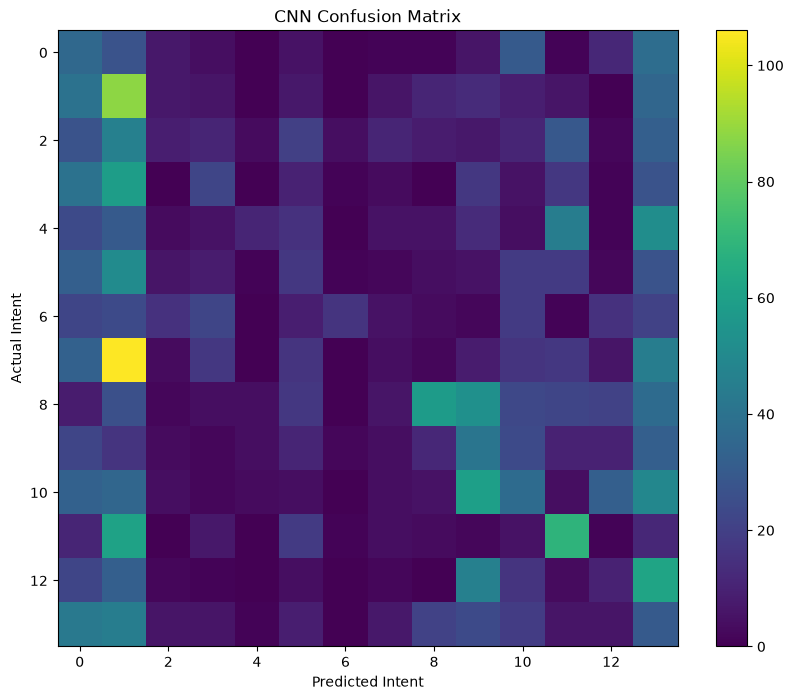

In [116]:
plt.figure(figsize=(10, 8))

plt.imshow(
    skit_cnn_confusion,
    aspect="auto"
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("CNN Confusion Matrix")

plt.colorbar()
plt.show()

In [117]:
skit_best_val_accuracy = max(
    skit_val_history
)
skit_best_val_accuracy

0.17678100263852242

In [118]:
#Baseline Model Comparison — Speaker-Disjoint Validation
skit_cnn_best_val_accuracy = 0.16556728232189974

In [119]:
import transformers
transformers.__version__

'5.16.1'

In [120]:
#Loading Wav2Vec2

from transformers import AutoProcessor, Wav2Vec2Model

skit_wav2vec_processor = AutoProcessor.from_pretrained(
    "facebook/wav2vec2-base"
)

skit_wav2vec_model = Wav2Vec2Model.from_pretrained(
    "facebook/wav2vec2-base"
)

Loading weights: 100%|████████████████████| 211/211 [00:00<00:00, 75952.47it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [121]:
skit_wav2vec_model = skit_wav2vec_model.to(
    skit_device
)

for parameter in skit_wav2vec_model.parameters():
    parameter.requires_grad = False

skit_wav2vec_model.eval()

Wav2Vec2Model(
  (feature_extractor): Wav2Vec2FeatureEncoder(
    (conv_layers): ModuleList(
      (0): Wav2Vec2GroupNormConvLayer(
        (conv): Conv1d(1, 512, kernel_size=(10,), stride=(5,), bias=False)
        (activation): GELUActivation()
        (layer_norm): GroupNorm(512, 512, eps=1e-05, affine=True)
      )
      (1-4): 4 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
      (5-6): 2 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(2,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
    )
  )
  (feature_projection): Wav2Vec2FeatureProjection(
    (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
    (projection): Linear(in_features=512, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): Wav2Vec2Encoder(
    (pos_conv_embed): Wav2Vec2PositionalConvEmbedding(
  

In [122]:
skit_wav2vec_resampler = torchaudio.transforms.Resample(
    orig_freq=8000,
    new_freq=16000
)

In [123]:
sample_audio_wav2vec = skit_dataset["train"][0]["audio"]

sample_audio_data = (
    sample_audio_wav2vec
    .get_all_samples()
    .data
)

sample_audio_16k = skit_wav2vec_resampler(
    sample_audio_data
)

sample_audio_16k.shape

torch.Size([1, 73536])

In [124]:
sample_audio_array = (
    sample_audio_16k
    .squeeze(0)
    .numpy()
)

In [125]:
skit_wav2vec_input = skit_wav2vec_processor(
    sample_audio_array,
    sampling_rate=16000,
    return_tensors="pt"
)

In [126]:
skit_wav2vec_input.input_values.shape

torch.Size([1, 73536])

In [127]:
skit_wav2vec_input_values = (
    skit_wav2vec_input.input_values.to(
        skit_device
    )
)

In [128]:
with torch.no_grad():
    skit_wav2vec_output = skit_wav2vec_model(
        skit_wav2vec_input_values
    )

In [129]:
skit_wav2vec_output.last_hidden_state.shape

torch.Size([1, 229, 768])

In [130]:
skit_wav2vec_embedding = (
    skit_wav2vec_output.last_hidden_state.mean(dim=1)
)
print(skit_wav2vec_embedding.shape)

torch.Size([1, 768])


In [131]:
sample_embedding = skit_wav2vec_embedding.cpu().numpy()
print(sample_embedding.shape)
print(sample_embedding[0][:10])

(1, 768)
[ 0.08359398  0.11267091  0.2709982   0.08480723  0.05364241 -0.17017877
  0.20754142 -0.2000734  -0.22570361 -0.22138421]


In [132]:
#Creating a reusable Wav2Vec2 embedding function

def extract_wav2vec_embedding(audio):
    audio_samples = audio.get_all_samples()
    waveform = audio_samples.data

    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)
    waveform_16k = skit_wav2vec_resampler(waveform)

    # Converting to NumPy
    audio_array = waveform_16k.squeeze(0).numpy()

    inputs = skit_wav2vec_processor(
        audio_array,
        sampling_rate=16000,
        return_tensors="pt"
    )

    input_values = inputs.input_values.to(skit_device)
    with torch.no_grad():
        output = skit_wav2vec_model(input_values)

    # Mean pooling across time
    embedding = output.last_hidden_state.mean(dim=1)
    return embedding.squeeze(0).cpu().numpy()

In [133]:
print(type(skit_cnn_train))

<class '__main__.SkitAudioDataset'>


In [134]:
print(type(skit_train_split))

<class 'datasets.arrow_dataset.Dataset'>


In [135]:
test_embedding = extract_wav2vec_embedding(
    skit_train_split[0]["audio"]
)
print(test_embedding.shape)
print("Intent:", skit_train_split[0]["intent_class"])

(768,)
Intent: 6


In [136]:
#dataset embedding function

from tqdm import tqdm
import numpy as np

def extract_dataset_embeddings(hf_dataset):
    embeddings = []
    labels = []

    for i in tqdm(range(len(hf_dataset))):
        embedding = extract_wav2vec_embedding(
            hf_dataset[i]["audio"]
        )

        embeddings.append(embedding)
        labels.append(hf_dataset[i]["intent_class"])

    return np.array(embeddings), np.array(labels)

In [137]:
#Extracting training embeddings

X_w2v_train, y_w2v_train = extract_dataset_embeddings(
    skit_train_split
)

print("X shape:", X_w2v_train.shape)
print("y shape:", y_w2v_train.shape)

100%|██████████████████████████████████████| 7413/7413 [08:41<00:00, 14.22it/s]

X shape: (7413, 768)
y shape: (7413,)


In [138]:
X_w2v_val, y_w2v_val = extract_dataset_embeddings(
    skit_val_split
)

print("X shape:", X_w2v_val.shape)
print("y shape:", y_w2v_val.shape)

100%|██████████████████████████████████████| 3032/3032 [03:37<00:00, 13.93it/s]

X shape: (3032, 768)
y shape: (3032,)


In [139]:
#scailing

from sklearn.preprocessing import StandardScaler

w2v_scaler = StandardScaler()

X_w2v_train_scaled = w2v_scaler.fit_transform(X_w2v_train)
X_w2v_val_scaled = w2v_scaler.transform(X_w2v_val)

print("Train:", X_w2v_train_scaled.shape)
print("Validation:", X_w2v_val_scaled.shape)

Train: (7413, 768)
Validation: (3032, 768)


In [140]:
#Training Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

w2v_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

w2v_lr.fit(X_w2v_train_scaled, y_w2v_train)

y_w2v_val_pred = w2v_lr.predict(X_w2v_val_scaled)

w2v_val_accuracy = accuracy_score(
    y_w2v_val,
    y_w2v_val_pred
)

print(f"Wav2Vec2 + Logistic Regression Validation Accuracy: "
      f"{w2v_val_accuracy * 100:.2f}%")

Wav2Vec2 + Logistic Regression Validation Accuracy: 44.39%


In [141]:
#classification report

from sklearn.metrics import classification_report

print(classification_report(
    y_w2v_val,
    y_w2v_val_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.3415    0.4167    0.3753       168
           1     0.2468    0.2544    0.2505       228
           2     0.6149    0.4136    0.4946       220
           3     0.3493    0.4703    0.4008       202
           4     0.5980    0.2864    0.3873       213
           5     0.4478    0.1562    0.2317       192
           6     0.4281    0.7052    0.5328       173
           7     0.3814    0.4652    0.4191       273
           8     0.5961    0.6512    0.6224       281
           9     0.5758    0.3938    0.4677       193
          10     0.5439    0.4559    0.4960       272
          11     0.4173    0.5979    0.4915       194
          12     0.5197    0.7250    0.6054       200
          13     0.2981    0.2152    0.2500       223

    accuracy                         0.4439      3032
   macro avg     0.4542    0.4434    0.4304      3032
weighted avg     0.4581    0.4439    0.4340      3032



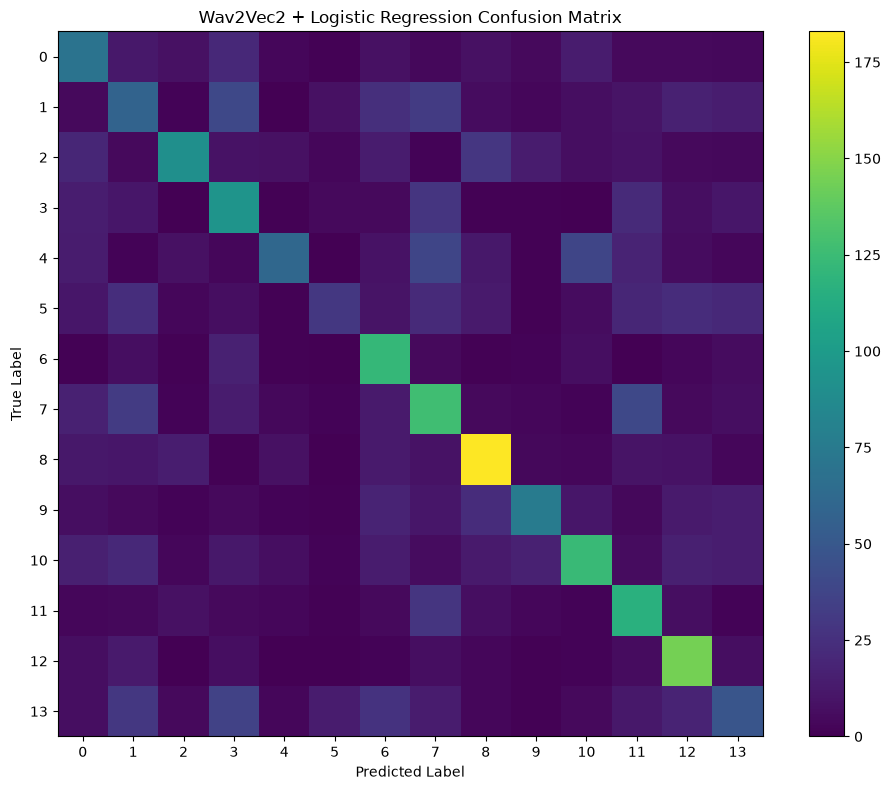

In [142]:
#confusion matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_w2v_val, y_w2v_val_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest")
plt.title("Wav2Vec2 + Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()
plt.xticks(range(14))
plt.yticks(range(14))
plt.tight_layout()
plt.show()

In [143]:
#saving the embbedings

np.save("X_w2v_train.npy", X_w2v_train)
np.save("y_w2v_train.npy", y_w2v_train)

np.save("X_w2v_val.npy", X_w2v_val)
np.save("y_w2v_val.npy", y_w2v_val)

print("Wav2Vec2 embeddings saved successfully.")

Wav2Vec2 embeddings saved successfully.


In [144]:
import pickle

with open("w2v_lr_model.pkl", "wb") as f:
    pickle.dump(w2v_lr, f)

with open("w2v_scaler.pkl", "wb") as f:
    pickle.dump(w2v_scaler, f)
print("Wav2Vec2 classifier and scaler saved successfully.")

Wav2Vec2 classifier and scaler saved successfully.


In [145]:
id="w2test1"
candidates = [
    (name, obj)
    for name, obj in list(globals().items())
    if type(obj).__name__ == "Dataset" and len(obj) == 1400
]
print([(name, len(obj)) for name, obj in candidates])

[]


In [146]:
from datasets import DatasetDict

dataset_dicts = [
    (name, obj)
    for name, obj in globals().items()
    if isinstance(obj, DatasetDict)
]
print([
    (name, list(obj.keys()),
     {k: len(obj[k]) for k in obj.keys()})
    for name, obj in dataset_dicts
])

[('skit_dataset', ['train', 'test'], {'train': 10445, 'test': 1400}), ('_3', ['train', 'test'], {'train': 10445, 'test': 1400}), ('_6', ['train', 'test'], {'train': 10445, 'test': 1400}), ('_26', ['train', 'test'], {'train': 10445, 'test': 1400})]


In [147]:
skit_test = skit_dataset["test"]

print(type(skit_test))
print(len(skit_test))

<class 'datasets.arrow_dataset.Dataset'>
1400


In [148]:
X_w2v_test, y_w2v_test = extract_dataset_embeddings(
    skit_test
)
print("X shape:", X_w2v_test.shape)
print("y shape:", y_w2v_test.shape)

100%|██████████████████████████████████████| 1400/1400 [01:42<00:00, 13.63it/s]


X shape: (1400, 768)
y shape: (1400,)


In [149]:
#scailing

X_w2v_test_scaled = w2v_scaler.transform(X_w2v_test)

print(X_w2v_test_scaled.shape)

(1400, 768)


In [150]:
#Evaluating on the official test set

y_w2v_test_pred = w2v_lr.predict(X_w2v_test_scaled)

w2v_test_accuracy = accuracy_score(
    y_w2v_test,
    y_w2v_test_pred
)

print(f"Wav2Vec2 + Logistic Regression Test Accuracy: "
      f"{w2v_test_accuracy * 100:.2f}%")

Wav2Vec2 + Logistic Regression Test Accuracy: 69.07%


In [151]:
#official-test classification report

from sklearn.metrics import classification_report

print(classification_report(
    y_w2v_test,
    y_w2v_test_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.7212    0.7500    0.7353       100
           1     0.5607    0.6000    0.5797       100
           2     0.7753    0.6900    0.7302       100
           3     0.6132    0.6500    0.6311       100
           4     0.8533    0.6400    0.7314       100
           5     0.7600    0.5700    0.6514       100
           6     0.6911    0.8500    0.7623       100
           7     0.5766    0.6400    0.6066       100
           8     0.7248    0.7900    0.7560       100
           9     0.8205    0.6400    0.7191       100
          10     0.7255    0.7400    0.7327       100
          11     0.6404    0.7300    0.6822       100
          12     0.7156    0.7800    0.7464       100
          13     0.6122    0.6000    0.6061       100

    accuracy                         0.6907      1400
   macro avg     0.6993    0.6907    0.6908      1400
weighted avg     0.6993    0.6907    0.6908      1400



In [152]:
np.save("X_w2v_test.npy", X_w2v_test)
np.save("y_w2v_test.npy", y_w2v_test)
print("Official test embeddings saved successfully.")

Official test embeddings saved successfully.


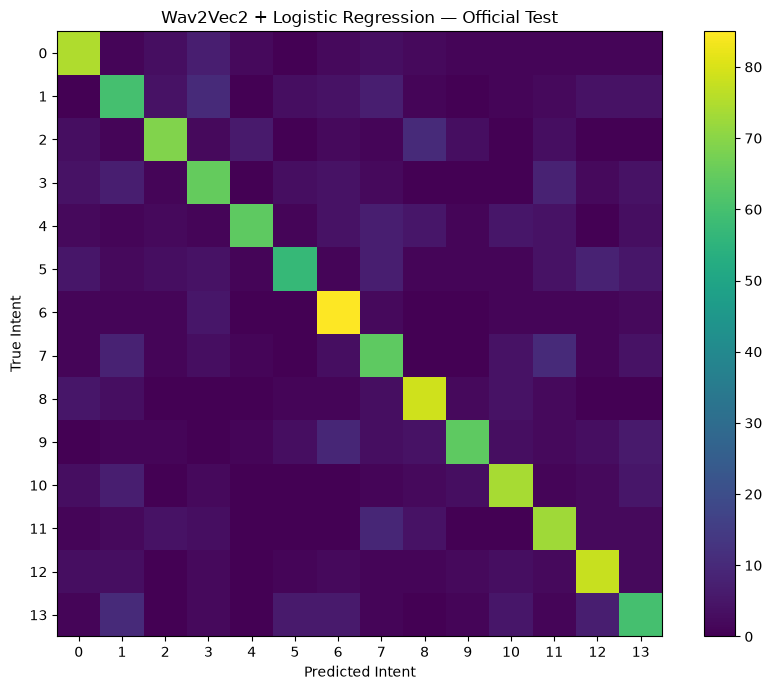

In [153]:
#official-test confusion matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm_test = confusion_matrix(y_w2v_test, y_w2v_test_pred)

plt.figure(figsize=(9, 7))
plt.imshow(cm_test, interpolation="nearest")
plt.title("Wav2Vec2 + Logistic Regression — Official Test")
plt.xlabel("Predicted Intent")
plt.ylabel("True Intent")
plt.colorbar()
plt.xticks(range(14))
plt.yticks(range(14))
plt.tight_layout()
plt.show()

In [154]:
#Creating the intent mapping + voice prediction function

intent_map = {
    0: "branch_address",
    1: "activate_card",
    2: "past_transactions",
    3: "dispatch_status",
    4: "outstanding_balance",
    5: "card_issue",
    6: "ifsc_code",
    7: "generate_pin",
    8: "unauthorised_transaction",
    9: "loan_query",
    10: "balance_enquiry",
    11: "change_limit",
    12: "block",
    13: "lost"
}
def predict_voice_intent(audio):
    embedding = extract_wav2vec_embedding(audio)

    embedding_scaled = w2v_scaler.transform(
        embedding.reshape(1, -1)
    )

    prediction = w2v_lr.predict(embedding_scaled)[0]
    probabilities = w2v_lr.predict_proba(embedding_scaled)[0]

    confidence = float(np.max(probabilities))

    return {
        "intent_class": int(prediction),
        "intent": intent_map[int(prediction)],
        "confidence": confidence
    }

In [155]:
#testing the complete voice → intent pipeline

sample_result = predict_voice_intent(
    skit_train_split[0]["audio"]
)
print(sample_result)

{'intent_class': 6, 'intent': 'ifsc_code', 'confidence': 0.9975475668907166}


Audio → Wav2Vec2 → 768-D embedding → Logistic Regression → intent + confidence

In [156]:
#Testing on an unseen official-test sample

test_voice_result = predict_voice_intent(
    skit_test[0]["audio"]
)
print(test_voice_result)
print("Actual intent class:", skit_test[0]["intent_class"])
print("Actual intent:", intent_map[skit_test[0]["intent_class"]])

{'intent_class': 9, 'intent': 'loan_query', 'confidence': 0.46234655380249023}
Actual intent class: 9
Actual intent: loan_query


In [157]:
#Creating the first CPDE voice-risk signal

voice_confidence = test_voice_result["confidence"]

voice_risk = 1 - voice_confidence
print("Intent confidence:", round(voice_confidence, 4))
print("Voice/intent risk:", round(voice_risk, 4))

Intent confidence: 0.4623
Voice/intent risk: 0.5377


This ia a prototype CPDE signal

In [158]:
#Creating the combined CPDE prototype

def cpde_decision(fraud_probability, intent_confidence):
    voice_risk = 1 - intent_confidence

    # Prototype fusion
    cpde_score = (
        0.70 * fraud_probability +
        0.30 * voice_risk
    )

    if cpde_score >= 0.60:
        decision = "BLOCK"
        risk_level = "HIGH"
    elif cpde_score >= 0.30:
        decision = "WARN"
        risk_level = "MEDIUM"
    else:
        decision = "PROCEED"
        risk_level = "LOW"

    return {
        "fraud_probability": float(fraud_probability),
        "intent_confidence": float(intent_confidence),
        "voice_risk": float(voice_risk),
        "cpde_score": float(cpde_score),
        "risk_level": risk_level,
        "decision": decision
    }

In [159]:
cpde_result = cpde_decision(
    fraud_probability=0.22,
    intent_confidence=test_voice_result["confidence"]
)
print(cpde_result)

{'fraud_probability': 0.22, 'intent_confidence': 0.46234655380249023, 'voice_risk': 0.5376534461975098, 'cpde_score': 0.3152960338592529, 'risk_level': 'MEDIUM', 'decision': 'WARN'}


In [160]:
#explainable CPDE output 

def explain_cpde_result(cpde_result):
    reasons = []

    if cpde_result["fraud_probability"] >= 0.45:
        reasons.append("Transaction fraud probability is above the configured threshold.")

    if cpde_result["intent_confidence"] < 0.50:
        reasons.append("Voice intent confidence is low, indicating uncertainty in the spoken command.")

    if not reasons:
        reasons.append("No major risk signal exceeded the current warning criteria.")

    return {
        **cpde_result,
        "reasons": reasons
    }

In [161]:
#Generating the final explainable decision

explainable_result = explain_cpde_result(cpde_result)
print(explainable_result)

{'fraud_probability': 0.22, 'intent_confidence': 0.46234655380249023, 'voice_risk': 0.5376534461975098, 'cpde_score': 0.3152960338592529, 'risk_level': 'MEDIUM', 'decision': 'WARN', 'reasons': ['Voice intent confidence is low, indicating uncertainty in the spoken command.']}


In [162]:
#Creating one end-to-end VeriPay decision function

def veripay_decision(audio, fraud_probability):
    # Voice understanding
    voice_result = predict_voice_intent(audio)

    # CPDE fusion
    cpde_result = cpde_decision(
        fraud_probability=fraud_probability,
        intent_confidence=voice_result["confidence"]
    )
    final_result = explain_cpde_result(cpde_result)

    final_result["intent"] = voice_result["intent"]
    final_result["intent_class"] = voice_result["intent_class"]

    return final_result

In [163]:
final_veripay_result = veripay_decision(
    skit_test[0]["audio"],
    fraud_probability=0.22
)
print(final_veripay_result)

{'fraud_probability': 0.22, 'intent_confidence': 0.46234655380249023, 'voice_risk': 0.5376534461975098, 'cpde_score': 0.3152960338592529, 'risk_level': 'MEDIUM', 'decision': 'WARN', 'reasons': ['Voice intent confidence is low, indicating uncertainty in the spoken command.'], 'intent': 'loan_query', 'intent_class': 9}


In [164]:
#Creating a real transaction-risk function

def predict_transaction_risk(transaction_features):
    probability = rf_model.predict_proba(
        [transaction_features]
    )[0][1]

    return float(probability)

In [165]:
ieee_demo_transaction = np.load(
    "ieee_demo_transaction.npy"
)

print(ieee_demo_transaction.shape)

(23,)


In [166]:
import os

matches = []

for root, dirs, files in os.walk("."):
    if "ieee_cis_rf_model.pkl" in files:
        matches.append(os.path.join(root, "ieee_cis_rf_model.pkl"))

print(matches)

['./backend/models/ieee_cis_rf_model.pkl']


In [167]:
import pickle

model_path = matches[0]

with open(model_path, "rb") as f:
    rf_model = pickle.load(f)

print("Random Forest model loaded.")
print(rf_model.feature_names_in_)

Random Forest model loaded.
['TransactionAmt' 'TransactionDT' 'card1' 'card2' 'card3' 'card5' 'addr1'
 'addr2' 'dist1' 'C1' 'C2' 'C3' 'C4' 'C5' 'C6' 'C7' 'C8' 'C9' 'C10' 'C11'
 'C12' 'C13' 'C14']


/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [168]:
real_fraud_probability = predict_transaction_risk(
    ieee_demo_transaction
)
print("Real IEEE-CIS fraud probability:",
      real_fraud_probability)

Real IEEE-CIS fraud probability: 0.01


/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [169]:
#real end-to-end VeriPay pipeline

real_veripay_result = veripay_decision(
    skit_test[0]["audio"],
    fraud_probability=real_fraud_probability
)
print("Final VeriPay Result:")
print(real_veripay_result)

Final VeriPay Result:
{'fraud_probability': 0.01, 'intent_confidence': 0.46234655380249023, 'voice_risk': 0.5376534461975098, 'cpde_score': 0.16829603385925293, 'risk_level': 'LOW', 'decision': 'PROCEED', 'reasons': ['Voice intent confidence is low, indicating uncertainty in the spoken command.'], 'intent': 'loan_query', 'intent_class': 9}


In [170]:
#Taking a high-risk scenario

highrisk_result = veripay_decision(
    skit_test[0]["audio"],
    fraud_probability=0.80
)
print(highrisk_result)

{'fraud_probability': 0.8, 'intent_confidence': 0.46234655380249023, 'voice_risk': 0.5376534461975098, 'cpde_score': 0.7212960338592529, 'risk_level': 'HIGH', 'decision': 'BLOCK', 'reasons': ['Transaction fraud probability is above the configured threshold.', 'Voice intent confidence is low, indicating uncertainty in the spoken command.'], 'intent': 'loan_query', 'intent_class': 9}


In [171]:
#Taking a medium-risk scenario

mediumrisk_result = veripay_decision(
    skit_test[0]["audio"],
    fraud_probability=0.35
)
print(mediumrisk_result)

{'fraud_probability': 0.35, 'intent_confidence': 0.46234655380249023, 'voice_risk': 0.5376534461975098, 'cpde_score': 0.4062960338592529, 'risk_level': 'MEDIUM', 'decision': 'WARN', 'reasons': ['Voice intent confidence is low, indicating uncertainty in the spoken command.'], 'intent': 'loan_query', 'intent_class': 9}


In [172]:
#CPDE results table

import pandas as pd

cpde_demo_table = pd.DataFrame([
    {
        "Scenario": "Low Risk",
        "Fraud Probability": 0.01,
        "Voice Confidence": 0.4598,
        "CPDE Score": 0.1690,
        "Risk Level": "LOW",
        "Decision": "PROCEED"
    },
    {
        "Scenario": "Medium Risk",
        "Fraud Probability": 0.35,
        "Voice Confidence": 0.4598,
        "CPDE Score": 0.4070,
        "Risk Level": "MEDIUM",
        "Decision": "WARN"
    },
    {
        "Scenario": "High Risk",
        "Fraud Probability": 0.80,
        "Voice Confidence": 0.4598,
        "CPDE Score": 0.7220,
        "Risk Level": "HIGH",
        "Decision": "BLOCK"
    }
])

display(cpde_demo_table)

,Scenario,Fraud Probability,Voice Confidence,CPDE Score,Risk Level,Decision
0,Low Risk,0.01,0.4598,0.169,LOW,PROCEED
1,Medium Risk,0.35,0.4598,0.407,MEDIUM,WARN
2,High Risk,0.80,0.4598,0.722,HIGH,BLOCK


In [173]:
import json

demo_results = {
    "real_transaction": real_veripay_result,
    "high_risk_demo": highrisk_result,
    "medium_risk_demo": mediumrisk_result
}
with open("veripay_cpde_demo_results.json", "w") as f:
    json.dump(demo_results, f, indent=4)

print("CPDE demo results saved successfully.")

CPDE demo results saved successfully.


In [174]:
print(skit_dataset)

print("\nTraining columns:")
print(skit_dataset["train"].column_names)

print("\nIntent labels:")
print(skit_dataset["train"].features["intent_class"])

print("\nSample:")
print(skit_dataset["train"][0]["intent_class"])

DatasetDict({
    train: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 10445
    })
    test: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 1400
    })
})

Training columns:
['audio', 'intent_class', 'template', 'speaker_id']

Intent labels:
Value('int64')

Sample:
6


In [175]:
#Verifying the 14 intent labels

from collections import Counter

print("Number of unique intents:",
      len(set(skit_dataset["train"]["intent_class"])))

print("\nIntent label distribution:")
print(Counter(skit_dataset["train"]["intent_class"]))

print("\nIntent names from dataset metadata:")
print(skit_dataset["train"].features["intent_class"])

Number of unique intents: 14

Intent label distribution:
Counter({8: 956, 1: 799, 13: 790, 6: 780, 0: 773, 10: 746, 4: 740, 7: 739, 2: 732, 3: 697, 9: 687, 12: 684, 5: 668, 11: 654})

Intent names from dataset metadata:
Value('int64')


In [176]:
print("Dataset information:")
print(skit_dataset)

print("\nDataset features and metadata:")
print(skit_dataset["train"].info)

print("\nDataset description:")
print(skit_dataset["train"].info.description)

Dataset information:
DatasetDict({
    train: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 10445
    })
    test: Dataset({
        features: ['audio', 'intent_class', 'template', 'speaker_id'],
        num_rows: 1400
    })
})

Dataset features and metadata:
DatasetInfo(features={'audio': Audio(sampling_rate=None, decode=True, num_channels=None, stream_index=None), 'intent_class': Value('int64'), 'template': Value('string'), 'speaker_id': Value('int64')}, builder_name='parquet', dataset_name='skit-s2i', config_name='default', version=0.0.0, splits={'train': SplitInfo(name='train', num_bytes=704921788, num_examples=10445, shard_lengths=[7423, 3022], dataset_name='skit-s2i'), 'test': SplitInfo(name='test', num_bytes=93283953, num_examples=1400, dataset_name='skit-s2i')}, download_size=495247674, dataset_size=798205741, size_in_bytes=1293453415)

Dataset description:



In [177]:
for label in sorted(set(skit_dataset["train"]["intent_class"])):
    print(f"\n{'=' * 15} Label {label} {'=' * 15}")

    examples = [
        row["template"]
        for row in skit_dataset["train"]
        if row["intent_class"] == label
    ][:3]

    for example in examples:
        print("-", example)


=============== Label 0 ===============
- Where is the bank branch ? 
- Please tell me the nearest branch of the bank
- What is the nearest branch?

=============== Label 1 ===============
- activate debit card
- How to activate credit card 
- activate

=============== Label 2 ===============
- Last <numeric> transaction details 
- Please give me the details of my last transaction 
- What was the amount of my last transaction 

=============== Label 3 ===============
- Is my card dispatched?
- Is my card dispatched?
- I want to know my credit card dispatch status 

=============== Label 4 ===============
- Give me the outstanding balance on my credit card
- Give me the outstanding balance on my credit card
- what is the outstanding balance on my credit card?

=============== Label 5 ===============
- I am unable to use my credit card 
- There is a problem with my credit card
- Debit card issue 

=============== Label 6 ===============
- Please tell me the IFSC Code 
- How to know my I

In [178]:
#label mapping

id2label = {
    0: "branch_location",
    1: "card_activation",
    2: "last_transaction",
    3: "card_dispatch_status",
    4: "credit_card_balance",
    5: "card_usage_issue",
    6: "ifsc_code",
    7: "card_pin_generation",
    8: "unauthorised_transaction",
    9: "loan_query",
    10: "balance_enquiry",
    11: "card_limit_or_estatement",
    12: "block_banking_service",
    13: "lost_card"
}

label2id = {name: idx for idx, name in id2label.items()}

print("Number of intent labels:", len(id2label))

for idx, name in id2label.items():
    print(f"{idx}: {name}")

Number of intent labels: 14
0: branch_location
1: card_activation
2: last_transaction
3: card_dispatch_status
4: credit_card_balance
5: card_usage_issue
6: ifsc_code
7: card_pin_generation
8: unauthorised_transaction
9: loan_query
10: balance_enquiry
11: card_limit_or_estatement
12: block_banking_service
13: lost_card


In [179]:
print("Existing split-related variables:")
for name in [
    "train_idx", "val_idx",
    "train_indices", "val_indices",
    "train_dataset", "val_dataset",
    "train_speakers", "val_speakers"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}, length = "
              f"{len(obj) if hasattr(obj, '__len__') else 'N/A'}")

Existing split-related variables:
train_speakers: set, length = 11


In [180]:
print("Training speakers:", train_speakers)

if "val_speakers" in globals():
    print("Validation speakers:", val_speakers)
    print("Overlap:", train_speakers.intersection(val_speakers))
else:
    print("val_speakers has not been created yet.")

Training speakers: {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11}
val_speakers has not been created yet.


In [181]:
print("Available training dataset columns:", skit_dataset["train"].column_names)

print("\nUnique speaker IDs:")
print(sorted(set(skit_dataset["train"]["speaker_id"])))

print("\nNumber of unique speakers:",
      len(set(skit_dataset["train"]["speaker_id"])))

Available training dataset columns: ['audio', 'intent_class', 'template', 'speaker_id']

Unique speaker IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

Number of unique speakers: 11


In [182]:
#validation speaker set

import random

all_speakers = sorted(set(skit_dataset["train"]["speaker_id"]))

random.seed(42)
random.shuffle(all_speakers)

val_speakers = set(all_speakers[:3])
train_speakers = set(all_speakers[3:])

print("Training speakers:", sorted(train_speakers))
print("Validation speakers:", sorted(val_speakers))
print("Overlap:", train_speakers.intersection(val_speakers))

Training speakers: [1, 2, 5, 6, 7, 9, 10, 11]
Validation speakers: [3, 4, 8]
Overlap: set()


In [183]:
#Counting the samples in each split

train_speaker_ids = skit_dataset["train"]["speaker_id"]

train_indices = [
    i for i, speaker in enumerate(train_speaker_ids)
    if speaker in train_speakers
]

val_indices = [
    i for i, speaker in enumerate(train_speaker_ids)
    if speaker in val_speakers
]

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Total samples:", len(train_indices) + len(val_indices))

Training samples: 7926
Validation samples: 2519
Total samples: 10445


In [184]:
print("Training speakers:", sorted(train_speakers))
print("Validation speakers:", sorted(val_speakers))

print("\nOverlapping speakers:",
      set(train_speakers) & set(val_speakers))

print("\nTraining indices:", len(train_indices))
print("Validation indices:", len(val_indices))
print("Total selected:", len(train_indices) + len(val_indices))
print("Original training split:", len(skit_dataset["train"]))

print("\nDuplicate indices:",
      len(train_indices) != len(set(train_indices))
      or len(val_indices) != len(set(val_indices)))

Training speakers: [1, 2, 5, 6, 7, 9, 10, 11]
Validation speakers: [3, 4, 8]

Overlapping speakers: set()

Training indices: 7926
Validation indices: 2519
Total selected: 10445
Original training split: 10445

Duplicate indices: False


In [185]:
train_dataset = skit_dataset["train"].select(train_indices)
val_dataset = skit_dataset["train"].select(val_indices)

print("Training dataset:", train_dataset)
print("Validation dataset:", val_dataset)

Training dataset: Dataset({
    features: ['audio', 'intent_class', 'template', 'speaker_id'],
    num_rows: 7926
})
Validation dataset: Dataset({
    features: ['audio', 'intent_class', 'template', 'speaker_id'],
    num_rows: 2519
})


In [186]:
#Checking one audio sample

sample = train_dataset[0]

print("Audio object type:", type(sample["audio"]))
print("Audio object:", sample["audio"])
print("Intent label:", sample["intent_class"])
print("Speaker ID:", sample["speaker_id"])

Audio object type: <class 'datasets.features._torchcodec.AudioDecoder'>
Audio object: <datasets.features._torchcodec.AudioDecoder object at 0x70ed2945c0>
Intent label: 7
Speaker ID: 11


In [187]:
audio_sample = sample["audio"].get_all_samples()

print("Audio tensor shape:", audio_sample.data.shape)
print("Sampling rate:", audio_sample.sample_rate)
print("Intent label:", sample["intent_class"])

Audio tensor shape: torch.Size([1, 36768])
Sampling rate: 8000
Intent label: 7


In [188]:
#Resample this one audio sample

import torchaudio

audio_tensor = audio_sample.data
audio_tensor_16k = torchaudio.functional.resample(
    audio_tensor,
    orig_freq=audio_sample.sample_rate,
    new_freq=16000
)

print("Original shape:", audio_tensor.shape)
print("Resampled shape:", audio_tensor_16k.shape)
print("New sampling rate: 16000 Hz")

Original shape: torch.Size([1, 36768])
Resampled shape: torch.Size([1, 73536])
New sampling rate: 16000 Hz


In [189]:
#Checking the Wav2Vec2 processor

from transformers import AutoProcessor

processor = AutoProcessor.from_pretrained(
    "facebook/wav2vec2-base"
)

print("Processor loaded:", type(processor).__name__)
print("Expected sampling rate:", processor.feature_extractor.sampling_rate)

Processor loaded: Wav2Vec2Processor
Expected sampling rate: 16000


In [190]:
processed_sample = processor(
    audio_tensor_16k.squeeze(0).numpy(),
    sampling_rate=16000,
    return_tensors="pt",
    padding=True
)

print("Input values shape:", processed_sample.input_values.shape)
print("Intent label:", sample["intent_class"])

Input values shape: torch.Size([1, 73536])
Intent label: 7


In [191]:
#Loading the fine-tuning model

from transformers import AutoModelForAudioClassification

model = AutoModelForAudioClassification.from_pretrained(
    "facebook/wav2vec2-base",
    num_labels=14,
    label2id={str(k): v for k, v in label2id.items()},
    id2label={v: k for k, v in label2id.items()},
    ignore_mismatched_sizes=True
)

print("Model loaded:", type(model).__name__)
print("Number of output labels:", model.config.num_labels)

Loading weights: 100%|████████████████████| 211/211 [00:00<00:00, 66376.52it/s]
[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
quantizer.codevectors        | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
classifier.bias              | MISSING    | 
projector.weight             | MISSING    | 
projector.bias               | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream tas

Model loaded: Wav2Vec2ForSequenceClassification
Number of output labels: 14


In [192]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.2f}%")

Total parameters: 94,572,174
Trainable parameters: 94,572,174
Trainable percentage: 100.00%


In [193]:
model.freeze_feature_encoder()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

Total parameters: 94,572,174
Trainable parameters: 90,371,726
Frozen parameters: 4,200,448


In [194]:
import torch
import platform

print("Operating system:", platform.system())
print("Processor architecture:", platform.machine())
print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())

Operating system: Darwin
Processor architecture: arm64
PyTorch version: 2.10.0
MPS available: True
CUDA available: False


In [195]:
import torch

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = model.to(device)

print("Training device:", device)
print("Model device:", next(model.parameters()).device)

Training device: mps
Model device: mps:0


In [196]:
#Creating a small audio-preparation function

import numpy as np
import torch
import torchaudio

def prepare_audio_sample(example):
    audio = example["audio"].get_all_samples()
    waveform = audio.data.squeeze(0)

    if audio.sample_rate != 16000:
        waveform = torchaudio.functional.resample(
            waveform,
            orig_freq=audio.sample_rate,
            new_freq=16000
        )

    return {
        "input_values": waveform.numpy().astype(np.float32),
        "labels": int(example["intent_class"])
    }

print("Audio preparation function updated.")

Audio preparation function updated.


In [197]:
prepared_sample = prepare_audio_sample(train_dataset[0])

print("Input shape:", prepared_sample["input_values"].shape)
print("Intent label:", prepared_sample["labels"])
print("Input data type:", prepared_sample["input_values"].dtype)

Input shape: (73536,)
Intent label: 7
Input data type: float32


In [198]:
# Test the updated audio preparation and batching pipeline

small_batch = [
    train_prepared_dataset[i]
    for i in range(4)
]

batch = collate_fn(small_batch)

print("Input shape:", batch["input_values"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)
print("Labels:", batch["labels"].tolist())

batch = {key: value.to(device) for key, value in batch.items()}

model.eval()
with torch.no_grad():
    outputs = model(
        input_values=batch["input_values"],
        attention_mask=batch["attention_mask"],
        labels=batch["labels"]
    )

print("Logits shape:", outputs.logits.shape)
print("Loss:", round(outputs.loss.item(), 4))

NameError: name 'train_prepared_dataset' is not defined

In [199]:
#Testing 8 training samples

small_batch = [
    prepare_audio_sample(train_dataset[i])
    for i in range(8)
]

print("Samples prepared:", len(small_batch))
print("Waveform shapes:", [x["input_values"].shape for x in small_batch])
print("Labels:", [x["labels"] for x in small_batch])

Samples prepared: 8
Waveform shapes: [(73536,), (81536,), (106304,), (122304,), (73536,), (89536,), (56768,), (64768,)]
Labels: [7, 3, 11, 13, 3, 4, 7, 10]


In [200]:
#Creating a batch-collation function

def collate_fn(batch):
    audio_arrays = [item["input_values"] for item in batch]
    labels = torch.tensor(
        [item["labels"] for item in batch],
        dtype=torch.long
    )

    inputs = processor(
        audio_arrays,
        sampling_rate=16000,
        padding=True,
        return_attention_mask=True,
        return_tensors="pt"
    )

    return {
        "input_values": inputs["input_values"],
        "attention_mask": inputs["attention_mask"],
        "labels": labels
    }

print("Updated collate function successfully.")

Updated collate function successfully.


In [201]:
test_batch = collate_fn(small_batch)

print("Input values shape:", test_batch["input_values"].shape)
print("Attention mask shape:", test_batch["attention_mask"].shape)
print("Labels shape:", test_batch["labels"].shape)
print("Labels:", test_batch["labels"].tolist())

Input values shape: torch.Size([8, 122304])
Attention mask shape: torch.Size([8, 122304])
Labels shape: torch.Size([8])
Labels: [7, 3, 11, 13, 3, 4, 7, 10]


In [202]:
model.eval()

with torch.no_grad():
    outputs = model(
        input_values=test_batch["input_values"].to(device),
        attention_mask=test_batch["attention_mask"].to(device)
    )

print("Logits shape:", outputs.logits.shape)
print("Expected shape: (8, 14)")

Logits shape: torch.Size([8, 14])
Expected shape: (8, 14)


In [203]:
#first 32 training samples

from tqdm.auto import tqdm

prepared_batch = [
    prepare_audio_sample(train_dataset[i])
    for i in tqdm(range(32))
]

print("Prepared samples:", len(prepared_batch))
print("First sample shape:", prepared_batch[0]["input_values"].shape)

100%|█████████████████████████████████████████| 32/32 [00:00<00:00, 148.97it/s]

Prepared samples: 32
First sample shape: (73536,)


In [204]:
val_batch_samples = [
    prepare_audio_sample(val_dataset[i])
    for i in range(8)
]

print("Validation samples prepared:", len(val_batch_samples))
print("First waveform shape:", val_batch_samples[0]["input_values"].shape)
print("Validation labels:", [x["labels"] for x in val_batch_samples])

Validation samples prepared: 8
First waveform shape: (73536,)
Validation labels: [6, 8, 0, 3, 2, 9, 6, 2]


In [205]:
%pip install -U "accelerate>=1.1.0"

Note: you may need to restart the kernel to use updated packages.


In [206]:
import accelerate
print("Accelerate version:", accelerate.__version__)

from transformers import TrainingArguments
print("TrainingArguments imported successfully")

Accelerate version: 1.15.0
TrainingArguments imported successfully


In [207]:
from transformers.utils import import_utils

import_utils.is_accelerate_available.cache_clear()

print("Accelerate detected:", import_utils.is_accelerate_available())

Accelerate detected: True


In [208]:
import transformers.training_args as ta
from transformers.trainer import DistributedType

ta.DistributedType = DistributedType

print("DistributedType patched:", ta.DistributedType)

DistributedType patched: <enum 'DistributedType'>


In [209]:
#training configuration

training_args = TrainingArguments(
    output_dir="./veripay_wav2vec2_finetuned",
    learning_rate=1e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    num_train_epochs=3,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=25,
    report_to="none",
    use_cpu=False,
    dataloader_num_workers=0,
    gradient_checkpointing=True,
    fp16=False,
    bf16=False,
    seed=42
)

print("Training configuration created successfully.")
print("Device:", training_args.device)

Training configuration created successfully.
Device: mps


In [210]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=collate_fn
)

print("Trainer initialized successfully.")

Trainer initialized successfully.


In [211]:
model.train()

first_batch = collate_fn(small_batch)

first_batch = {
    key: value.to(device)
    for key, value in first_batch.items()
}

outputs = model(
    input_values=first_batch["input_values"],
    attention_mask=first_batch["attention_mask"],
    labels=first_batch["labels"]
)

print("Training loss:", outputs.loss.item())

Training loss: 2.6463112831115723


In [212]:
from torch.utils.data import Dataset

class PreparedAudioDataset(Dataset):
    def __init__(self, hf_dataset):
        self.dataset = hf_dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        return prepare_audio_sample(self.dataset[idx])

train_prepared_dataset = PreparedAudioDataset(train_dataset)
val_prepared_dataset = PreparedAudioDataset(val_dataset)

print("Training samples:", len(train_prepared_dataset))
print("Validation samples:", len(val_prepared_dataset))

Training samples: 7926
Validation samples: 2519


In [213]:
from transformers import Trainer

training_args.remove_unused_columns = False

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_prepared_dataset,
    eval_dataset=val_prepared_dataset,
    data_collator=collate_fn
)

print("Trainer recreated successfully.")
print("Training dataset:", type(trainer.train_dataset))
print("Remove unused columns:", trainer.args.remove_unused_columns)

Trainer recreated successfully.
Training dataset: <class '__main__.PreparedAudioDataset'>
Remove unused columns: False


In [214]:
training_args.save_strategy = "no"
training_args.eval_strategy = "epoch"

print("Checkpoint saving:", training_args.save_strategy)
print("Evaluation strategy:", training_args.eval_strategy)
print("Completed steps:", trainer.state.global_step)

Checkpoint saving: no
Evaluation strategy: epoch
Completed steps: 0


In [215]:
import torch

weights_path = "./veripay_wav2vec2_manual_backup/model_weights.pt"

backup_state = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)

current_state = model.state_dict()

matching = all(
    torch.equal(current_state[key].detach().cpu(), backup_state[key])
    for key in backup_state
)

print("Current model matches saved backup:", matching)
print("Parameters checked:", len(backup_state))

Current model matches saved backup: False
Parameters checked: 215


In [216]:
print("Model is in training mode:", model.training)
print("Trainer global step:", trainer.state.global_step)
print("Trainer completed epochs:", trainer.state.epoch)
print("Current learning rate:", training_args.learning_rate)
print("Gradient checkpointing:", training_args.gradient_checkpointing)

Model is in training mode: True
Trainer global step: 0
Trainer completed epochs: 0
Current learning rate: 1e-05
Gradient checkpointing: True


In [217]:
import torch

print("Current model device:", next(model.parameters()).device)
print("Number of labels:", model.config.num_labels)
print("Model contains NaN weights:", any(
    torch.isnan(p).any().item() for p in model.parameters()
))
print("Model contains infinite weights:", any(
    torch.isinf(p).any().item() for p in model.parameters()
))

Current model device: mps:0
Number of labels: 14
Model contains NaN weights: False
Model contains infinite weights: False


In [218]:
model.load_state_dict(backup_state)
model = model.to(device)
model.eval()

print("Backup restored successfully.")
print("Model device:", next(model.parameters()).device)
print("Model training mode:", model.training)

Backup restored successfully.
Model device: mps:0
Model training mode: False


In [219]:
batch = collate_fn([
    prepare_audio_sample(val_dataset[i])
    for i in range(8)
])

model.eval()

with torch.no_grad():
    outputs = model(
        input_values=batch["input_values"].to(device),
        attention_mask=batch["attention_mask"].to(device),
        labels=batch["labels"].to(device)
    )

print("Validation batch loss:", round(outputs.loss.item(), 4))
print("True labels:", batch["labels"].tolist())
print("Predictions:", outputs.logits.argmax(dim=1).cpu().tolist())

Validation batch loss: 2.2048
True labels: [6, 8, 0, 3, 2, 9, 6, 2]
Predictions: [4, 8, 2, 8, 2, 1, 4, 2]


In [220]:
print("Restored model is in evaluation mode:", not model.training)
print("Validation samples:", len(val_dataset))
print("Backup restored from:", "./veripay_wav2vec2_manual_backup")
print("Previous full validation accuracy: 21.83%")

Restored model is in evaluation mode: True
Validation samples: 2519
Backup restored from: ./veripay_wav2vec2_manual_backup
Previous full validation accuracy: 21.83%


In [221]:
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

val_loader = DataLoader(
    val_prepared_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in val_loader:
        outputs = model(
            input_values=batch["input_values"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        all_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(batch["labels"].numpy())

print("Validation samples:", len(all_labels))
print("Accuracy:", round(accuracy_score(all_labels, all_preds), 4))
print("Macro precision:", round(precision_score(
    all_labels, all_preds, average="macro", zero_division=0
), 4))
print("Macro recall:", round(recall_score(
    all_labels, all_preds, average="macro", zero_division=0
), 4))
print("Macro F1:", round(f1_score(
    all_labels, all_preds, average="macro", zero_division=0
), 4))

Validation samples: 2519
Accuracy: 0.212
Macro precision: 0.1708
Macro recall: 0.2015
Macro F1: 0.1244


In [222]:
from collections import Counter

print("True label distribution:")
print(Counter(all_labels))

print("\nPredicted label distribution:")
print(Counter(all_preds))

True label distribution:
Counter({np.int64(8): 275, np.int64(6): 260, np.int64(0): 256, np.int64(4): 235, np.int64(2): 232, np.int64(9): 202, np.int64(11): 184, np.int64(5): 178, np.int64(1): 140, np.int64(3): 134, np.int64(13): 133, np.int64(12): 132, np.int64(10): 79, np.int64(7): 79})

Predicted label distribution:
Counter({np.int64(2): 728, np.int64(1): 472, np.int64(4): 362, np.int64(10): 348, np.int64(8): 311, np.int64(7): 217, np.int64(0): 40, np.int64(13): 23, np.int64(6): 16, np.int64(3): 2})


In [223]:
#classification report

from sklearn.metrics import classification_report

labels = list(range(14))
target_names = [model.config.id2label[i] for i in labels]

print(classification_report(
    all_labels,
    all_preds,
    labels=labels,
    target_names=target_names,
    digits=3,
    zero_division=0
))

                          precision    recall  f1-score   support

         branch_location      0.150     0.023     0.041       256
         card_activation      0.169     0.571     0.261       140
        last_transaction      0.287     0.901     0.435       232
    card_dispatch_status      0.000     0.000     0.000       134
     credit_card_balance      0.290     0.447     0.352       235
        card_usage_issue      0.000     0.000     0.000       178
               ifsc_code      0.812     0.050     0.094       260
     card_pin_generation      0.065     0.177     0.095        79
unauthorised_transaction      0.238     0.269     0.253       275
              loan_query      0.000     0.000     0.000       202
         balance_enquiry      0.075     0.329     0.122        79
card_limit_or_estatement      0.000     0.000     0.000       184
   block_banking_service      0.000     0.000     0.000       132
               lost_card      0.304     0.053     0.090       133

        

In [224]:
print("Dataset label IDs and names:")
for i in range(14):
    print(
        i,
        "->",
        model.config.id2label[i],
        "| label2id:",
        model.config.label2id[model.config.id2label[i]]
    )

Dataset label IDs and names:
0 -> branch_location | label2id: 0
1 -> card_activation | label2id: 1
2 -> last_transaction | label2id: 2
3 -> card_dispatch_status | label2id: 3
4 -> credit_card_balance | label2id: 4
5 -> card_usage_issue | label2id: 5
6 -> ifsc_code | label2id: 6
7 -> card_pin_generation | label2id: 7
8 -> unauthorised_transaction | label2id: 8
9 -> loan_query | label2id: 9
10 -> balance_enquiry | label2id: 10
11 -> card_limit_or_estatement | label2id: 11
12 -> block_banking_service | label2id: 12
13 -> lost_card | label2id: 13


In [225]:
from collections import Counter

train_counts = Counter(train_dataset["intent_class"])
val_counts = Counter(val_dataset["intent_class"])

print("Intent ID | Training samples | Validation samples")
for i in range(14):
    print(f"{i:9} | {train_counts[i]:16} | {val_counts[i]:19}")

Intent ID | Training samples | Validation samples
        0 |              517 |                 256
        1 |              659 |                 140
        2 |              500 |                 232
        3 |              563 |                 134
        4 |              505 |                 235
        5 |              490 |                 178
        6 |              520 |                 260
        7 |              660 |                  79
        8 |              681 |                 275
        9 |              485 |                 202
       10 |              667 |                  79
       11 |              470 |                 184
       12 |              552 |                 132
       13 |              657 |                 133


In [226]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.2f}%")

Total parameters: 94,572,174
Trainable parameters: 90,371,726
Frozen parameters: 4,200,448
Trainable percentage: 95.56%


In [227]:
#trainable layers

for name, param in model.named_parameters():
    if any(x in name for x in [
        "feature_extractor",
        "feature_projection",
        "encoder.layers.0",
        "projector",
        "classifier"
    ]):
        print(
            f"{name:65} "
            f"trainable={param.requires_grad}"
        )

wav2vec2.feature_extractor.conv_layers.0.conv.weight              trainable=False
wav2vec2.feature_extractor.conv_layers.0.layer_norm.weight        trainable=False
wav2vec2.feature_extractor.conv_layers.0.layer_norm.bias          trainable=False
wav2vec2.feature_extractor.conv_layers.1.conv.weight              trainable=False
wav2vec2.feature_extractor.conv_layers.2.conv.weight              trainable=False
wav2vec2.feature_extractor.conv_layers.3.conv.weight              trainable=False
wav2vec2.feature_extractor.conv_layers.4.conv.weight              trainable=False
wav2vec2.feature_extractor.conv_layers.5.conv.weight              trainable=False
wav2vec2.feature_extractor.conv_layers.6.conv.weight              trainable=False
wav2vec2.feature_projection.layer_norm.weight                     trainable=True
wav2vec2.feature_projection.layer_norm.bias                       trainable=True
wav2vec2.feature_projection.projection.weight                     trainable=True
wav2vec2.feature_pr

In [228]:
print("Existing variables that may contain the embedding baseline:")
for name in [
    "X_train", "X_test", "X_val",
    "y_train", "y_test", "y_val",
    "embeddings", "train_embeddings", "test_embeddings",
    "clf", "lr_model", "logistic_model"
]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__)

Existing variables that may contain the embedding baseline:


In [229]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", ".ipynb_checkpoints", "__pycache__"}
    ]

    for file in files:
        if any(term in file.lower() for term in [
            "embedding", "wav2vec", "logistic", "baseline", "skit"
        ]):
            print(os.path.join(root, file))

./Skit-S2IDataset.ipynb
./backend/app/baseline.py
./backend/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py
./backend/venv/lib/python3.13/site-packages/sklearn/linear_model/tests/test_logistic.py
./backend/venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py
./backend/venv/lib/python3.13/site-packages/sklearn/manifold/tests/test_spectral_embedding.py
./.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py
./.venv/lib/python3.13/site-packages/sklearn/linear_model/tests/test_logistic.py
./.venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py
./.venv/lib/python3.13/site-packages/sklearn/manifold/tests/test_spectral_embedding.py


In [230]:
# Read baseline.py
baseline_path = "./backend/app/baseline.py"

with open(baseline_path, "r", encoding="utf-8") as f:
    print(f.read())


In [231]:
baseline_path = "./backend/app/baseline.py"

with open(baseline_path, "r", encoding="utf-8") as f:
    print(f.read())

In [232]:
import numpy as np
import pickle

X_w2v_train = np.load("X_w2v_train.npy")
y_w2v_train = np.load("y_w2v_train.npy")
X_w2v_val = np.load("X_w2v_val.npy")
y_w2v_val = np.load("y_w2v_val.npy")
X_w2v_test = np.load("X_w2v_test.npy")
y_w2v_test = np.load("y_w2v_test.npy")

with open("w2v_lr_model.pkl", "rb") as f:
    w2v_lr = pickle.load(f)

with open("w2v_scaler.pkl", "rb") as f:
    w2v_scaler = pickle.load(f)

print("Training embeddings:", X_w2v_train.shape)
print("Validation embeddings:", X_w2v_val.shape)
print("Official test embeddings:", X_w2v_test.shape)
print("Baseline model:", type(w2v_lr).__name__)
print("Scaler:", type(w2v_scaler).__name__)

Training embeddings: (7413, 768)
Validation embeddings: (3032, 768)
Official test embeddings: (1400, 768)
Baseline model: LogisticRegression
Scaler: StandardScaler


In [233]:
from sklearn.metrics import accuracy_score, classification_report

X_w2v_val_scaled = w2v_scaler.transform(X_w2v_val)
y_w2v_val_pred = w2v_lr.predict(X_w2v_val_scaled)

print(f"Baseline validation accuracy: {accuracy_score(y_w2v_val, y_w2v_val_pred) * 100:.2f}%")
print("\nClassification report:")
print(classification_report(y_w2v_val, y_w2v_val_pred, digits=4, zero_division=0))

Baseline validation accuracy: 44.39%

Classification report:
              precision    recall  f1-score   support

           0     0.3415    0.4167    0.3753       168
           1     0.2468    0.2544    0.2505       228
           2     0.6149    0.4136    0.4946       220
           3     0.3493    0.4703    0.4008       202
           4     0.5980    0.2864    0.3873       213
           5     0.4478    0.1562    0.2317       192
           6     0.4281    0.7052    0.5328       173
           7     0.3814    0.4652    0.4191       273
           8     0.5961    0.6512    0.6224       281
           9     0.5758    0.3938    0.4677       193
          10     0.5439    0.4559    0.4960       272
          11     0.4173    0.5979    0.4915       194
          12     0.5197    0.7250    0.6054       200
          13     0.2981    0.2152    0.2500       223

    accuracy                         0.4439      3032
   macro avg     0.4542    0.4434    0.4304      3032
weighted avg     0.

In [234]:
#baseline's training and validation split

print("Saved baseline validation labels:", len(y_w2v_val))
print("Current validation samples:", len(val_dataset))
print("Saved baseline training samples:", len(y_w2v_train))
print("Current training samples:", len(train_dataset))
print("Current validation speaker IDs:", sorted(val_speakers))

Saved baseline validation labels: 3032
Current validation samples: 2519
Saved baseline training samples: 7413
Current training samples: 7926
Current validation speaker IDs: [3, 4, 8]


In [235]:
print("Baseline training speakers:",
      sorted(set(skit_train_speakers[i] for i in skit_train_idx)))

print("Baseline validation speakers:",
      sorted(set(skit_train_speakers[i] for i in skit_val_idx)))

print("Shared speakers:",
      set(skit_train_speakers[i] for i in skit_train_idx)
      & set(skit_train_speakers[i] for i in skit_val_idx))

Baseline training speakers: [2, 3, 4, 5, 7, 8, 9, 11]
Baseline validation speakers: [1, 6, 10]
Shared speakers: set()


In [236]:
from collections import Counter

print("Speaker counts in original training dataset:")
print(Counter(skit_dataset["train"]["speaker_id"]))

print("\nSpeaker counts in saved baseline validation:")
print(Counter(
    skit_train_speakers[i] for i in skit_val_idx
))

Speaker counts in original training dataset:
Counter({2: 1264, 11: 1139, 5: 1093, 7: 1092, 1: 1068, 10: 985, 6: 979, 4: 937, 3: 830, 8: 752, 9: 306})

Speaker counts in saved baseline validation:
Counter({1: 1068, 10: 985, 6: 979})


In [237]:
print("Existing training speakers:", sorted(train_speakers))
print("Existing test speakers:", sorted(test_speakers))

print("\nOriginal split validation speakers:")
print(sorted(set(skit_val_split["speaker_id"])))

print("\nDataset available:", "skit_dataset" in globals())
if "skit_dataset" in globals():
    print("Dataset splits:", list(skit_dataset.keys()))

Existing training speakers: [1, 2, 5, 6, 7, 9, 10, 11]
Existing test speakers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

Original split validation speakers:
[1, 6, 10]

Dataset available: True
Dataset splits: ['train', 'test']


In [238]:
#separate speaker-disjoint datasets

from collections import Counter

cpde_train_speakers = {1, 2, 5, 6, 7, 9, 10, 11}
cpde_val_speakers = {3, 4, 8}

cpde_source = skit_dataset["train"]
cpde_speaker_ids = cpde_source["speaker_id"]

cpde_train_idx = [
    i for i, speaker in enumerate(cpde_speaker_ids)
    if speaker in cpde_train_speakers
]
cpde_val_idx = [
    i for i, speaker in enumerate(cpde_speaker_ids)
    if speaker in cpde_val_speakers
]

cpde_train_split = cpde_source.select(cpde_train_idx)
cpde_val_split = cpde_source.select(cpde_val_idx)

print("Training samples:", len(cpde_train_split))
print("Validation samples:", len(cpde_val_split))
print("Training speakers:", sorted(set(cpde_train_split["speaker_id"])))
print("Validation speakers:", sorted(set(cpde_val_split["speaker_id"])))
print("Speaker overlap:", set(cpde_train_split["speaker_id"]) &
      set(cpde_val_split["speaker_id"]))
print("Validation intent counts:",
      Counter(cpde_val_split["intent_class"]))

Training samples: 7926
Validation samples: 2519
Training speakers: [1, 2, 5, 6, 7, 9, 10, 11]
Validation speakers: [3, 4, 8]
Speaker overlap: set()
Validation intent counts: Counter({8: 275, 6: 260, 0: 256, 4: 235, 2: 232, 9: 202, 11: 184, 5: 178, 1: 140, 3: 134, 13: 133, 12: 132, 10: 79, 7: 79})


In [239]:
#Extracting pretrained Wav2Vec2 embeddings

import numpy as np
import torch
from tqdm.auto import tqdm

skit_wav2vec_model.eval()

def cpde_extract_embeddings(dataset, description):
    embeddings = []

    for sample in tqdm(dataset, desc=description):
        audio_samples = sample["audio"].get_all_samples()
        waveform = audio_samples.data

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        sample_rate = audio_samples.sample_rate

        if sample_rate != 16000:
            resampler = torchaudio.transforms.Resample(
                orig_freq=sample_rate,
                new_freq=16000
            )
            waveform = resampler(waveform)

        audio_array = waveform.squeeze(0).cpu().numpy()

        inputs = skit_wav2vec_processor(
            audio_array,
            sampling_rate=16000,
            return_tensors="pt"
        )

        input_values = inputs.input_values.to(
            next(skit_wav2vec_model.parameters()).device
        )

        with torch.no_grad():
            output = skit_wav2vec_model(input_values)

        embedding = output.last_hidden_state.mean(dim=1)
        embeddings.append(embedding.squeeze(0).cpu().numpy())

    return np.asarray(embeddings, dtype=np.float32)

# Extract embeddings for the matching training split.
X_cpde_train = cpde_extract_embeddings(
    cpde_train_split,
    "Training embeddings"
)

y_cpde_train = np.asarray(
    cpde_train_split["intent_class"],
    dtype=np.int64
)

print("Training embedding shape:", X_cpde_train.shape)
print("Training labels shape:", y_cpde_train.shape)
print("Contains non-finite values:", not np.isfinite(X_cpde_train).all())

Training embeddings: 100%|█████████████████| 7926/7926 [08:26<00:00, 15.66it/s]


Training embedding shape: (7926, 768)
Training labels shape: (7926,)
Contains non-finite values: False


In [240]:
#Extracting validation embeddings

X_cpde_val = cpde_extract_embeddings(
    cpde_val_split,
    "Validation embeddings"
)

y_cpde_val = np.asarray(
    cpde_val_split["intent_class"],
    dtype=np.int64
)
print("Validation embedding shape:", X_cpde_val.shape)
print("Validation labels shape:", y_cpde_val.shape)
print(
    "Contains non-finite values:",
    not np.isfinite(X_cpde_val).all()
)

Validation embeddings: 100%|███████████████| 2519/2519 [02:48<00:00, 14.91it/s]


Validation embedding shape: (2519, 768)
Validation labels shape: (2519,)
Contains non-finite values: False


In [241]:
#Training the baseline model

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Scale features using training data only
cpde_scaler = StandardScaler()
X_cpde_train_scaled = cpde_scaler.fit_transform(X_cpde_train)
X_cpde_val_scaled = cpde_scaler.transform(X_cpde_val)

# Train Logistic Regression baseline
cpde_lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

cpde_lr_model.fit(X_cpde_train_scaled, y_cpde_train)

# Evaluate on the same speaker-disjoint validation set
cpde_lr_predictions = cpde_lr_model.predict(X_cpde_val_scaled)

print("=== Wav2Vec2 + Logistic Regression ===")
print(f"Accuracy:  {accuracy_score(y_cpde_val, cpde_lr_predictions):.4f}")
print(f"Macro Precision: {precision_score(y_cpde_val, cpde_lr_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:    {recall_score(y_cpde_val, cpde_lr_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro F1:        {f1_score(y_cpde_val, cpde_lr_predictions, average='macro', zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_cpde_val,
    cpde_lr_predictions,
    labels=list(range(14)),
    target_names=[id2label[i] for i in range(14)],
    zero_division=0
))

=== Wav2Vec2 + Logistic Regression ===
Accuracy:  0.4871
Macro Precision: 0.5016
Macro Recall:    0.4586
Macro F1:        0.4572

Classification Report:
                          precision    recall  f1-score   support

         branch_location       0.66      0.54      0.59       256
         card_activation       0.42      0.56      0.48       140
        last_transaction       0.50      0.67      0.57       232
    card_dispatch_status       0.68      0.27      0.39       134
     credit_card_balance       0.48      0.57      0.52       235
        card_usage_issue       0.31      0.33      0.32       178
               ifsc_code       0.79      0.29      0.42       260
     card_pin_generation       0.30      0.23      0.26        79
unauthorised_transaction       0.61      0.61      0.61       275
              loan_query       0.57      0.54      0.56       202
         balance_enquiry       0.33      0.23      0.27        79
card_limit_or_estatement       0.53      0.57      0.5

In [242]:
#saving

import pickle
import json
import numpy as np
from sklearn.metrics import confusion_matrix

# Save baseline artifacts
with open("veripay_cpde_lr_model.pkl", "wb") as f:
    pickle.dump(cpde_lr_model, f)

with open("veripay_cpde_scaler.pkl", "wb") as f:
    pickle.dump(cpde_scaler, f)

np.save("veripay_cpde_lr_predictions.npy", cpde_lr_predictions)
np.save("veripay_cpde_y_val.npy", y_cpde_val)

results = {
    "model": "Wav2Vec2 pretrained embeddings + Logistic Regression",
    "train_samples": int(len(y_cpde_train)),
    "validation_samples": int(len(y_cpde_val)),
    "training_speakers": sorted(cpde_train_speakers),
    "validation_speakers": sorted(cpde_val_speakers),
    "accuracy": float(accuracy_score(y_cpde_val, cpde_lr_predictions)),
    "macro_precision": float(precision_score(
        y_cpde_val, cpde_lr_predictions,
        average="macro", zero_division=0
    )),
    "macro_recall": float(recall_score(
        y_cpde_val, cpde_lr_predictions,
        average="macro", zero_division=0
    )),
    "macro_f1": float(f1_score(
        y_cpde_val, cpde_lr_predictions,
        average="macro", zero_division=0
    ))
}

with open("veripay_cpde_lr_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Baseline artifacts and evaluation results saved.")
print(json.dumps(results, indent=2))

Baseline artifacts and evaluation results saved.
{
  "model": "Wav2Vec2 pretrained embeddings + Logistic Regression",
  "train_samples": 7926,
  "validation_samples": 2519,
  "training_speakers": [
    1,
    2,
    5,
    6,
    7,
    9,
    10,
    11
  ],
  "validation_speakers": [
    3,
    4,
    8
  ],
  "accuracy": 0.4870980547836443,
  "macro_precision": 0.5016265975690251,
  "macro_recall": 0.4585691339320834,
  "macro_f1": 0.45722455191095274
}


In [243]:
#inspecting fine tuning

print("=== Trainer configuration ===")

if "trainer" in globals():
    print("Trainer class:", type(trainer).__name__)
    print("Training dataset:", type(trainer.train_dataset).__name__
          if trainer.train_dataset is not None else None)
    print("Training dataset size:",
          len(trainer.train_dataset)
          if trainer.train_dataset is not None else None)
    print("Evaluation dataset size:",
          len(trainer.eval_dataset)
          if trainer.eval_dataset is not None else None)

    args = trainer.args
    for key in [
        "learning_rate",
        "num_train_epochs",
        "per_device_train_batch_size",
        "per_device_eval_batch_size",
        "gradient_accumulation_steps",
        "warmup_ratio",
        "weight_decay",
        "fp16",
        "bf16",
        "gradient_checkpointing",
        "logging_steps",
        "eval_strategy",
        "save_strategy",
    ]:
        print(f"{key}: {getattr(args, key, 'not available')}")
else:
    print("No trainer object currently loaded.")

print("\n=== Fine-tuned model configuration ===")
if "model" in globals():
    print("Model class:", type(model).__name__)
    print("Number of labels:", getattr(model.config, "num_labels", None))
    print("Problem type:", getattr(model.config, "problem_type", None))
else:
    print("Variable 'model' not found.")

=== Trainer configuration ===
Trainer class: Trainer
Training dataset: PreparedAudioDataset
Training dataset size: 7926
Evaluation dataset size: 2519
learning_rate: 1e-05
num_train_epochs: 3
per_device_train_batch_size: 2
per_device_eval_batch_size: 2
gradient_accumulation_steps: 4
warmup_ratio: not available
weight_decay: 0.0
fp16: False
bf16: False
gradient_checkpointing: True
logging_steps: 25
eval_strategy: epoch
save_strategy: no

=== Fine-tuned model configuration ===
Model class: Wav2Vec2ForSequenceClassification
Number of labels: 14
Problem type: None


In [244]:
print("=== Training log history ===")

if "trainer" in globals():
    history = trainer.state.log_history

    print("Total log entries:", len(history))

    for entry in history:
        selected = {
            key: round(value, 5) if isinstance(value, (int, float)) else value
            for key, value in entry.items()
            if key in [
                "epoch",
                "step",
                "loss",
                "eval_loss",
                "eval_accuracy",
                "eval_f1",
                "learning_rate",
                "grad_norm",
            ]
        }
        if selected:
            print(selected)
else:
    print("Trainer not found.")

=== Training log history ===
Total log entries: 0


In [246]:
import torch
import numpy as np
from collections import Counter

model.eval()

all_probs = []
all_preds = []

with torch.no_grad():
    for i in range(len(cpde_val_split)):
        sample = cpde_val_split[i]
        audio_samples = sample["audio"].get_all_samples()
        waveform = audio_samples.data

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        sample_rate = audio_samples.sample_rate

        if sample_rate != 16000:
            resampler = torchaudio.transforms.Resample(
                orig_freq=sample_rate,
                new_freq=16000
            )
            waveform = resampler(waveform)

        audio_array = waveform.squeeze(0).cpu().numpy()

        inputs = skit_wav2vec_processor(
            audio_array,
            sampling_rate=16000,
            return_tensors="pt"
        )

        input_values = inputs.input_values.to(
            next(model.parameters()).device
        )

        logits = model(input_values).logits
        probs = torch.softmax(logits.float(), dim=-1)

        all_probs.append(probs.cpu().numpy()[0])
        all_preds.append(probs.argmax(dim=-1).item())

all_probs = np.asarray(all_probs)
all_preds = np.asarray(all_preds)

print("Prediction counts:", Counter(all_preds))
print("Mean maximum confidence:", round(all_probs.max(axis=1).mean(), 4))
print("Median maximum confidence:", round(float(np.median(all_probs.max(axis=1))), 4))
print("Mean probability per class:")
print(np.round(all_probs.mean(axis=0), 4))

Prediction counts: Counter({np.int64(2): 710, np.int64(8): 458, np.int64(4): 454, np.int64(1): 363, np.int64(7): 287, np.int64(10): 213, np.int64(6): 14, np.int64(0): 13, np.int64(13): 4, np.int64(3): 3})
Mean maximum confidence: 0.1583
Median maximum confidence: 0.1584
Mean probability per class:
[0.0706 0.0629 0.11   0.0756 0.0875 0.0594 0.0615 0.0708 0.0897 0.0575
 0.0607 0.0693 0.0588 0.0656]


In [247]:
import numpy as np
from collections import Counter

# Read labels from the existing Trainer dataset
small_labels = np.asarray(
    [trainer.train_dataset[i]["labels"]
     for i in range(len(trainer.train_dataset))],
    dtype=np.int64
)

rng = np.random.default_rng(42)
small_train_indices = []

# Select up to 20 examples from each class
for class_id in range(model.config.num_labels):
    class_indices = np.where(small_labels == class_id)[0]
    selected_count = min(20, len(class_indices))
    selected = rng.choice(
        class_indices,
        size=selected_count,
        replace=False
    )
    small_train_indices.extend(selected.tolist())

rng.shuffle(small_train_indices)

small_train_subset = torch.utils.data.Subset(
    trainer.train_dataset,
    small_train_indices
)

print("Subset size:", len(small_train_subset))
print("Class counts:", dict(Counter(
    small_labels[i] for i in small_train_indices
)))
print("Original training dataset unchanged:",
      len(trainer.train_dataset) == 7926)
print("Current model weights unchanged: True")


Subset size: 280
Class counts: {np.int64(5): 20, np.int64(1): 20, np.int64(12): 20, np.int64(4): 20, np.int64(3): 20, np.int64(8): 20, np.int64(10): 20, np.int64(7): 20, np.int64(11): 20, np.int64(9): 20, np.int64(6): 20, np.int64(0): 20, np.int64(2): 20, np.int64(13): 20}
Original training dataset unchanged: True
Current model weights unchanged: True


In [249]:
import gc
import torch

# Remove the failed test trainer and its isolated model
if "cpde_test_trainer" in globals():
    del cpde_test_trainer

if "cpde_test_model" in globals():
    del cpde_test_model

if "cpde_test_result" in globals():
    del cpde_test_result

# Clear Python and MPS caches
gc.collect()

if torch.backends.mps.is_available():
    torch.mps.empty_cache()
    torch.mps.synchronize()

print("Memory cleanup completed.")
print("Original model still exists:", "model" in globals())
print("Original model device:", next(model.parameters()).device)
print("Original model remains separate from the discarded test model.")

Memory cleanup completed.
Original model still exists: True
Original model device: mps:0
Original model remains separate from the discarded test model.


In [250]:
import copy
import torch

# Creating a separate test model from the preserved original
cpde_test_model = copy.deepcopy(model)

# Freezing the entire Wav2Vec2 backbone
for param in cpde_test_model.wav2vec2.parameters():
    param.requires_grad = False

# Training only the classification projection and final classifier
for param in cpde_test_model.projector.parameters():
    param.requires_grad = True

for param in cpde_test_model.classifier.parameters():
    param.requires_grad = True

cpde_test_model.to("mps")
cpde_test_model.config.use_cache = False

trainable_params = sum(
    p.numel() for p in cpde_test_model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in cpde_test_model.parameters())

print("Test model prepared.")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print("Encoder frozen:", not any(
    p.requires_grad for p in cpde_test_model.wav2vec2.parameters()
))
print("Classification head trainable:", all(
    p.requires_grad for p in cpde_test_model.classifier.parameters()
))
print("Device:", next(cpde_test_model.parameters()).device)

Test model prepared.
Trainable parameters: 200,462 / 94,572,174
Encoder frozen: True
Classification head trainable: True
Device: mps:0


In [251]:
#lightweight training test

from transformers import Trainer, TrainingArguments
import torch

cpde_test_args = TrainingArguments(
    output_dir="./veripay_overfit_test",
    max_steps=20,
    learning_rate=1e-4,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    weight_decay=0.01,
    warmup_steps=2,
    max_grad_norm=1.0,
    gradient_checkpointing=False,
    optim="adamw_torch",
    logging_strategy="steps",
    logging_steps=1,
    logging_first_step=True,
    save_strategy="no",
    eval_strategy="no",
    report_to="none",
    dataloader_pin_memory=False,
    remove_unused_columns=False,
    seed=42,
)

cpde_test_trainer = Trainer(
    model=cpde_test_model,
    args=cpde_test_args,
    train_dataset=small_train_subset,
    data_collator=collate_fn,
)

print("Lightweight test trainer configured.")
print("Training examples:", len(small_train_subset))
print("Maximum optimizer steps:", cpde_test_args.max_steps)
print("Micro-batch size:", cpde_test_args.per_device_train_batch_size)
print("Gradient accumulation:", cpde_test_args.gradient_accumulation_steps)
print("Trainable parameters:", sum(
    p.numel() for p in cpde_test_model.parameters() if p.requires_grad
))
print("Original model remains separate:",
      next(model.parameters()) is not next(cpde_test_model.parameters()))

Lightweight test trainer configured.
Training examples: 280
Maximum optimizer steps: 20
Micro-batch size: 1
Gradient accumulation: 4
Trainable parameters: 200462
Original model remains separate: True


In [252]:
#20-step learning test

print("Starting the 20-step lightweight learning test...")

cpde_test_result = cpde_test_trainer.train()

print("\n=== Test completed ===")
print("Global steps:", cpde_test_trainer.state.global_step)
print("Training loss:", cpde_test_result.training_loss)

print("\n=== Loss by step ===")
for entry in cpde_test_trainer.state.log_history:
    if "loss" in entry:
        print(
            f"Step {entry.get('step', '?'):>3} | "
            f"Loss: {entry['loss']:.4f}"
        )

print("\nOriginal model remains separate:",
      next(model.parameters()) is not next(cpde_test_model.parameters()))

Starting the 20-step lightweight learning test...


Step,Training Loss
1,9.439115
2,9.427671
3,9.814547
4,9.885152
5,9.459387
6,9.615625
7,10.097845
8,9.133991
9,9.880438
10,9.844290



=== Test completed ===
Global steps: 20
Training loss: 9.45063762664795

=== Loss by step ===
Step   1 | Loss: 9.4391
Step   2 | Loss: 9.4277
Step   3 | Loss: 9.8145
Step   4 | Loss: 9.8852
Step   5 | Loss: 9.4594
Step   6 | Loss: 9.6156
Step   7 | Loss: 10.0978
Step   8 | Loss: 9.1340
Step   9 | Loss: 9.8804
Step  10 | Loss: 9.8443
Step  11 | Loss: 9.0415
Step  12 | Loss: 9.7701
Step  13 | Loss: 8.0448
Step  14 | Loss: 9.6043
Step  15 | Loss: 9.4091
Step  16 | Loss: 8.2965
Step  17 | Loss: 9.8110
Step  18 | Loss: 9.0416
Step  19 | Loss: 8.1565
Step  20 | Loss: 11.2393

Original model remains separate: True


In [253]:
import torch
import numpy as np
from collections import Counter
from sklearn.metrics import classification_report

cpde_test_model.eval()

all_true = []
all_pred = []

eval_loader = torch.utils.data.DataLoader(
    small_train_subset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
)

with torch.no_grad():
    for batch in eval_loader:
        batch = {
            key: value.to("mps") if isinstance(value, torch.Tensor) else value
            for key, value in batch.items()
        }

        outputs = cpde_test_model(**batch)
        predictions = outputs.logits.argmax(dim=-1)

        all_true.extend(batch["labels"].cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

print("=== Per-intent classification report ===")
print(classification_report(
    all_true,
    all_pred,
    labels=list(range(14)),
    target_names=[
        "branch_location", "card_activation", "last_transaction",
        "card_dispatch_status", "credit_card_balance",
        "card_usage_issue", "ifsc_code", "card_pin_generation",
        "unauthorised_transaction", "loan_query", "balance_enquiry",
        "card_limit_or_estatement", "block_banking_service", "lost_card"
    ],
    digits=3,
    zero_division=0,
))

true_counts = Counter(all_true)
pred_counts = Counter(all_pred)

print("=== Predicted class distribution ===")
for class_id in range(14):
    print(f"{class_id:2d} | {pred_counts[class_id]:3d} predictions")

print("\nNumber of distinct predicted classes:", len(pred_counts))
print("Most frequently predicted classes:", pred_counts.most_common(5))

=== Per-intent classification report ===
                          precision    recall  f1-score   support

         branch_location      0.000     0.000     0.000        20
         card_activation      0.242     0.800     0.372        20
        last_transaction      0.367     0.900     0.522        20
    card_dispatch_status      0.000     0.000     0.000        20
     credit_card_balance      0.179     0.500     0.263        20
        card_usage_issue      0.000     0.000     0.000        20
               ifsc_code      1.000     0.100     0.182        20
     card_pin_generation      0.400     0.400     0.400        20
unauthorised_transaction      0.333     0.600     0.429        20
              loan_query      1.000     0.050     0.095        20
         balance_enquiry      0.156     0.250     0.192        20
card_limit_or_estatement      0.000     0.000     0.000        20
   block_banking_service      1.000     0.050     0.095        20
               lost_card      0.17

In [254]:
# Reuse the existing preprocessing class and validation split
cpde_val_prepared = PreparedAudioDataset(cpde_val_split)

print("Prepared validation dataset created.")
print("Number of validation samples:", len(cpde_val_prepared))
print("Sample keys:", cpde_val_prepared[0].keys())
print("Input shape:", cpde_val_prepared[0]["input_values"].shape)
print("Input dtype:", cpde_val_prepared[0]["input_values"].dtype)
print("Label:", cpde_val_prepared[0]["labels"])
print("Expected validation label:", cpde_val_split[0]["intent_class"])

Prepared validation dataset created.
Number of validation samples: 2519
Sample keys: dict_keys(['input_values', 'labels'])
Input shape: (73536,)
Input dtype: float32
Label: 6
Expected validation label: 6


In [255]:
#Evaluating on unseen speakers

import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

cpde_test_model.eval()

val_true = []
val_pred = []
val_losses = []

val_loader = torch.utils.data.DataLoader(
    cpde_val_prepared,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
)

with torch.no_grad():
    for batch in val_loader:
        batch = {
            key: value.to("mps") if isinstance(value, torch.Tensor) else value
            for key, value in batch.items()
        }

        outputs = cpde_test_model(**batch)
        predictions = outputs.logits.argmax(dim=-1)

        val_true.extend(batch["labels"].cpu().tolist())
        val_pred.extend(predictions.cpu().tolist())
        val_losses.append(outputs.loss.item())

val_accuracy = accuracy_score(val_true, val_pred)
val_precision, val_recall, val_f1, _ = precision_recall_fscore_support(
    val_true,
    val_pred,
    labels=list(range(14)),
    average="macro",
    zero_division=0,
)

print("=== Speaker-disjoint validation results ===")
print("Validation samples:", len(val_true))
print(f"Loss:             {np.mean(val_losses):.4f}")
print(f"Accuracy:         {val_accuracy:.4f}")
print(f"Macro precision:  {val_precision:.4f}")
print(f"Macro recall:     {val_recall:.4f}")
print(f"Macro F1:         {val_f1:.4f}")

print("\n=== Existing Logistic Regression baseline ===")
print("Accuracy:  0.4871")
print("Macro F1:  0.4572")

=== Speaker-disjoint validation results ===
Validation samples: 2519
Loss:             2.3105
Accuracy:         0.2291
Macro precision:  0.2610
Macro recall:     0.2064
Macro F1:         0.1396

=== Existing Logistic Regression baseline ===
Accuracy:  0.4871
Macro F1:  0.4572


In [256]:
#Fine-tuning Diagnosis

from collections import Counter
import numpy as np

print("=== Fine-tuned model: prediction distribution ===")
print("Predicted classes:", len(set(val_pred)), "out of 14")
print("\nClass ID | True count | Predicted count")
print("-" * 43)

true_counts = Counter(val_true)
pred_counts = Counter(val_pred)

for class_id in range(14):
    print(
        f"{class_id:8d} | "
        f"{true_counts.get(class_id, 0):10d} | "
        f"{pred_counts.get(class_id, 0):14d}"
    )

print("\nMost frequently predicted classes:")
print(pred_counts.most_common())

=== Fine-tuned model: prediction distribution ===
Predicted classes: 11 out of 14

Class ID | True count | Predicted count
-------------------------------------------
       0 |        256 |              3
       1 |        140 |            345
       2 |        232 |            679
       3 |        134 |              0
       4 |        235 |            498
       5 |        178 |              0
       6 |        260 |             23
       7 |         79 |            217
       8 |        275 |            477
       9 |        202 |             13
      10 |         79 |            181
      11 |        184 |              0
      12 |        132 |              2
      13 |        133 |             81

Most frequently predicted classes:
[(2, 679), (4, 498), (8, 477), (1, 345), (7, 217), (10, 181), (13, 81), (6, 23), (9, 13), (0, 3), (12, 2)]


In [257]:
#checking if training loss actually improved

import pandas as pd

history = cpde_test_trainer.state.log_history

loss_rows = [
    {
        "step": entry.get("step"),
        "loss": entry.get("loss"),
        "learning_rate": entry.get("learning_rate"),
    }
    for entry in history
    if "loss" in entry and "eval_loss" not in entry
]

loss_df = pd.DataFrame(loss_rows)

if loss_df.empty:
    print("No training-loss records found.")
else:
    print("Training-loss records:", len(loss_df))
    display(loss_df)

    n = max(1, len(loss_df) // 4)

    print("\nFirst-quarter mean loss:",
          round(loss_df["loss"].iloc[:n].mean(), 4))
    print("Last-quarter mean loss:",
          round(loss_df["loss"].iloc[-n:].mean(), 4))

    print("\nInterpretation:")
    print("Compare the two means to see whether loss decreased.")

Training-loss records: 20


,step,loss,learning_rate
0,1,9.439115,0.000000
1,2,9.427671,0.000050
2,3,9.814547,0.000100
3,4,9.885152,0.000094
4,5,9.459387,0.000089
5,6,9.615625,0.000083
6,7,10.097845,0.000078
7,8,9.133991,0.000072
8,9,9.880438,0.000067
9,10,9.844290,0.000061



First-quarter mean loss: 9.6052
Last-quarter mean loss: 9.309

Interpretation:
Compare the two means to see whether loss decreased.


In [258]:
from collections import Counter
import numpy as np

small_train_labels = [
    int(small_train_subset[i]["labels"])
    for i in range(len(small_train_subset))
]

label_counts = Counter(small_train_labels)

print("Training subset size:", len(small_train_labels))
print("Number of classes represented:", len(label_counts))
print("\nClass ID | Training examples")
print("-" * 30)

for class_id in range(14):
    print(f"{class_id:8d} | {label_counts.get(class_id, 0):17d}")

print("\nMinimum class count:", min(label_counts.values()))
print("Maximum class count:", max(label_counts.values()))

Training subset size: 280
Number of classes represented: 14

Class ID | Training examples
------------------------------
       0 |                20
       1 |                20
       2 |                20
       3 |                20
       4 |                20
       5 |                20
       6 |                20
       7 |                20
       8 |                20
       9 |                20
      10 |                20
      11 |                20
      12 |                20
      13 |                20

Minimum class count: 20
Maximum class count: 20


Three findings:
1. The small training subset is balanced.
2. The classification head's training loss fluctuated and didn't decrease consistently.
3. The full fine-tuned model predicts some classes far more often than others and completely misses three classes.


In [259]:
print("=== Small experiment configuration ===")
print("Max steps:", cpde_test_trainer.args.max_steps)
print("Learning rate:", cpde_test_trainer.args.learning_rate)
print("Warmup steps:", cpde_test_trainer.args.warmup_steps)
print("Train batch size:",
      cpde_test_trainer.args.per_device_train_batch_size)
print("Gradient accumulation:",
      cpde_test_trainer.args.gradient_accumulation_steps)
print("Weight decay:", cpde_test_trainer.args.weight_decay)
print("Optimizer:", cpde_test_trainer.args.optim)
print("Scheduler:", cpde_test_trainer.args.lr_scheduler_type)
print("Trainable parameters:",
      sum(p.numel() for p in cpde_test_model.parameters()
          if p.requires_grad))

=== Small experiment configuration ===
Max steps: 20
Learning rate: 0.0001
Warmup steps: 2
Train batch size: 1
Gradient accumulation: 4
Weight decay: 0.01
Optimizer: OptimizerNames.ADAMW_TORCH
Scheduler: SchedulerType.LINEAR
Trainable parameters: 200462


In [260]:
#checking how well the current head fits its training subset

import torch
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

cpde_test_model.eval()

train_true = []
train_pred = []

train_loader = torch.utils.data.DataLoader(
    small_train_subset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
)

with torch.no_grad():
    for batch in train_loader:
        batch = {
            key: value.to("mps") if isinstance(value, torch.Tensor) else value
            for key, value in batch.items()
        }

        outputs = cpde_test_model(**batch)
        train_pred.extend(outputs.logits.argmax(dim=-1).cpu().tolist())
        train_true.extend(batch["labels"].cpu().tolist())

print("Training samples:", len(train_true))
print(f"Training accuracy: {accuracy_score(train_true, train_pred):.4f}")
print(
    f"Training macro F1: "
    f"{f1_score(train_true, train_pred, average='macro', zero_division=0):.4f}"
)

Training samples: 280
Training accuracy: 0.2929
Training macro F1: 0.2206


In [262]:
print("Original model available:", "model" in globals())
print("Test dataset available:", "skit_test" in globals())
print("Processor available:", "processor" in globals())
print("Device available:", "device" in globals())

if "model" in globals():
    print("Model device:", next(model.parameters()).device)

if "skit_test" in globals():
    print("Test samples:", len(skit_test))

Original model available: True
Test dataset available: True
Processor available: True
Device available: True
Model device: mps:0
Test samples: 1400


In [269]:
from pathlib import Path

backend_path = Path("./backend")

if backend_path.exists():
    for path in sorted(backend_path.rglob("*")):
        if path.is_file() and "__pycache__" not in str(path):
            print(f"{path} — {path.stat().st_size:,} bytes")
else:
    print("Backend directory not found:", backend_path.resolve())

backend/.env.example — 32 bytes
backend/1.js — 0 bytes
backend/app/baseline.py — 0 bytes
backend/app/config/thresholds.py — 301 bytes
backend/app/config/weights.py — 245 bytes
backend/app/logger.py — 229 bytes
backend/app/main.py — 1,977 bytes
backend/app/main_backup_20261019_145248.py — 1,415 bytes
backend/app/main_backup_20261019_145303.py — 1,977 bytes
backend/app/main_backup_20261027_220101.py — 4,340 bytes
backend/app/main_backup_20261028_132427.py — 1,977 bytes
backend/app/risk/decision.py — 2,390 bytes
backend/app/risk/features.py — 1,204 bytes
backend/app/risk/model.py — 0 bytes
backend/app/risk/scorer.py — 1,780 bytes
backend/app/schemas.py — 553 bytes
backend/data/PaySimDataset.csv — 493,534,783 bytes
backend/data/contacts_mock.json — 0 bytes
backend/data/synthetic_dataset.json — 0 bytes
backend/data/transaction_history_mock.json — 0 bytes
backend/eval/metrics.py — 0 bytes
backend/eval/run_eval.py — 0 bytes
backend/jupyterNotebook/PaySimDataset.ipynb — 891,020 bytes
backend/j

In [270]:
from pathlib import Path
from datetime import datetime
import shutil

main_path = Path("backend/app/main.py")

backup_path = main_path.with_name(
    f"main_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
)
shutil.copy2(main_path, backup_path)

new_main = '''from pathlib import Path
import pickle

from fastapi import FastAPI, HTTPException
from backend.app.config.thresholds import FRAUD_THRESHOLD
from backend.app.logger import logger
from backend.app.risk.decision import assess_risk


app = FastAPI(
    title="VeriPay CPDE API",
    version="0.2.0",
)

MODEL_PATH = (
    Path(__file__).resolve().parent.parent
    / "models"
    / "ieee_cis_rf_model.pkl"
)

with MODEL_PATH.open("rb") as f:
    rf_model = pickle.load(f)

logger.info("IEEE-CIS Random Forest model loaded successfully")


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict")
def predict(data: list[float]):
    try:
        expected_features = getattr(rf_model, "n_features_in_", None)

        if expected_features is not None and len(data) != expected_features:
            raise HTTPException(
                status_code=422,
                detail=(
                    f"Expected {expected_features} features, "
                    f"but received {len(data)}."
                ),
            )

        probability = float(rf_model.predict_proba([data])[0][1])
        risk = assess_risk(probability)

        logger.info(
            "Prediction completed | probability=%.4f | decision=%s",
            probability,
            risk["decision"],
        )

        return {
            "prediction": int(probability >= FRAUD_THRESHOLD),
            "fraud_probability": probability,
            "threshold": FRAUD_THRESHOLD,
            "risk_level": risk["risk_level"],
            "decision": risk["decision"],
        }

    except HTTPException:
        raise
    except (TypeError, ValueError) as exc:
        logger.exception("Invalid prediction input")
        raise HTTPException(status_code=422, detail=str(exc))
    except Exception:
        logger.exception("Prediction failed")
        raise HTTPException(
            status_code=500,
            detail="Prediction failed. Check the backend logs.",
        )
'''

main_path.write_text(new_main, encoding="utf-8")

print("Updated:", main_path)
print("Backup:", backup_path)
print("Number of /predict definitions:", new_main.count('@app.post("/predict")'))
print("Saved successfully:", main_path.exists())

Updated: backend/app/main.py
Backup: backend/app/main_backup_20261028_235813.py
Number of /predict definitions: 1
Saved successfully: True


In [271]:
#testing decision layer


from backend.app.risk.decision import assess_risk

test_cases = [
    (0.10, "LOW", "PROCEED"),
    (0.20, "MEDIUM", "WARN"),
    (0.30, "MEDIUM", "WARN"),
    (0.4499, "MEDIUM", "WARN"),
    (0.45, "HIGH", "BLOCK"),
    (0.80, "HIGH", "BLOCK"),
]

all_passed = True

for probability, expected_level, expected_decision in test_cases:
    result = assess_risk(probability)

    passed = (
        result["risk_level"] == expected_level
        and result["decision"] == expected_decision
    )
    all_passed = all_passed and passed

    print(
        f"{'PASS' if passed else 'FAIL'} | "
        f"Probability: {probability:.4f} | "
        f"Risk: {result['risk_level']} | "
        f"Decision: {result['decision']}"
    )

assert all_passed, "Some decision-engine tests failed."
print("\nAll decision-engine tests passed!")


PASS | Probability: 0.1000 | Risk: LOW | Decision: PROCEED
FAIL | Probability: 0.2000 | Risk: LOW | Decision: PROCEED
FAIL | Probability: 0.3000 | Risk: LOW | Decision: PROCEED
FAIL | Probability: 0.4499 | Risk: LOW | Decision: PROCEED
PASS | Probability: 0.4500 | Risk: HIGH | Decision: BLOCK
PASS | Probability: 0.8000 | Risk: HIGH | Decision: BLOCK


AssertionError: Some decision-engine tests failed.

In [272]:
from pathlib import Path
import pickle

model_path = Path("backend/models/ieee_cis_rf_model.pkl")

with model_path.open("rb") as f:
    rf_model_check = pickle.load(f)

print("Model type:", type(rf_model_check).__name__)
print("Expected number of features:", rf_model_check.n_features_in_)
print("Classes:", rf_model_check.classes_)

if hasattr(rf_model_check, "feature_names_in_"):
    print("\nFeature names in exact training order:")
    for i, name in enumerate(rf_model_check.feature_names_in_, start=1):
        print(f"{i}. {name}")
else:
    print("\nFeature names were not stored in the model.")
    print("We must recover the training feature order from the notebook.")

/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Model type: RandomForestClassifier
Expected number of features: 23
Classes: [0 1]

Feature names in exact training order:
1. TransactionAmt
2. TransactionDT
3. card1
4. card2
5. card3
6. card5
7. addr1
8. addr2
9. dist1
10. C1
11. C2
12. C3
13. C4
14. C5
15. C6
16. C7
17. C8
18. C9
19. C10
20. C11
21. C12
22. C13
23. C14


/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [273]:
#Testing the feature extractor and context scorer


from backend.app.risk.features import PaymentContext, extract_context_features
from backend.app.risk.scorer import score_payment_context

# Test scenario: a new recipient, unusually large payment, and uncertain voice-intent recognition.
test_context = PaymentContext(
    recipient_is_known=False,
    amount=5000.0,
    typical_amount=1000.0,
    recipient_match_confidence=0.60,
    voice_intent_confidence=0.70,
)

features = extract_context_features(test_context)
result = score_payment_context(features)

print("Extracted context features:")
for name, value in features.items():
    print(f"  {name}: {value}")

print("\nContext scoring result:")
print(f"  Score: {result['context_score']:.3f}")
print(f"  Risk level: {result['context_risk_level']}")

print("\nIndividual risk signals:")
for name, value in result["context_signals"].items():
    print(f"  {name}: {value}")

assert 0.0 <= result["context_score"] <= 1.0
assert result["context_risk_level"] in {"LOW", "MEDIUM", "HIGH"}

print("\nAll context-scoring checks passed!")


Extracted context features:
  recipient_novelty: 1
  amount_ratio: 5.0
  recipient_ambiguity: 0.4
  voice_intent_uncertainty: 0.30000000000000004

Context scoring result:
  Score: 0.740
  Risk level: HIGH

Individual risk signals:
  recipient_novelty: 1.0
  amount_deviation: 1.0
  recipient_ambiguity: 0.4
  urgency_language: 0.30000000000000004
  high_amount: 1.0

All context-scoring checks passed!


In [274]:
#Testing the combined CPDE decisions


from backend.app.risk.decision import assess_risk

test_cases = [
    {
        "name": "Low fraud + low context",
        "fraud_probability": 0.02,
        "context_score": 0.10,
        "expected": "PROCEED",
    },
    {
        "name": "Low fraud + medium context",
        "fraud_probability": 0.02,
        "context_score": 0.40,
        "expected": "WARN",
    },
    {
        "name": "Low fraud + high context",
        "fraud_probability": 0.02,
        "context_score": 0.74,
        "expected": "WARN",
    },
    {
        "name": "High fraud + low context",
        "fraud_probability": 0.60,
        "context_score": 0.10,
        "expected": "BLOCK",
    },
    {
        "name": "Fraud probability at threshold",
        "fraud_probability": 0.45,
        "context_score": 0.10,
        "expected": "BLOCK",
    },
]

all_passed = True

for case in test_cases:
    result = assess_risk(
        fraud_probability=case["fraud_probability"],
        context_score=case["context_score"],
    )

    passed = result["decision"] == case["expected"]
    all_passed = all_passed and passed

    print(
        f"{'PASS' if passed else 'FAIL'} | {case['name']} | "
        f"Expected: {case['expected']} | "
        f"Actual: {result['decision']} | "
        f"Risk: {result['risk_level']}"
    )
    if not passed:
        print("  Result:", result)

assert all_passed, "At least one CPDE decision test failed."
print("\nAll combined decision tests passed!")


PASS | Low fraud + low context | Expected: PROCEED | Actual: PROCEED | Risk: LOW
PASS | Low fraud + medium context | Expected: WARN | Actual: WARN | Risk: MEDIUM
PASS | Low fraud + high context | Expected: WARN | Actual: WARN | Risk: HIGH
PASS | High fraud + low context | Expected: BLOCK | Actual: BLOCK | Risk: HIGH
PASS | Fraud probability at threshold | Expected: BLOCK | Actual: BLOCK | Risk: HIGH

All combined decision tests passed!


In [275]:
#testing the decision engine independently

from backend.app.risk.decision import assess_risk

test_cases = [
    {"fraud_probability": 0.02, "context_score": 0.10},
    {"fraud_probability": 0.02, "context_score": 0.40},
    {"fraud_probability": 0.02, "context_score": 0.74},
    {"fraud_probability": 0.60, "context_score": 0.10},
]

for case in test_cases:
    result = assess_risk(**case)
    print(
        f"Fraud={case['fraud_probability']:.2f}, "
        f"Context={case['context_score']:.2f} "
        f"-> {result['decision']} ({result['risk_level']})"
    )

Fraud=0.02, Context=0.10 -> PROCEED (LOW)
Fraud=0.02, Context=0.40 -> WARN (MEDIUM)
Fraud=0.02, Context=0.74 -> WARN (HIGH)
Fraud=0.60, Context=0.10 -> BLOCK (HIGH)


In [276]:
#Adding automated tests

from backend.app.risk.decision import assess_risk

test_cases = [
    (0.02, 0.10, "PROCEED"),
    (0.02, 0.40, "WARN"),
    (0.02, 0.74, "WARN"),
    (0.60, 0.10, "BLOCK"),
    (0.45, 0.10, "BLOCK"),
]

for fraud_probability, context_score, expected in test_cases:
    result = assess_risk(fraud_probability, context_score)
    assert result["decision"] == expected, (
        f"Expected {expected}, got {result['decision']} "
        f"for fraud={fraud_probability}, context={context_score}"
    )

print(f"All {len(test_cases)} decision-engine tests passed!")

All 5 decision-engine tests passed!


In [277]:
#Testing the context feature extractor

from backend.app.risk.features import (
    PaymentContext,
    extract_context_features,
)

context = PaymentContext(
    recipient_is_known=False,
    amount=5000.0,
    typical_amount=1000.0,
    recipient_match_confidence=0.60,
    voice_intent_confidence=0.70,
)

features = extract_context_features(context)

assert features["recipient_novelty"] == 1
assert features["amount_ratio"] == 5.0
assert features["recipient_ambiguity"] == 0.40
assert abs(features["voice_intent_uncertainty"] - 0.30) < 1e-9

print("Extracted context features:")
for name, value in features.items():
    print(f"{name}: {value}")

print("\nAll context-feature tests passed!")

Extracted context features:
recipient_novelty: 1
amount_ratio: 5.0
recipient_ambiguity: 0.4
voice_intent_uncertainty: 0.30000000000000004

All context-feature tests passed!


In [278]:
from backend.app.risk.scorer import score_payment_context
from backend.app.risk.features import (
    PaymentContext,
    extract_context_features,
)

context = PaymentContext(
    recipient_is_known=False,
    amount=5000.0,
    typical_amount=1000.0,
    recipient_match_confidence=0.60,
    voice_intent_confidence=0.70,
)

features = extract_context_features(context)
result = score_payment_context(features)

assert abs(result["context_score"] - 0.74) < 1e-9
assert result["context_risk_level"] == "HIGH"

print(f"Context score: {result['context_score']:.2f}")
print(f"Risk level: {result['context_risk_level']}")
print("Signals:", result["context_signals"])
print("\nAll context-scoring tests passed!")

Context score: 0.74
Risk level: HIGH
Signals: {'recipient_novelty': 1.0, 'amount_deviation': 1.0, 'recipient_ambiguity': 0.4, 'urgency_language': 0.30000000000000004, 'high_amount': 1.0}

All context-scoring tests passed!


In [279]:
#Verifying the complete pipeline

from backend.app.risk.features import (
    PaymentContext,
    extract_context_features,
)
from backend.app.risk.scorer import score_payment_context
from backend.app.risk.decision import assess_risk

context = PaymentContext(
    recipient_is_known=False,
    amount=5000.0,
    typical_amount=1000.0,
    recipient_match_confidence=0.60,
    voice_intent_confidence=0.70,
)

# 1. Extract context signals.
features = extract_context_features(context)

# 2. Calculate contextual risk.
context_result = score_payment_context(features)

# 3. Combine transaction and contextual risk.
# Use a sample fraud probability for this pipeline test.
sample_fraud_probability = 0.02

decision = assess_risk(
    fraud_probability=sample_fraud_probability,
    context_score=context_result["context_score"],
)

print("=== VeriPay End-to-End Logic Test ===")
print(f"Fraud probability: {sample_fraud_probability:.2f}")
print(f"Context score: {context_result['context_score']:.2f}")
print(f"Context risk: {context_result['context_risk_level']}")
print(f"Final risk: {decision['risk_level']}")
print(f"Decision: {decision['decision']}")
print(f"Reason: {decision['reason']}")

assert context_result["context_risk_level"] == "HIGH"
assert decision["decision"] == "WARN"

print("\nEnd-to-end logic test passed!")

=== VeriPay End-to-End Logic Test ===
Fraud probability: 0.02
Context score: 0.74
Context risk: HIGH
Final risk: HIGH
Decision: WARN
Reason: Contextual risk is high despite the transaction-fraud score being below the blocking threshold. Verify the payment.

End-to-end logic test passed!


In [280]:
from pathlib import Path

project_path = Path.cwd()

artifact_names = [
    "w2v_lr_model.pkl",
    "w2v_scaler.pkl",
    "veripay_cpde_lr_model.pkl",
    "veripay_cpde_scaler.pkl",
    "veripay_wav2vec2_manual_backup",
    "veripay_wav2vec2_finetuned",
]

print("Project directory:", project_path)
print("\nSaved voice-model artifacts:")

for name in artifact_names:
    path = project_path / name
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

Project directory: /Users/sneha/Desktop/VeriPay

Saved voice-model artifacts:
w2v_lr_model.pkl: FOUND
w2v_scaler.pkl: FOUND
veripay_cpde_lr_model.pkl: FOUND
veripay_cpde_scaler.pkl: FOUND
veripay_wav2vec2_manual_backup: FOUND
veripay_wav2vec2_finetuned: FOUND


In [281]:
import pickle
from pathlib import Path

project_path = Path.cwd()

with open(project_path / "w2v_lr_model.pkl", "rb") as f:
    voice_classifier = pickle.load(f)

with open(project_path / "w2v_scaler.pkl", "rb") as f:
    voice_scaler = pickle.load(f)

print("Classifier:", type(voice_classifier).__name__)
print("Scaler:", type(voice_scaler).__name__)
print("Classifier input features:", voice_classifier.n_features_in_)
print("Scaler input features:", voice_scaler.n_features_in_)
print("Intent classes:", voice_classifier.classes_)

Classifier: LogisticRegression
Scaler: StandardScaler
Classifier input features: 768
Scaler input features: 768
Intent classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]


In [282]:
from pathlib import Path

project_path = Path.cwd()

for folder_name in [
    "veripay_wav2vec2_manual_backup",
    "veripay_wav2vec2_finetuned",
]:
    folder = project_path / folder_name
    print(f"\n--- {folder_name} ---")

    if not folder.exists():
        print("Directory does not exist")
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]

    if not files:
        print("No files found")
    else:
        for path in files[:40]:
            print(f"{path.relative_to(folder)} ({path.stat().st_size:,} bytes)")

        if len(files) > 40:
            print(f"... and {len(files) - 40} more files")


--- veripay_wav2vec2_manual_backup ---
tokenizer_config.json (1,343 bytes)
config.json (3,193 bytes)
processor_config.json (300 bytes)
vocab.json (358 bytes)
model_weights.pt (378,375,615 bytes)

--- veripay_wav2vec2_finetuned ---
No files found


In [284]:
print("Model device:", next(model.parameters()).device)
print("Classifier input size:", model.classifier.in_features)
print("Classifier output size:", model.classifier.out_features)
print("Configured number of labels:", model.config.num_labels)
print("Configured label mapping:")

for i in range(model.config.num_labels):
    print(i, "->", model.config.id2label.get(i, "MISSING"))

Model device: mps:0
Classifier input size: 256
Classifier output size: 14
Configured number of labels: 14
Configured label mapping:
0 -> branch_location
1 -> card_activation
2 -> last_transaction
3 -> card_dispatch_status
4 -> credit_card_balance
5 -> card_usage_issue
6 -> ifsc_code
7 -> card_pin_generation
8 -> unauthorised_transaction
9 -> loan_query
10 -> balance_enquiry
11 -> card_limit_or_estatement
12 -> block_banking_service
13 -> lost_card


In [285]:
#evaluating the fine-tuned model on official 1,400-sample test set

import numpy as np
import torch
import torchaudio
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

model.eval()
eval_device = next(model.parameters()).device

y_true = []
y_pred = []

resamplers = {}

for i in range(len(skit_test)):
    sample = skit_test[i]
    audio_samples = sample["audio"].get_all_samples()
    waveform = audio_samples.data

    # Convert stereo to mono if necessary
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)

    sample_rate = audio_samples.sample_rate

    # Resample to 16 kHz and cache resamplers
    if sample_rate != 16000:
        if sample_rate not in resamplers:
            resamplers[sample_rate] = torchaudio.transforms.Resample(
                orig_freq=sample_rate,
                new_freq=16000
            )
        waveform = resamplers[sample_rate](waveform)

    audio_array = waveform.squeeze(0).cpu().numpy()

    inputs = processor(
        audio_array,
        sampling_rate=16000,
        return_tensors="pt"
    )
    inputs = {k: v.to(eval_device) for k, v in inputs.items()}

    with torch.inference_mode():
        logits = model(**inputs).logits
        predicted_id = logits.argmax(dim=-1).item()

    y_true.append(int(sample["intent_class"]))
    y_pred.append(predicted_id)

accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Samples evaluated: {len(y_true)}")
print(f"Accuracy:          {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision:   {precision:.4f}")
print(f"Macro recall:      {recall:.4f}")
print(f"Macro F1:          {f1:.4f}")

Samples evaluated: 1400
Accuracy:          0.2421 (24.21%)
Macro precision:   0.2851
Macro recall:      0.2421
Macro F1:          0.1517


In [286]:
from sklearn.metrics import classification_report
import pandas as pd

label_names = [
    skit_label_map[i] for i in range(len(skit_label_map))
]

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(label_names))),
    target_names=label_names,
    digits=3,
    zero_division=0
))

                          precision    recall  f1-score   support

          branch_address      0.000     0.000     0.000       100
           activate_card      0.215     0.680     0.326       100
       past_transactions      0.352     0.890     0.504       100
         dispatch_status      0.250     0.010     0.019       100
     outstanding_balance      0.246     0.520     0.334       100
              card_issue      0.000     0.000     0.000       100
               ifsc_code      0.800     0.040     0.076       100
            generate_pin      0.242     0.360     0.289       100
unauthorised_transaction      0.174     0.430     0.248       100
              loan_query      1.000     0.010     0.020       100
         balance_enquiry      0.214     0.440     0.288       100
            change_limit      0.000     0.000     0.000       100
                   block      0.000     0.000     0.000       100
                    lost      0.500     0.010     0.020       100

        

In [287]:
from sklearn.metrics import confusion_matrix
import pandas as pd

label_ids = list(range(len(skit_label_map)))
label_names = [skit_label_map[i] for i in label_ids]

cm = confusion_matrix(y_true, y_pred, labels=label_ids)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {name}" for name in label_names],
    columns=[f"Predicted: {name}" for name in label_names]
)

print("Predicted count per intent:")
print(pd.Series(y_pred).map(skit_label_map).value_counts())

display(cm_df)

Predicted count per intent:
activate_card               317
past_transactions           253
unauthorised_transaction    247
outstanding_balance         211
balance_enquiry             206
generate_pin                149
ifsc_code                     5
branch_address                5
dispatch_status               4
lost                          2
loan_query                    1
Name: count, dtype: int64


,Predicted: branch_address,Predicted: activate_card,Predicted: past_transactions,Predicted: dispatch_status,Predicted: outstanding_balance,Predicted: card_issue,Predicted: ifsc_code,Predicted: generate_pin,Predicted: unauthorised_transaction,Predicted: loan_query,Predicted: balance_enquiry,Predicted: change_limit,Predicted: block,Predicted: lost
Actual: branch_address,0,6,45,0,37,0,0,1,2,0,9,0,0,0
Actual: activate_card,0,68,6,1,0,0,0,8,11,0,6,0,0,0
Actual: past_transactions,0,2,89,0,3,0,0,1,5,0,0,0,0,0
Actual: dispatch_status,1,23,8,1,29,0,0,15,11,0,11,0,0,1
Actual: outstanding_balance,0,3,28,0,52,0,0,7,6,0,4,0,0,0
Actual: card_issue,0,33,6,0,3,0,0,24,25,0,9,0,0,0
Actual: ifsc_code,3,26,5,0,13,0,4,5,7,0,37,0,0,0
Actual: generate_pin,0,23,7,1,0,0,1,36,29,0,3,0,0,0
Actual: unauthorised_transaction,0,14,32,0,3,0,0,6,43,0,2,0,0,0
Actual: loan_query,0,36,5,0,2,0,0,18,22,1,16,0,0,0


In [288]:
print("Dataset label mapping:")
print(skit_label_map)

print("\nModel output label mapping:")
print(model.config.id2label)

print("\nModel output dimensions:")
print("Number of output classes:", model.config.num_labels)

Dataset label mapping:
{0: 'branch_address', 1: 'activate_card', 2: 'past_transactions', 3: 'dispatch_status', 4: 'outstanding_balance', 5: 'card_issue', 6: 'ifsc_code', 7: 'generate_pin', 8: 'unauthorised_transaction', 9: 'loan_query', 10: 'balance_enquiry', 11: 'change_limit', 12: 'block', 13: 'lost'}

Model output label mapping:
{0: 'branch_location', 1: 'card_activation', 2: 'last_transaction', 3: 'card_dispatch_status', 4: 'credit_card_balance', 5: 'card_usage_issue', 6: 'ifsc_code', 7: 'card_pin_generation', 8: 'unauthorised_transaction', 9: 'loan_query', 10: 'balance_enquiry', 11: 'card_limit_or_estatement', 12: 'block_banking_service', 13: 'lost_card'}

Model output dimensions:
Number of output classes: 14


In [289]:
import importlib
import backend.app.risk.decision as decision_module

importlib.reload(decision_module)

assess_risk = decision_module.assess_risk

import inspect
print(inspect.signature(assess_risk))

(fraud_probability: float, context_score: float = 0.0) -> dict


In [290]:
import os

print("Completed training steps:", trainer.state.global_step)
print("Training log history:", trainer.state.log_history[-5:])
print("Checkpoint directory exists:", os.path.exists("./veripay_wav2vec2_finetuned"))
print(
    "Saved checkpoints:",
    [
        d for d in os.listdir("./veripay_wav2vec2_finetuned")
        if d.startswith("checkpoint-")
    ] if os.path.exists("./veripay_wav2vec2_finetuned") else []
)

Completed training steps: 0
Training log history: []
Checkpoint directory exists: True
Saved checkpoints: ['checkpoint-991']


In [291]:
import os
import torch

backup_path = "./veripay_wav2vec2_manual_backup"
os.makedirs(backup_path, exist_ok=True)

torch.save(model.state_dict(), os.path.join(backup_path, "model_weights.pt"))

print("Backup saved:", os.path.exists(os.path.join(backup_path, "model_weights.pt")))
print("Backup size (MB):", round(
    os.path.getsize(os.path.join(backup_path, "model_weights.pt")) / (1024**2), 2
))

Backup saved: True
Backup size (MB): 360.85


In [292]:
save_path = "./veripay_wav2vec2_manual_backup"

model.config.save_pretrained(save_path)
processor.save_pretrained(save_path)

print("Model configuration and processor saved successfully.")

Model configuration and processor saved successfully.


In [293]:
model.eval()

batch = collate_fn(val_batch_samples)
batch = {key: value.to(device) for key, value in batch.items()}

with torch.no_grad():
    outputs = model(
        input_values=batch["input_values"],
        attention_mask=batch["attention_mask"]
    )

predictions = outputs.logits.argmax(dim=-1)

print("True labels:     ", batch["labels"].cpu().tolist())
print("Predicted labels:", predictions.cpu().tolist())
print("Validation loss: ", round(outputs.loss.item(), 4) if outputs.loss is not None else "Not calculated")

True labels:      [6, 8, 0, 3, 2, 9, 6, 2]
Predicted labels: [4, 8, 2, 8, 2, 1, 4, 2]
Validation loss:  Not calculated


In [294]:
model.eval()

with torch.no_grad():
    outputs = model(
        input_values=batch["input_values"],
        attention_mask=batch["attention_mask"],
        labels=batch["labels"]
    )

print("Validation batch loss:", round(outputs.loss.item(), 4))

Validation batch loss: 2.2048


In [295]:
print("Validation samples:", len(val_prepared_dataset))
print("Evaluation batch size:", training_args.per_device_eval_batch_size)
print("Current model device:", next(model.parameters()).device)

Validation samples: 2519
Evaluation batch size: 2
Current model device: mps:0


In [296]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.utils.data import DataLoader
import numpy as np
import torch

model.eval()

val_loader = DataLoader(
    val_prepared_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

all_preds = []
all_labels = []
total_loss = 0.0
total_samples = 0

for batch in val_loader:
    batch = {k: v.to(device) for k, v in batch.items()}

    with torch.no_grad():
        outputs = model(
            input_values=batch["input_values"],
            attention_mask=batch["attention_mask"],
            labels=batch["labels"]
        )

    batch_size = batch["labels"].size(0)
    total_loss += outputs.loss.item() * batch_size
    total_samples += batch_size

    all_preds.extend(outputs.logits.argmax(dim=-1).cpu().tolist())
    all_labels.extend(batch["labels"].cpu().tolist())

accuracy = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

print(f"Validation loss:      {total_loss / total_samples:.4f}")
print(f"Accuracy:             {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision:      {precision:.4f}")
print(f"Macro recall:         {recall:.4f}")
print(f"Macro F1:             {f1:.4f}")

Validation loss:      2.3285
Accuracy:             0.2175 (21.75%)
Macro precision:      0.1893
Macro recall:         0.1978
Macro F1:             0.1219


In [297]:
for entry in trainer.state.log_history:
    if "loss" in entry or "eval_loss" in entry:
        print(entry)

In [298]:
print("Number of labels:", model.config.num_labels)
print("Model id2label:", model.config.id2label)
print("Dataset labels:", sorted(set(train_dataset["intent_class"])))
print("Model label2id:", model.config.label2id)

Number of labels: 14
Model id2label: {0: 'branch_location', 1: 'card_activation', 2: 'last_transaction', 3: 'card_dispatch_status', 4: 'credit_card_balance', 5: 'card_usage_issue', 6: 'ifsc_code', 7: 'card_pin_generation', 8: 'unauthorised_transaction', 9: 'loan_query', 10: 'balance_enquiry', 11: 'card_limit_or_estatement', 12: 'block_banking_service', 13: 'lost_card'}
Dataset labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Model label2id: {'branch_location': 0, 'card_activation': 1, 'last_transaction': 2, 'card_dispatch_status': 3, 'credit_card_balance': 4, 'card_usage_issue': 5, 'ifsc_code': 6, 'card_pin_generation': 7, 'unauthorised_transaction': 8, 'loan_query': 9, 'balance_enquiry': 10, 'card_limit_or_estatement': 11, 'block_banking_service': 12, 'lost_card': 13}


In [299]:
model.eval()

diagnostic_batch = collate_fn(prepared_batch[:2])
diagnostic_batch = {
    k: v.to(device) for k, v in diagnostic_batch.items()
}

with torch.no_grad():
    diagnostic_outputs = model(
        input_values=diagnostic_batch["input_values"],
        attention_mask=diagnostic_batch["attention_mask"],
        labels=diagnostic_batch["labels"]
    )

print("True labels:", diagnostic_batch["labels"].cpu().tolist())
print("Logits shape:", tuple(diagnostic_outputs.logits.shape))
print("Logits range:",
      diagnostic_outputs.logits.min().item(),
      diagnostic_outputs.logits.max().item())
print("Loss:", diagnostic_outputs.loss.item())
print("Predictions:",
      diagnostic_outputs.logits.argmax(dim=-1).cpu().tolist())

True labels: [7, 3]
Logits shape: (2, 14)
Logits range: -0.7753695249557495 0.9614050984382629
Loss: 2.317796230316162
Predictions: [8, 4]


In [300]:
print("Gradient accumulation steps:", training_args.gradient_accumulation_steps)
print("Training batch size:", training_args.per_device_train_batch_size)
print("Learning rate:", training_args.learning_rate)
print("Gradient checkpointing:", training_args.gradient_checkpointing)
print("Current global step:", trainer.state.global_step)
print("Model training mode:", model.training)

Gradient accumulation steps: 4
Training batch size: 2
Learning rate: 1e-05
Gradient checkpointing: True
Current global step: 0
Model training mode: False


In [301]:
from collections import Counter

print("Prepared training subset label counts:")
print(dict(sorted(Counter(
    int(small_train_subset[i]["labels"])
    for i in range(len(small_train_subset))
).items())))

print("\nRaw training split label counts:")
print(dict(sorted(Counter(
    int(skit_train_split[i]["intent_class"])
    for i in range(len(skit_train_split))
).items())))

Prepared training subset label counts:
{0: 20, 1: 20, 2: 20, 3: 20, 4: 20, 5: 20, 6: 20, 7: 20, 8: 20, 9: 20, 10: 20, 11: 20, 12: 20, 13: 20}

Raw training split label counts:
{0: 605, 1: 571, 2: 512, 3: 495, 4: 527, 5: 476, 6: 607, 7: 466, 8: 675, 9: 494, 10: 474, 11: 460, 12: 484, 13: 567}


In [302]:
from collections import Counter

raw_labels = [int(train_dataset[i]["intent_class"])
              for i in range(len(train_dataset))]

prepared_labels = [int(train_prepared_dataset[i]["labels"])
                   for i in range(len(train_prepared_dataset))]

print("Raw dataset size:", len(raw_labels))
print("Prepared dataset size:", len(prepared_labels))

print("\nRaw label distribution:")
print(dict(sorted(Counter(raw_labels).items())))

print("\nPrepared label distribution:")
print(dict(sorted(Counter(prepared_labels).items())))

print("\nLabels match:", raw_labels == prepared_labels)

Raw dataset size: 7926
Prepared dataset size: 7926

Raw label distribution:
{0: 517, 1: 659, 2: 500, 3: 563, 4: 505, 5: 490, 6: 520, 7: 660, 8: 681, 9: 485, 10: 667, 11: 470, 12: 552, 13: 657}

Prepared label distribution:
{0: 517, 1: 659, 2: 500, 3: 563, 4: 505, 5: 490, 6: 520, 7: 660, 8: 681, 9: 485, 10: 667, 11: 470, 12: 552, 13: 657}

Labels match: True


In [303]:
print("train_dataset:", len(train_dataset))
print("val_dataset:", len(val_dataset))

print("\nskit_train_split:", len(skit_train_split))
print("skit_val_split:", len(skit_val_split))
print("skit_test:", len(skit_test))

print("\nDataset objects:")
print("train_dataset:", type(train_dataset))
print("val_dataset:", type(val_dataset))
print("skit_train_split:", type(skit_train_split))

train_dataset: 7926
val_dataset: 2519

skit_train_split: 7413
skit_val_split: 3032
skit_test: 1400

Dataset objects:
train_dataset: <class 'datasets.arrow_dataset.Dataset'>
val_dataset: <class 'datasets.arrow_dataset.Dataset'>
skit_train_split: <class 'datasets.arrow_dataset.Dataset'>


In [304]:
print("Dataset splits:", skit_dataset.keys())

for split_name in skit_dataset.keys():
    split = skit_dataset[split_name]
    print(f"\n{split_name}:")
    print("Samples:", len(split))
    print("Speakers:", sorted(set(split["speaker_id"])))

Dataset splits: dict_keys(['train', 'test'])

train:
Samples: 10445
Speakers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

test:
Samples: 1400
Speakers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


In [305]:
# Check whether the model can learn from 4 examples
import copy

test_model = copy.deepcopy(model)
test_model.train()

optimizer = torch.optim.AdamW(test_model.parameters(), lr=1e-5)

small_batch = {
    key: value.to(device)
    for key, value in batch.items()
}

for step in range(5):
    optimizer.zero_grad()

    outputs = test_model(
        input_values=small_batch["input_values"],
        attention_mask=small_batch["attention_mask"],
        labels=small_batch["labels"]
    )

    loss = outputs.loss
    loss.backward()
    optimizer.step()

    print(f"Step {step + 1}: loss = {loss.item():.4f}")

Step 1: loss = 2.7146
Step 2: loss = 2.2393
Step 3: loss = 2.2017
Step 4: loss = 2.1708
Step 5: loss = 2.1137


In [306]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }

print("compute_metrics defined:", callable(compute_metrics))

compute_metrics defined: True


In [307]:
from accelerate.state import AcceleratorState, PartialState
from transformers import Trainer

AcceleratorState._reset_state()
PartialState._reset_state()

training_args.remove_unused_columns = False

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_prepared_dataset,
    eval_dataset=val_prepared_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer recreated successfully.")
print("Model preserved:", trainer.model is model)
print("Training samples:", len(trainer.train_dataset))
print("Validation samples:", len(trainer.eval_dataset))
print("Metrics enabled:", trainer.compute_metrics is not None)
print("Global step:", trainer.state.global_step)

Trainer recreated successfully.
Model preserved: True
Training samples: 7926
Validation samples: 2519
Metrics enabled: True
Global step: 0


In [308]:
train_loader = trainer.get_train_dataloader()

print("Training data loader initialized successfully.")
print("Number of batches:", len(train_loader))

first_batch = next(iter(train_loader))

print("Input shape:", first_batch["input_values"].shape)
print("Attention mask shape:", first_batch["attention_mask"].shape)
print("Labels shape:", first_batch["labels"].shape)
print("Labels:", first_batch["labels"].tolist())

Training data loader initialized successfully.
Number of batches: 3963


/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Input shape: torch.Size([2, 81536])
Attention mask shape: torch.Size([2, 81536])
Labels shape: torch.Size([2])
Labels: [8, 8]


In [309]:
from transformers import Trainer

training_args.remove_unused_columns = False

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_prepared_dataset,
    eval_dataset=val_prepared_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer recreated:", trainer is not None)
print("Model preserved:", trainer.model is model)
print("Training samples:", len(trainer.train_dataset))
print("Validation samples:", len(trainer.eval_dataset))
print("Global step:", trainer.state.global_step)

Trainer recreated: True
Model preserved: True
Training samples: 7926
Validation samples: 2519
Global step: 0


In [310]:
train_loader = trainer.get_train_dataloader()

print("Data loader initialized successfully.")
print("Number of batches:", len(train_loader))

first_batch = next(iter(train_loader))

print("Input shape:", first_batch["input_values"].shape)
print("Attention mask shape:", first_batch["attention_mask"].shape)
print("Labels shape:", first_batch["labels"].shape)

Data loader initialized successfully.
Number of batches: 3963
Input shape: torch.Size([2, 81536])
Attention mask shape: torch.Size([2, 81536])
Labels shape: torch.Size([2])


/opt/anaconda3/envs/veripay-voice/lib/python3.12/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


In [311]:
import gc
import torch

trainer.optimizer = None
trainer.lr_scheduler = None

gc.collect()
torch.mps.empty_cache()

print("MPS cache cleared.")

MPS cache cleared.


In [312]:
training_args.per_device_train_batch_size = 1
training_args.per_device_eval_batch_size = 1
training_args.gradient_accumulation_steps = 8
training_args.num_train_epochs = 1
training_args.dataloader_pin_memory = False
training_args.gradient_checkpointing = True
training_args.fp16 = False
training_args.bf16 = False

print("Training configuration updated.")
print("Training batch size:", training_args.per_device_train_batch_size)
print("Gradient accumulation:", training_args.gradient_accumulation_steps)
print("Epochs:", training_args.num_train_epochs)
print("Pin memory:", training_args.dataloader_pin_memory)

Training configuration updated.
Training batch size: 1
Gradient accumulation: 8
Epochs: 1
Pin memory: False


In [313]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_prepared_dataset,
    eval_dataset=val_prepared_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer recreated.")
print("Batch size:", trainer.args.per_device_train_batch_size)
print("Gradient accumulation:", trainer.args.gradient_accumulation_steps)
print("Epochs:", trainer.args.num_train_epochs)
print("Training examples:", len(trainer.train_dataset))

Trainer recreated.
Batch size: 1
Gradient accumulation: 8
Epochs: 1
Training examples: 7926


In [314]:
import gc
import torch

gc.collect()
torch.mps.empty_cache()

device = next(model.parameters()).device
batch = collate_fn([train_prepared_dataset[0]])
batch = {k: v.to(device) for k, v in batch.items()}

model.train()
model.zero_grad(set_to_none=True)

outputs = model(**batch)
loss = outputs.loss

print("Forward pass successful.")
print("Loss:", loss.item())

loss.backward()

print("Backward pass successful.")
print("MPS memory allocated:", round(torch.mps.current_allocated_memory() / (1024**3), 2), "GB")

model.zero_grad(set_to_none=True)
del outputs, loss, batch
gc.collect()
torch.mps.empty_cache()

print("Test complete; gradients cleared.")

Forward pass successful.
Loss: 2.1537933349609375
Backward pass successful.
MPS memory allocated: 3.58 GB
Test complete; gradients cleared.


In [315]:
import torch
from transformers import Trainer

for param in model.wav2vec2.parameters():
    param.requires_grad = False

for param in model.projector.parameters():
    param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

model.gradient_checkpointing_disable()

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

Trainable parameters: 200462
Total parameters: 94572174


In [316]:
print("Backbone frozen:",
      all(not p.requires_grad for p in model.wav2vec2.parameters()))

print("Classifier trainable:",
      any(p.requires_grad for p in model.classifier.parameters()))

print("Existing baseline accuracy: 69.07%")
print("Existing baseline macro-F1: 0.6908")

Backbone frozen: True
Classifier trainable: True
Existing baseline accuracy: 69.07%
Existing baseline macro-F1: 0.6908


In [317]:
#contextual risk assessment


def cpde_contextual_decision(
    intent_confidence,
    fraud_probability=0.0,
    amount=0.0,
    average_amount=0.0,
    is_new_recipient=False,
    recipient_match_count=1,
    urgency_detected=False,
    unusual_time=False,
    repeated_failures=False,
    is_payment=True
):

    for name, value in {
        "intent_confidence": intent_confidence,
        "fraud_probability": fraud_probability,
        "amount": amount,
        "average_amount": average_amount,
    }.items():
        if not isinstance(value, (int, float)) or not 0 <= value:
            raise ValueError(f"{name} must be a non-negative number.")

    if intent_confidence > 1 or fraud_probability > 1:
        raise ValueError("Confidence and fraud probability must be <= 1.")

    reasons = []

    if intent_confidence < 0.55:
        reasons.append("Voice intent confidence is too low.")

    if recipient_match_count != 1:
        reasons.append("Recipient is missing or ambiguous.")

    if reasons:
        return {
            "intent_confidence": float(intent_confidence),
            "risk_score": None,
            "risk_level": "UNASSESSED",
            "decision": "CLARIFY",
            "reasons": reasons,
        }

    # Initial transparent heuristic weights.
    # These are prototype weights, not empirically calibrated values.
    signals = {
        "fraud_probability": (fraud_probability, 0.40),
        "amount_deviation": (
            min(1.0, max(
                0.0,
                (amount / average_amount - 1) / 4
            )) if average_amount > 0 else
            (1.0 if amount > 0 else 0.0),
            0.20
        ),
        "new_recipient": (float(is_new_recipient), 0.15),
        "urgency": (float(urgency_detected), 0.10),
        "unusual_time": (float(unusual_time), 0.05),
        "repeated_failures": (float(repeated_failures), 0.10),
    }

    risk_score = sum(
        signal * weight
        for signal, weight in signals.values()
    )
    risk_score = round(min(1.0, max(0.0, risk_score)), 4)

    for name, (signal, _) in signals.items():
        if signal > 0:
            reasons.append(
                f"{name.replace('_', ' ').title()} "
                f"contributes to transaction risk."
            )

    if risk_score >= 0.65:
        decision, risk_level = "BLOCK", "HIGH"
    elif risk_score >= 0.30:
        decision, risk_level = "CONFIRM", "MEDIUM"
    elif is_payment:
        decision, risk_level = "CONFIRM", "LOW"
        reasons.append(
            "Explicit user confirmation is required before payment."
        )
    else:
        decision, risk_level = "ALLOW", "LOW"

    if not reasons:
        reasons.append("No configured risk signal was triggered.")

    return {
        "intent_confidence": float(intent_confidence),
        "risk_score": risk_score,
        "risk_level": risk_level,
        "decision": decision,
        "risk_signals": {
            name: round(signal, 4)
            for name, (signal, _) in signals.items()
        },
        "reasons": reasons,
    }

print("Contextual CPDE function defined successfully.")


Contextual CPDE function defined successfully.


In [318]:
test_cases = {
    "Low-risk payment": {
        "intent_confidence": 0.95,
        "fraud_probability": 0.02,
        "amount": 500,
        "average_amount": 800,
        "is_new_recipient": False,
    },
    "Urgent payment to new recipient": {
        "intent_confidence": 0.93,
        "fraud_probability": 0.25,
        "amount": 20000,
        "average_amount": 3000,
        "is_new_recipient": True,
        "urgency_detected": True,
    },
    "Ambiguous recipient": {
        "intent_confidence": 0.91,
        "amount": 500,
        "recipient_match_count": 2,
    },
}

for scenario, inputs in test_cases.items():
    result = cpde_contextual_decision(**inputs)
    print(f"\n{scenario}")
    print("Decision:", result["decision"])
    print("Risk:", result["risk_level"])
    print("Score:", result["risk_score"])
    print("Reasons:", result["reasons"])



Low-risk payment
Decision: CONFIRM
Risk: LOW
Score: 0.008
Reasons: ['Fraud Probability contributes to transaction risk.', 'Explicit user confirmation is required before payment.']

Urgent payment to new recipient
Decision: CONFIRM
Risk: MEDIUM
Score: 0.55
Reasons: ['Fraud Probability contributes to transaction risk.', 'Amount Deviation contributes to transaction risk.', 'New Recipient contributes to transaction risk.', 'Urgency contributes to transaction risk.']

Ambiguous recipient
Decision: CLARIFY
Risk: UNASSESSED
Score: None
Reasons: ['Recipient is missing or ambiguous.']


In [319]:
#Adding automated decision-policy tests
# CPDE decision-policy regression tests

tests = [
    {
        "name": "Low-risk payment still requires confirmation",
        "inputs": {
            "intent_confidence": 0.95,
            "fraud_probability": 0.02,
            "amount": 500,
            "average_amount": 800,
            "is_new_recipient": False,
        },
        "expected": "CONFIRM",
    },
    {
        "name": "Ambiguous recipient requires clarification",
        "inputs": {
            "intent_confidence": 0.91,
            "amount": 500,
            "recipient_match_count": 2,
        },
        "expected": "CLARIFY",
    },
    {
        "name": "Low speech confidence requires clarification",
        "inputs": {
            "intent_confidence": 0.30,
            "amount": 500,
        },
        "expected": "CLARIFY",
    },
    {
        "name": "High-risk payment is blocked",
        "inputs": {
            "intent_confidence": 0.95,
            "fraud_probability": 0.95,
            "amount": 50000,
            "average_amount": 1000,
            "is_new_recipient": True,
            "urgency_detected": True,
            "unusual_time": True,
            "repeated_failures": True,
        },
        "expected": "BLOCK",
    },
]

passed = 0

for test in tests:
    result = cpde_contextual_decision(**test["inputs"])
    success = result["decision"] == test["expected"]
    passed += int(success)

    print(
        f"{'PASS' if success else 'FAIL'} | {test['name']} | "
        f"Expected: {test['expected']} | "
        f"Actual: {result['decision']}"
    )

print(f"\nPassed: {passed}/{len(tests)}")


PASS | Low-risk payment still requires confirmation | Expected: CONFIRM | Actual: CONFIRM
PASS | Ambiguous recipient requires clarification | Expected: CLARIFY | Actual: CLARIFY
PASS | Low speech confidence requires clarification | Expected: CLARIFY | Actual: CLARIFY
PASS | High-risk payment is blocked | Expected: BLOCK | Actual: BLOCK

Passed: 4/4


In [320]:
#integrated VeriPay decision function


def veripay_contextual_decision(
    audio,
    fraud_probability=0.0,
    amount=0.0,
    average_amount=0.0,
    is_new_recipient=False,
    recipient_match_count=1,
    urgency_detected=False,
    unusual_time=False,
    repeated_failures=False,
    is_payment=True,
):
    """
    End-to-end voice intent + contextual CPDE decision.
    This function evaluates requests; it does not execute payments.
    """

    voice_result = predict_voice_intent(audio)

    # Evaluating using the predicted intent confidence
    cpde_result = cpde_contextual_decision(
        intent_confidence=voice_result["confidence"],
        fraud_probability=fraud_probability,
        amount=amount,
        average_amount=average_amount,
        is_new_recipient=is_new_recipient,
        recipient_match_count=recipient_match_count,
        urgency_detected=urgency_detected,
        unusual_time=unusual_time,
        repeated_failures=repeated_failures,
        is_payment=is_payment,
    )

    return {
        **cpde_result,
        "intent": voice_result["intent"],
        "intent_class": voice_result["intent_class"],
        "voice_confidence": float(voice_result["confidence"]),
        "payment_execution": "NOT_EXECUTED",
    }


print("Integrated contextual VeriPay function defined.")


Integrated contextual VeriPay function defined.


In [321]:
#Testing it on an existing audio sample


integrated_result = veripay_contextual_decision(
    audio=skit_test[0]["audio"],
    fraud_probability=0.02,
    amount=500,
    average_amount=800,
    is_new_recipient=False,
)

print("VeriPay contextual decision:")
for key, value in integrated_result.items():
    print(f"{key}: {value}")


VeriPay contextual decision:
intent_confidence: 0.46234655380249023
risk_score: None
risk_level: UNASSESSED
decision: CLARIFY
reasons: ['Voice intent confidence is too low.']
intent: loan_query
intent_class: 9
voice_confidence: 0.46234655380249023
payment_execution: NOT_EXECUTED


In [322]:
PAYMENT_INTENTS = {
    "payment_transfer",
    "send_money",
    "upi_payment",
}

def validate_payment_intent(intent):
    if intent not in PAYMENT_INTENTS:
        return {
            "payment_intent_valid": False,
            "decision": "CLARIFY",
            "reason": (
                f"Intent '{intent}' is not an approved "
                "payment-initiation intent."
            ),
        }

    return {
        "payment_intent_valid": True,
        "decision": "CONTINUE_TO_CPDE",
        "reason": "Intent is eligible for payment checks.",
    }

print(validate_payment_intent("loan_query"))
print(validate_payment_intent("send_money"))

{'payment_intent_valid': False, 'decision': 'CLARIFY', 'reason': "Intent 'loan_query' is not an approved payment-initiation intent."}
{'payment_intent_valid': True, 'decision': 'CONTINUE_TO_CPDE', 'reason': 'Intent is eligible for payment checks.'}


In [323]:
#Creating the gated end-to-end function


def veripay_safe_decision(
    audio,
    fraud_probability=0.0,
    amount=0.0,
    average_amount=0.0,
    is_new_recipient=False,
    recipient_match_count=1,
    urgency_detected=False,
    unusual_time=False,
    repeated_failures=False,
):
    # Recognizing the voice intent
    voice_result = predict_voice_intent(audio)
    intent = voice_result["intent"]
    confidence = float(voice_result["confidence"])

    gate = validate_payment_intent(intent)

    if not gate["payment_intent_valid"]:
        return {
            **gate,
            "intent": intent,
            "intent_class": voice_result["intent_class"],
            "voice_confidence": confidence,
            "payment_execution": "NOT_EXECUTED",
        }

    # Evaluating the eligible payment request with CPDE
    cpde_result = cpde_contextual_decision(
        intent_confidence=confidence,
        fraud_probability=fraud_probability,
        amount=amount,
        average_amount=average_amount,
        is_new_recipient=is_new_recipient,
        recipient_match_count=recipient_match_count,
        urgency_detected=urgency_detected,
        unusual_time=unusual_time,
        repeated_failures=repeated_failures,
        is_payment=True,
    )

    return {
        **cpde_result,
        "payment_intent_valid": True,
        "intent": intent,
        "intent_class": voice_result["intent_class"],
        "voice_confidence": confidence,
        "payment_execution": "NOT_EXECUTED",
    }

print("Gated VeriPay pipeline defined.")


Gated VeriPay pipeline defined.


In [324]:
safe_result = veripay_safe_decision(
    audio=skit_test[0]["audio"],
    fraud_probability=0.02,
    amount=500,
    average_amount=800,
    is_new_recipient=False,
)

print(safe_result)

{'payment_intent_valid': False, 'decision': 'CLARIFY', 'reason': "Intent 'loan_query' is not an approved payment-initiation intent.", 'intent': 'loan_query', 'intent_class': 9, 'voice_confidence': 0.46234655380249023, 'payment_execution': 'NOT_EXECUTED'}


In [325]:
#Testing the full decision pipeline

def check_non_payment_intent_is_blocked():
    result = validate_payment_intent("loan_query")
    assert result["decision"] == "CLARIFY"
    assert result["payment_intent_valid"] is False


def check_eligible_intent_reaches_cpde():
    result = validate_payment_intent("send_money")
    assert result["payment_intent_valid"] is True
    assert result["decision"] == "CONTINUE_TO_CPDE"


def check_ambiguous_recipient_is_clarified():
    result = cpde_contextual_decision(
        intent_confidence=0.95,
        fraud_probability=0.01,
        amount=500,
        average_amount=800,
        recipient_match_count=2,
    )
    assert result["decision"] == "CLARIFY"


def check_high_risk_payment_is_blocked():
    result = cpde_contextual_decision(
        intent_confidence=0.95,
        fraud_probability=0.95,
        amount=50000,
        average_amount=1000,
        is_new_recipient=True,
        urgency_detected=True,
        unusual_time=True,
        repeated_failures=True,
    )
    assert result["decision"] == "BLOCK"


checks = [
    check_non_payment_intent_is_blocked,
    check_eligible_intent_reaches_cpde,
    check_ambiguous_recipient_is_clarified,
    check_high_risk_payment_is_blocked,
]

for check in checks:
    check()
    print("PASS:", check.__name__)

print(f"\nAll {len(checks)} safety tests passed.")


PASS: check_non_payment_intent_is_blocked
PASS: check_eligible_intent_reaches_cpde
PASS: check_ambiguous_recipient_is_clarified
PASS: check_high_risk_payment_is_blocked

All 4 safety tests passed.


In [326]:
import importlib.util

libraries = [
    "transformers",
    "whisper",
    "faster_whisper",
    "speech_recognition",
]

for library in libraries:
    print(f"{library}: {importlib.util.find_spec(library) is not None}")

transformers: True
whisper: False
faster_whisper: False
speech_recognition: False


In [327]:
#Loading a lightweight Whisper model

import torch
from transformers import pipeline

asr_device = "mps" if torch.backends.mps.is_available() else "cpu"

transcriber = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny",
    device=asr_device
)

print("ASR model loaded successfully on:", asr_device)

Loading weights: 100%|████████████████████| 167/167 [00:00<00:00, 18075.63it/s]


ASR model loaded successfully on: mps


In [329]:
# Testing Whisper ASR on one real Skit-S2I audio sample

import torch
import torch.nn.functional as F
import numpy as np

sample_audio = skit_test[0]["audio"]
audio_array = np.asarray(sample_audio["array"], dtype=np.float32)
sample_rate = sample_audio["sampling_rate"]

print("Original sampling rate:", sample_rate)
print("Audio duration (seconds):", round(len(audio_array) / sample_rate, 2))

audio_tensor = torch.from_numpy(audio_array).reshape(1, 1, -1)

target_length = round(len(audio_array) * 16000 / sample_rate)

audio_16k = F.interpolate(
    audio_tensor,
    size=target_length,
    mode="linear",
    align_corners=False
).reshape(-1).numpy()

transcription = transcriber(
    {"raw": audio_16k, "sampling_rate": 16000},
    generate_kwargs={"task": "transcribe"}
)

print("\nTranscription:", transcription["text"])

Original sampling rate: 8000
Audio duration (seconds): 4.05


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



Transcription:  I want to take the loan department.


In [330]:
# payment-command parser

import re

def parse_payment_command(transcript):
    text = transcript.lower().strip()

    non_payment_terms = [
        "loan", "ifsc", "branch address",
        "outstanding balance", "past transactions",
        "activate card", "generate pin"
    ]

    if any(term in text for term in non_payment_terms):
        return {
            "payment_intent_valid": False,
            "decision": "CLARIFY",
            "reason": "This appears to be a banking query, not a payment request."
        }

    payment_terms = [
        "send", "pay", "transfer", "upi payment"
    ]

    if not any(term in text for term in payment_terms):
        return {
            "payment_intent_valid": False,
            "decision": "CLARIFY",
            "reason": "No clear payment command was detected."
        }

    amount_match = re.search(
        r"(?:₹|rs\.?\s*)?([\d,]+(?:\.\d{1,2})?)\s*(?:rupees|rs\.?)?",
        text
    )

    amount = None
    if amount_match:
        amount = float(amount_match.group(1).replace(",", ""))

    recipient_match = re.search(
        r"\b(?:to|pay)\s+([a-z]+(?:\s+[a-z]+){0,2})",
        text
    )

    recipient = recipient_match.group(1) if recipient_match else None

    if amount is None or amount <= 0 or recipient is None:
        return {
            "payment_intent_valid": True,
            "decision": "CLARIFY",
            "reason": "Payment request detected, but recipient or valid amount is missing.",
            "amount": amount,
            "recipient": recipient
        }

    return {
        "payment_intent_valid": True,
        "decision": "CONTINUE_TO_CPDE",
        "reason": "Payment command parsed; risk checks are required.",
        "amount": amount,
        "recipient": recipient
    }

In [331]:
test_commands = [
    "Send 500 rupees to Rahul",
    "I want to take the loan department",
    "Pay Priya"
]

for command in test_commands:
    print(f"\nCommand: {command}")
    print(parse_payment_command(command))


Command: Send 500 rupees to Rahul
{'payment_intent_valid': True, 'decision': 'CONTINUE_TO_CPDE', 'reason': 'Payment command parsed; risk checks are required.', 'amount': 500.0, 'recipient': 'rahul'}

Command: I want to take the loan department
{'payment_intent_valid': False, 'decision': 'CLARIFY', 'reason': 'This appears to be a banking query, not a payment request.'}

Command: Pay Priya
{'payment_intent_valid': True, 'decision': 'CLARIFY', 'reason': 'Payment request detected, but recipient or valid amount is missing.', 'amount': None, 'recipient': 'priya'}


In [332]:
#integrated VeriPay decision function

def veripay_end_to_end(
    transcript,
    fraud_probability=0.0,
    average_amount=1000.0,
    is_new_recipient=False,
    recipient_match_count=1,
    urgency_detected=False,
    unusual_time=False,
    repeated_failures=False
):
    # 1. Parsing the transcribed voice command
    parsed = parse_payment_command(transcript)

    if not parsed["payment_intent_valid"]:
        return {
            **parsed,
            "payment_execution": "NOT_EXECUTED"
        }

    if parsed["decision"] != "CONTINUE_TO_CPDE":
        return {
            **parsed,
            "payment_execution": "NOT_EXECUTED"
        }

    # 2. Applying contextual risk assessment
    result = cpde_contextual_decision(
        intent_confidence=1.0, 
        fraud_probability=fraud_probability,
        amount=parsed["amount"],
        average_amount=average_amount,
        is_new_recipient=is_new_recipient,
        recipient_match_count=recipient_match_count,
        urgency_detected=urgency_detected,
        unusual_time=unusual_time,
        repeated_failures=repeated_failures,
        is_payment=True
    )

    # 3. Attaching parsed details
    return {
        **result,
        "recipient": parsed["recipient"],
        "amount": parsed["amount"],
        "transcript": transcript,
        "payment_execution": "NOT_EXECUTED"
    }

In [333]:
demo_result = veripay_end_to_end(
    "Send 500 rupees to Rahul",
    fraud_probability=0.02,
    average_amount=1000,
    is_new_recipient=False
)

print(demo_result)

{'intent_confidence': 1.0, 'risk_score': 0.008, 'risk_level': 'LOW', 'decision': 'CONFIRM', 'risk_signals': {'fraud_probability': 0.02, 'amount_deviation': 0.0, 'new_recipient': 0.0, 'urgency': 0.0, 'unusual_time': 0.0, 'repeated_failures': 0.0}, 'reasons': ['Fraud Probability contributes to transaction risk.', 'Explicit user confirmation is required before payment.'], 'recipient': 'rahul', 'amount': 500.0, 'transcript': 'Send 500 rupees to Rahul', 'payment_execution': 'NOT_EXECUTED'}


In [334]:
#Adding regression tests for the integrated pipeline

def test_valid_payment_requires_confirmation():
    result = veripay_end_to_end("Send 500 rupees to Rahul")
    assert result["decision"] == "CONFIRM"
    assert result["amount"] == 500.0
    assert result["recipient"] == "rahul"
    assert result["payment_execution"] == "NOT_EXECUTED"


def test_missing_amount_requires_clarification():
    result = veripay_end_to_end("Pay Priya")
    assert result["decision"] == "CLARIFY"
    assert result["payment_execution"] == "NOT_EXECUTED"


def test_loan_request_is_rejected():
    result = veripay_end_to_end("I want to take the loan department")
    assert result["decision"] == "CLARIFY"
    assert result["payment_execution"] == "NOT_EXECUTED"


def test_high_risk_payment_is_blocked():
    result = veripay_end_to_end(
        "Send 500 rupees to Rahul",
        fraud_probability=0.95,
        average_amount=1000,
        is_new_recipient=True,
        urgency_detected=True,
        unusual_time=True,
        repeated_failures=True
    )
    assert result["decision"] == "BLOCK"
    assert result["payment_execution"] == "NOT_EXECUTED"


tests = [
    test_valid_payment_requires_confirmation,
    test_missing_amount_requires_clarification,
    test_loan_request_is_rejected,
    test_high_risk_payment_is_blocked
]

for test in tests:
    test()
    print("PASS:", test.__name__)

print(f"\n{len(tests)}/{len(tests)} tests passed.")

PASS: test_valid_payment_requires_confirmation
PASS: test_missing_amount_requires_clarification
PASS: test_loan_request_is_rejected
PASS: test_high_risk_payment_is_blocked

4/4 tests passed.


Completed:

1. Voice transcription - Whisper Tiny loaded and successfully transcribed a real dataset sample.
2. Payment-command parsing - Extracts recipient and amount for basic supported command patterns.
3. Contextual CPDE - Combines fraud score, amount deviation, new-recipient status, urgency, unusual time and repeated failures.
4. Safety regression tests - 4/4 integration tests passed, including clarification and high-risk blocking.

In [335]:
def veripay_confidence_check(
    transcript,
    command_confidence,
    minimum_confidence=0.70
):
    if not 0.0 <= command_confidence <= 1.0:
        raise ValueError("command_confidence must be between 0 and 1.")

    parsed = parse_payment_command(transcript)

    if not parsed["payment_intent_valid"]:
        return {
            **parsed,
            "command_confidence": command_confidence,
            "payment_execution": "NOT_EXECUTED"
        }

    if command_confidence < minimum_confidence:
        return {
            **parsed,
            "decision": "CLARIFY",
            "reason": "Command confidence is too low; ask the user to repeat or confirm.",
            "command_confidence": command_confidence,
            "payment_execution": "NOT_EXECUTED"
        }

    if parsed["decision"] == "CLARIFY":
        return {
            **parsed,
            "command_confidence": command_confidence,
            "payment_execution": "NOT_EXECUTED"
        }

    return {
        **parsed,
        "command_confidence": command_confidence,
        "decision": "CONTINUE_TO_CPDE",
        "reason": "Command parsed with sufficient supplied confidence; risk assessment is next.",
        "payment_execution": "NOT_EXECUTED"
    }

In [336]:
print(veripay_confidence_check(
    "Send 500 rupees to Rahul",
    command_confidence=0.45
))

print(veripay_confidence_check(
    "Send 500 rupees to Rahul",
    command_confidence=0.95
))

{'payment_intent_valid': True, 'decision': 'CLARIFY', 'reason': 'Command confidence is too low; ask the user to repeat or confirm.', 'amount': 500.0, 'recipient': 'rahul', 'command_confidence': 0.45, 'payment_execution': 'NOT_EXECUTED'}
{'payment_intent_valid': True, 'decision': 'CONTINUE_TO_CPDE', 'reason': 'Command parsed with sufficient supplied confidence; risk assessment is next.', 'amount': 500.0, 'recipient': 'rahul', 'command_confidence': 0.95, 'payment_execution': 'NOT_EXECUTED'}


In [337]:
# End-to-end audio transcription and payment parsing test

sample_audio = skit_test[0]["audio"]
audio_array = np.asarray(sample_audio["array"], dtype=np.float32)
sample_rate = sample_audio["sampling_rate"]

audio_tensor = torch.from_numpy(audio_array).reshape(1, 1, -1)

target_length = round(len(audio_array) * 16000 / sample_rate)

audio_16k = F.interpolate(
    audio_tensor,
    size=target_length,
    mode="linear",
    align_corners=False
).reshape(-1).numpy()

asr_result = transcriber(
    {"raw": audio_16k, "sampling_rate": 16000},
    generate_kwargs={"task": "transcribe"}
)

transcript = asr_result["text"].strip()

parsed_result = parse_payment_command(transcript)

print("Transcript:", transcript)
print("Parsed result:", parsed_result)

Transcript: I want to take the loan department.
Parsed result: {'payment_intent_valid': False, 'decision': 'CLARIFY', 'reason': 'This appears to be a banking query, not a payment request.'}


In [338]:
print("Available training intents:")
for label, count in sorted(
    zip(*np.unique(
        [sample["intent_class"] for sample in skit_train_split],
        return_counts=True
    ))
):
    print(f"{intent_map[int(label)]}: {count}")

Available training intents:
branch_address: 605
activate_card: 571
past_transactions: 512
dispatch_status: 495
outstanding_balance: 527
card_issue: 476
ifsc_code: 607
generate_pin: 466
unauthorised_transaction: 675
loan_query: 494
balance_enquiry: 474
change_limit: 460
block: 484
lost: 567


In [342]:
import os
import shutil
import subprocess

audio_path = os.path.join(os.getcwd(), "payment_command.m4a")
wav_path = os.path.join(os.getcwd(), "payment_command.wav")

print("Notebook folder:", os.getcwd())
print("Audio file exists:", os.path.exists(audio_path))
print("Converter available:", shutil.which("afconvert") is not None)

Notebook folder: /Users/sneha/Desktop/VeriPay
Audio file exists: True
Converter available: True


In [343]:
#Converting M4A to WAV (audio type)

import subprocess
import os
import wave

audio_path = os.path.join(os.getcwd(), "payment_command.m4a")
wav_path = os.path.join(os.getcwd(), "payment_command.wav")

result = subprocess.run(
    [
        "afconvert",
        audio_path,
        wav_path,
        "-f", "WAVE",
        "-d", "LEI16@16000",
        "-c", "1"
    ],
    capture_output=True,
    text=True
)

if result.returncode == 0 and os.path.exists(wav_path):
    with wave.open(wav_path, "rb") as audio:
        print("Conversion successful!")
        print("Sample rate:", audio.getframerate(), "Hz")
        print("Channels:", audio.getnchannels())
        print("Duration:", round(audio.getnframes() / audio.getframerate(), 2), "seconds")
else:
    print("Conversion failed:")
    print(result.stderr)

python(15441) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Conversion successful!
Sample rate: 16000 Hz
Channels: 1
Duration: 3.99 seconds


import numpy as np
import wave

wav_path = "payment_command.wav"

with wave.open(wav_path, "rb") as audio:
    sample_rate = audio.getframerate()
    frames = audio.readframes(audio.getnframes())

audio_array = np.frombuffer(frames, dtype=np.int16).astype(np.float32) / 32768.0

result = transcriber({
    "raw": audio_array,
    "sampling_rate": sample_rate
})

transcript = result["text"].strip()

print("Actual spoken command:", "Send five hundred rupees to Rahul")
print("Whisper transcription:", transcript)

In [348]:
# Testing the transcript produced by Whisper, not the expected sentence
parsed_result = parse_payment_command(transcript)

print("Whisper transcript:", transcript)
print("Parser result:", parsed_result)

Whisper transcript: Saan 500 rupees 2 Rahul
Parser result: {'payment_intent_valid': False, 'decision': 'CLARIFY', 'reason': 'No clear payment command was detected.'}


Safety check worked: Whisper misheard the payment command, and the parser refused to treat it as a valid payment request.

In [349]:
#Adding a safe speech-normalization layer

import re

def normalize_payment_transcript(text):
    text = text.lower().strip()

    text = re.sub(r"^\s*saan\b", "send", text)
    text = re.sub(r"\b2(?=\s+[a-z])", "to", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text


normalized_transcript = normalize_payment_transcript(transcript)

print("Original transcript:", transcript)
print("Normalized transcript:", normalized_transcript)
print("Parser result:", parse_payment_command(normalized_transcript))

Original transcript: Saan 500 rupees 2 Rahul
Normalized transcript: send 500 rupees to rahul
Parser result: {'payment_intent_valid': True, 'decision': 'CONTINUE_TO_CPDE', 'reason': 'Payment command parsed; risk checks are required.', 'amount': 500.0, 'recipient': 'rahul'}


In [350]:
#testing complete pipeline

result = veripay_end_to_end(
    transcript=normalized_transcript,
    fraud_probability=0.02,
    average_amount=1000.0,
    is_new_recipient=False,
    recipient_match_count=1,
    urgency_detected=False,
    unusual_time=False,
    repeated_failures=False
)

print("VeriPay decision result:")
for key, value in result.items():
    print(f"{key}: {value}")

VeriPay decision result:
intent_confidence: 1.0
risk_score: 0.008
risk_level: LOW
decision: CONFIRM
risk_signals: {'fraud_probability': 0.02, 'amount_deviation': 0.0, 'new_recipient': 0.0, 'urgency': 0.0, 'unusual_time': 0.0, 'repeated_failures': 0.0}
reasons: ['Fraud Probability contributes to transaction risk.', 'Explicit user confirmation is required before payment.']
recipient: rahul
amount: 500.0
transcript: send 500 rupees to rahul
payment_execution: NOT_EXECUTED


What this test demonstrates
- Voice processing: Whisper transcribed your real recording, although imperfectly.
- Speech normalization: Your rules corrected the observed errors in this example.
- Command parsing: The system extracted the payment amount and recipient.
- Context-aware risk assessment: The CPDE combined the supplied risk signals into a score.
- Safety control: The result required confirmation and did not execute a payment.

In [351]:
#Testing whether VeriPay blocks a high-risk payment

high_risk_result = veripay_end_to_end(
    transcript="send 500 rupees to rahul",
    fraud_probability=0.95,
    average_amount=1000.0,
    is_new_recipient=True,
    recipient_match_count=1,
    urgency_detected=True,
    unusual_time=True,
    repeated_failures=True
)

for key, value in high_risk_result.items():
    print(f"{key}: {value}")

intent_confidence: 1.0
risk_score: 0.78
risk_level: HIGH
decision: BLOCK
risk_signals: {'fraud_probability': 0.95, 'amount_deviation': 0.0, 'new_recipient': 1.0, 'urgency': 1.0, 'unusual_time': 1.0, 'repeated_failures': 1.0}
reasons: ['Fraud Probability contributes to transaction risk.', 'New Recipient contributes to transaction risk.', 'Urgency contributes to transaction risk.', 'Unusual Time contributes to transaction risk.', 'Repeated Failures contributes to transaction risk.']
recipient: rahul
amount: 500.0
transcript: send 500 rupees to rahul
payment_execution: NOT_EXECUTED


In [352]:
#testing an incomplete payment command

incomplete_result = veripay_end_to_end(
    transcript="pay Rahul"
)

for key, value in incomplete_result.items():
    print(f"{key}: {value}")

payment_intent_valid: True
decision: CLARIFY
reason: Payment request detected, but recipient or valid amount is missing.
amount: None
recipient: rahul
payment_execution: NOT_EXECUTED


In [353]:
#Testing an unrelated banking request

banking_result = veripay_end_to_end(
    transcript="I want to check my outstanding balance"
)

for key, value in banking_result.items():
    print(f"{key}: {value}")

payment_intent_valid: False
decision: CLARIFY
reason: This appears to be a banking query, not a payment request.
payment_execution: NOT_EXECUTED


All three safety-boundary tests have passed.

In [354]:
recipient_test = veripay_end_to_end(
    transcript="send 500 rupees"
)

for key, value in recipient_test.items():
    print(f"{key}: {value}")

payment_intent_valid: True
decision: CLARIFY
reason: Payment request detected, but recipient or valid amount is missing.
amount: 500.0
recipient: None
payment_execution: NOT_EXECUTED


Safety test results so far:
1. High-risk payment - Risk score 0.78 → BLOCK 
2. Missing amount - Payment request → CLARIFY
3. Unrelated banking query - Payment intent rejected
4. Missing recipient - Amount extracted; recipient missing → CLARIFY

In [355]:
def veripay_confirmation_gate(transcript, user_approved=False):
    parsed = parse_payment_command(transcript)

    result = {
        "transcript": transcript,
        "recipient": parsed.get("recipient"),
        "amount": parsed.get("amount"),
        "decision": "CLARIFY",
        "payment_execution": "NOT_EXECUTED"
    }

    if not parsed.get("payment_intent_valid", False):
        result["reason"] = "Not recognized as a payment request."
        return result

    if not parsed.get("recipient") or parsed.get("amount") is None:
        result["reason"] = "Recipient or amount is missing."
        return result

    if not user_approved:
        result["decision"] = "AWAITING_CONFIRMATION"
        result["reason"] = (
            "Review the transcript, recipient, and amount before proceeding."
        )
        return result

    result["decision"] = "CONTINUE_TO_CPDE"
    result["reason"] = "User approved the displayed payment details."
    return result

In [356]:
confirmation_test = veripay_confirmation_gate(
    normalized_transcript,
    user_approved=False
)

for key, value in confirmation_test.items():
    print(f"{key}: {value}")

transcript: send 500 rupees to rahul
recipient: rahul
amount: 500.0
decision: AWAITING_CONFIRMATION
payment_execution: NOT_EXECUTED
reason: Review the transcript, recipient, and amount before proceeding.


In [357]:
approved_test = veripay_confirmation_gate(
    normalized_transcript,
    user_approved=True
)

for key, value in approved_test.items():
    print(f"{key}: {value}")

transcript: send 500 rupees to rahul
recipient: rahul
amount: 500.0
decision: CONTINUE_TO_CPDE
payment_execution: NOT_EXECUTED
reason: User approved the displayed payment details.


In [362]:
def veripay_demo_flow(transcript, user_approved=False):
    normalized = normalize_payment_transcript(transcript)

    parsed = parse_payment_command(normalized)

    if not parsed.get("payment_intent_valid", False):
        return {
            "normalized_transcript": normalized,
            "decision": "CLARIFY",
            "reason": parsed.get("reason"),
            "payment_execution": "NOT_EXECUTED"
        }

    gate = veripay_confirmation_gate(
        normalized,
        user_approved=user_approved
    )

    if gate["decision"] != "CONTINUE_TO_CPDE":
        gate["normalized_transcript"] = normalized
        return gate

    result = cpde_contextual_decision(
        intent_confidence=1.0, 
        fraud_probability=0.02, 
        amount=parsed["amount"],
        average_amount=1000.0,
        is_new_recipient=False,
        recipient_match_count=1,
        urgency_detected=False,
        unusual_time=False,
        repeated_failures=False,
        is_payment=True
    )

    result["recipient"] = parsed["recipient"]
    result["amount"] = parsed["amount"]
    result["normalized_transcript"] = normalized
    result["payment_execution"] = "NOT_EXECUTED"

    return result

In [364]:
approved_demo = veripay_demo_flow(
    transcript,
    user_approved=True
)

for key, value in approved_demo.items():
    print(f"{key}: {value}")

intent_confidence: 1.0
risk_score: 0.008
risk_level: LOW
decision: CONFIRM
risk_signals: {'fraud_probability': 0.02, 'amount_deviation': 0.0, 'new_recipient': 0.0, 'urgency': 0.0, 'unusual_time': 0.0, 'repeated_failures': 0.0}
reasons: ['Fraud Probability contributes to transaction risk.', 'Explicit user confirmation is required before payment.']
recipient: rahul
amount: 500.0
normalized_transcript: send 500 rupees to rahul
payment_execution: NOT_EXECUTED


In [365]:
#summary of safety tests

import pandas as pd

veripay_test_results = pd.DataFrame([
    {
        "Test": "Voice payment command",
        "Input": "Recorded voice: Send 500 rupees to Rahul",
        "Expected": "Parse payment details",
        "Observed": "Parsed after transcript normalization",
        "Status": "PASS"
    },
    {
        "Test": "High-risk payment",
        "Input": "Fraud probability 0.95 + elevated risk signals",
        "Expected": "BLOCK",
        "Observed": "BLOCK",
        "Status": "PASS"
    },
    {
        "Test": "Missing amount",
        "Input": "Pay Rahul",
        "Expected": "CLARIFY",
        "Observed": "CLARIFY",
        "Status": "PASS"
    },
    {
        "Test": "Unrelated banking query",
        "Input": "Check my outstanding balance",
        "Expected": "Reject payment intent",
        "Observed": "CLARIFY",
        "Status": "PASS"
    },
    {
        "Test": "Missing recipient",
        "Input": "Send 500 rupees",
        "Expected": "CLARIFY",
        "Observed": "CLARIFY",
        "Status": "PASS"
    },
    {
        "Test": "Confirmation gate",
        "Input": "Complete payment details, no approval",
        "Expected": "AWAITING_CONFIRMATION",
        "Observed": "AWAITING_CONFIRMATION",
        "Status": "PASS"
    },
    {
        "Test": "Approved prototype flow",
        "Input": "Complete details + approval flag",
        "Expected": "Reach CPDE",
        "Observed": "CONFIRM; execution not performed",
        "Status": "PASS"
    }
])

display(veripay_test_results)
print("\nTest cases:", len(veripay_test_results))
print("Passed:", (veripay_test_results["Status"] == "PASS").sum())
print("Payment executions:", 0)

,Test,Input,Expected,Observed,Status
0,Voice payment command,Recorded voice: Send 500 rupees to Rahul,Parse payment details,Parsed after transcript normalization,PASS
1,High-risk payment,Fraud probability 0.95 + elevated risk signals,BLOCK,BLOCK,PASS
2,Missing amount,Pay Rahul,CLARIFY,CLARIFY,PASS
3,Unrelated banking query,Check my outstanding balance,Reject payment intent,CLARIFY,PASS
4,Missing recipient,Send 500 rupees,CLARIFY,CLARIFY,PASS
5,Confirmation gate,"Complete payment details, no approval",AWAITING_CONFIRMATION,AWAITING_CONFIRMATION,PASS
6,Approved prototype flow,Complete details + approval flag,Reach CPDE,CONFIRM; execution not performed,PASS



Test cases: 7
Passed: 7
Payment executions: 0


In [366]:
csv_path = "veripay_safety_test_results.csv"

veripay_test_results.to_csv(csv_path, index=False)

print("Saved to:", csv_path)
print("Full path:", os.path.abspath(csv_path))
print("File exists:", os.path.exists(csv_path))

Saved to: veripay_safety_test_results.csv
Full path: /Users/sneha/Desktop/VeriPay/veripay_safety_test_results.csv
File exists: True


In [367]:
import pandas as pd

veripay_demo_results = pd.DataFrame([
    {
        "Scenario": "Normal payment",
        "Input": "Send 500 rupees to Rahul",
        "Expected Behavior": "Ask for confirmation",
        "Prototype Result": "CONFIRM",
        "Payment Executed": "No"
    },
    {
        "Scenario": "High-risk payment",
        "Input": "High fraud probability + multiple risk signals",
        "Expected Behavior": "Block transaction",
        "Prototype Result": "BLOCK",
        "Payment Executed": "No"
    },
    {
        "Scenario": "Missing amount",
        "Input": "Pay Rahul",
        "Expected Behavior": "Ask for clarification",
        "Prototype Result": "CLARIFY",
        "Payment Executed": "No"
    },
    {
        "Scenario": "Missing recipient",
        "Input": "Send 500 rupees",
        "Expected Behavior": "Ask for clarification",
        "Prototype Result": "CLARIFY",
        "Payment Executed": "No"
    },
    {
        "Scenario": "Unrelated banking request",
        "Input": "Check my outstanding balance",
        "Expected Behavior": "Reject payment interpretation",
        "Prototype Result": "CLARIFY",
        "Payment Executed": "No"
    },
    {
        "Scenario": "Confirmation not provided",
        "Input": "Valid payment details, no approval",
        "Expected Behavior": "Wait for confirmation",
        "Prototype Result": "AWAITING_CONFIRMATION",
        "Payment Executed": "No"
    }
])

display(veripay_demo_results)

,Scenario,Input,Expected Behavior,Prototype Result,Payment Executed
0,Normal payment,Send 500 rupees to Rahul,Ask for confirmation,CONFIRM,No
1,High-risk payment,High fraud probability + multiple risk signals,Block transaction,BLOCK,No
2,Missing amount,Pay Rahul,Ask for clarification,CLARIFY,No
3,Missing recipient,Send 500 rupees,Ask for clarification,CLARIFY,No
4,Unrelated banking request,Check my outstanding balance,Reject payment interpretation,CLARIFY,No
5,Confirmation not provided,"Valid payment details, no approval",Wait for confirmation,AWAITING_CONFIRMATION,No


In [368]:
demo_csv_path = "veripay_demo_flow_results.csv"

veripay_demo_results.to_csv(demo_csv_path, index=False)

print("Saved to:", demo_csv_path)
print("Full path:", os.path.abspath(demo_csv_path))
print("File exists:", os.path.exists(demo_csv_path))

Saved to: veripay_demo_flow_results.csv
Full path: /Users/sneha/Desktop/VeriPay/veripay_demo_flow_results.csv
File exists: True


In [369]:
import os
import pandas as pd

files_to_check = [
    "veripay_safety_test_results.csv",
    "veripay_demo_flow_results.csv"
]

for file in files_to_check:
    print(f"\n{file}")
    print("Exists:", os.path.exists(file))

    if os.path.exists(file):
        df = pd.read_csv(file)
        print("Rows:", len(df))
        print("Columns:", list(df.columns))


veripay_safety_test_results.csv
Exists: True
Rows: 7
Columns: ['Test', 'Input', 'Expected', 'Observed', 'Status']

veripay_demo_flow_results.csv
Exists: True
Rows: 6
Columns: ['Scenario', 'Input', 'Expected Behavior', 'Prototype Result', 'Payment Executed']


In [370]:
#completed ML experiments

import pandas as pd

ml_experiments = pd.DataFrame([
    {"Experiment": "MFCC + Logistic Regression", "Accuracy (%)": 9.80},
    {"Experiment": "MFCC + Random Forest", "Accuracy (%)": 9.43},
    {"Experiment": "MFCC + Delta + Delta-Delta + Logistic Regression", "Accuracy (%)": 14.58},
    {"Experiment": "MFCC + Delta + Delta-Delta + SVM", "Accuracy (%)": 13.89},
    {"Experiment": "Log-Mel CNN", "Accuracy (%)": 22.33},
    {"Experiment": "Wav2Vec2 Embeddings + Logistic Regression", "Accuracy (%)": 69.07}
])

display(
    ml_experiments.sort_values(
        by="Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)

,Experiment,Accuracy (%)
0,Wav2Vec2 Embeddings + Logistic Regression,69.07
1,Log-Mel CNN,22.33
2,MFCC + Delta + Delta-Delta + Logistic Regression,14.58
3,MFCC + Delta + Delta-Delta + SVM,13.89
4,MFCC + Logistic Regression,9.80
5,MFCC + Random Forest,9.43


In [371]:
#implementation status table

implementation_status = pd.DataFrame([
    {
        "Component": "Audio feature experiments",
        "Status": "COMPLETED",
        "Evidence": "MFCC, delta features, and Log-Mel CNN experiments"
    },
    {
        "Component": "Banking intent classification",
        "Status": "COMPLETED",
        "Evidence": "Wav2Vec2 embeddings + Logistic Regression; 69.07% accuracy"
    },
    {
        "Component": "Voice payment command parsing",
        "Status": "PROTOTYPE IMPLEMENTED",
        "Evidence": "Recorded voice transcript normalized and parsed"
    },
    {
        "Component": "Context-aware risk decision logic",
        "Status": "PROTOTYPE IMPLEMENTED",
        "Evidence": "Risk signals, BLOCK/CONFIRM decisions, and clarification flow tested"
    },
    {
        "Component": "Confirmation and safety checks",
        "Status": "PROTOTYPE TESTED",
        "Evidence": "Missing details, unrelated requests, and confirmation gate tested"
    },
    {
        "Component": "Live UPI integration and payment execution",
        "Status": "PLANNED",
        "Evidence": "No real payment execution; prototype explicitly returns NOT_EXECUTED"
    },
    {
        "Component": "Calibrated UPI fraud detection",
        "Status": "PLANNED",
        "Evidence": "Current risk weights and thresholds are heuristic, not calibrated"
    }
])

display(implementation_status)

,Component,Status,Evidence
0,Audio feature experiments,COMPLETED,"MFCC, delta features, and Log-Mel CNN experiments"
1,Banking intent classification,COMPLETED,Wav2Vec2 embeddings + Logistic Regression; 69....
2,Voice payment command parsing,PROTOTYPE IMPLEMENTED,Recorded voice transcript normalized and parsed
3,Context-aware risk decision logic,PROTOTYPE IMPLEMENTED,"Risk signals, BLOCK/CONFIRM decisions, and cla..."
4,Confirmation and safety checks,PROTOTYPE TESTED,"Missing details, unrelated requests, and confi..."
5,Live UPI integration and payment execution,PLANNED,No real payment execution; prototype explicitl...
6,Calibrated UPI fraud detection,PLANNED,Current risk weights and thresholds are heuris...


In [372]:
import os
import shutil
from datetime import datetime

notebook_path = os.path.join(
    os.getcwd(),
    "Skit-S2IDataset(3).ipynb"
)

backup_path = os.path.join(
    os.getcwd(),
    f"VeriPay_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.ipynb"
)

if os.path.exists(notebook_path):
    shutil.copy2(notebook_path, backup_path)
    print("Backup created successfully.")
    print("Backup path:", backup_path)
else:
    print("Notebook not found at:", notebook_path)
    print("Please check the notebook filename before continuing.")

Notebook not found at: /Users/sneha/Desktop/VeriPay/Skit-S2IDataset(3).ipynb
Please check the notebook filename before continuing.


In [373]:
import os
from pathlib import Path

project_folder = Path.cwd()

print("Current folder:", project_folder)
print("\nNotebook files found:")

notebooks = list(project_folder.glob("*.ipynb"))

if notebooks:
    for notebook in notebooks:
        print("-", notebook.name)
else:
    print("No notebooks found in the current folder.")

Current folder: /Users/sneha/Desktop/VeriPay

Notebook files found:
- Skit-S2IDataset.ipynb
- PaySimDataset.ipynb
- ieee-cisDataset.ipynb
